
# Household Electricity Consumption Analysis and Forecasting

## 1. Project Introduction

### 1.1 Background

Understanding household electricity consumption is essential for effective energy management, demand forecasting, and power system planning. Electricity demand varies over time due to household activities, appliance usage, and daily or seasonal consumption patterns.

Analyzing historical electricity measurements can reveal these patterns and support the development of data-driven forecasting models.

### 1.2 Project Aim

The aim of this project is to analyze historical household electricity consumption data, identify temporal consumption patterns, and develop machine learning models for short-term electricity demand forecasting.

### 1.3 Research Objectives

The specific objectives are to:

1. Examine the structure, quality, and characteristics of household electricity consumption data.
2. Identify and address missing values, inconsistencies, and other data quality issues.
3. Investigate hourly, daily, weekly, and seasonal electricity consumption patterns.
4. Explore relationships between electrical measurements and household energy consumption.
5. Develop time-based, lagged, and rolling statistical features for forecasting.
6. Build and compare baseline and machine learning forecasting models.
7. Evaluate forecasting performance using appropriate error metrics.
8. Interpret the findings and discuss their implications for household energy management.

### 1.4 Dataset Overview

This project uses the **Individual Household Electric Power Consumption** dataset from the UCI Machine Learning Repository.

The dataset contains approximately 2.08 million measurements recorded at one-minute intervals between December 2006 and November 2010.

The measurements include active power, reactive power, voltage, current intensity, and three household energy sub-metering variables.

**Dataset source:** https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption

### 1.5 Project Methodology

The analysis follows eight major phases:

1. Project planning and dataset selection.
2. Project setup and version control.
3. Data loading and quality assessment.
4. Data cleaning and exploratory data analysis.
5. Time-series analysis and feature engineering.
6. Electricity demand forecasting.
7. Model evaluation and interpretation.
8. Final documentation and reproducibility review.

To avoid data leakage, forecasting models will be evaluated using chronological training and testing periods rather than random splitting.



### 1.6 Project Workflow Animation

The following animation illustrates the five main stages of the household electricity consumption analysis and forecasting workflow.

![Household Electricity Consumption and Forecasting Workflow](../figure/household_electricity_project_workflow.gif)

**Note:** The animation is a conceptual illustration of the project workflow. The electricity consumption patterns shown are illustrative rather than actual dataset results.



## 2. Python Environment and Library Imports

### 2.1 Import Required Libraries

This section imports the Python libraries required for data manipulation, numerical analysis, visualization, and file management.

Additional libraries for machine learning and forecasting will be introduced in later sections when needed.


In [1]:

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Configure default visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("All required libraries imported successfully!")


All required libraries imported successfully!



### 2.2 Define Project Directories

To ensure reproducibility and maintain a well-organized project, the dataset and figure directories are defined using Python's `pathlib` library.

The notebook is stored in the `notebook/` directory, while the raw dataset is stored in `data/`. Generated visualizations will be saved in `figure/`.

Relative paths are used to avoid hardcoding computer-specific directory locations.


In [2]:

# Define the main project directory
PROJECT_DIR = Path.cwd().parent

# Define dataset and figure directories
DATA_DIR = PROJECT_DIR / "data"
FIGURE_DIR = PROJECT_DIR / "figure"

# Define the dataset file path
DATA_FILE = DATA_DIR / "household_power_consumption.txt"

# Check whether the dataset exists
print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Figure directory:", FIGURE_DIR)
print("Dataset exists:", DATA_FILE.is_file())


Project directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting
Data directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting\data
Figure directory: C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting\figure
Dataset exists: True



## 3. Data Loading and Initial Inspection

### 3.1 Load the Household Electricity Consumption Dataset

The dataset is loaded using Pandas. The original file uses semicolons (`;`) to separate variables and question marks (`?`) to represent missing measurements.

Missing-value indicators are converted into `NaN` values during import to facilitate subsequent data quality assessment and preprocessing.

The original date and time columns are preserved at this stage. Timestamp conversion and validation will be performed separately to allow systematic examination of the raw data.


In [3]:

# Load the household electricity consumption dataset

df = pd.read_csv(
    DATA_FILE,
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Confirm successful loading
print("Dataset loaded successfully!")

# Display dataset dimensions
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five observations
display(df.head())


Dataset loaded successfully!
Number of rows: 2,075,259
Number of columns: 9


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



### 3.2 Inspect Dataset Structure and Data Types

This section examines the structure of the loaded dataset, including its column names, data types, non-null observations, and memory usage.

The inspection helps identify variables that may require conversion or preprocessing before conducting time-series analysis.

In particular, the `Date` and `Time` variables must eventually be combined into a datetime representation suitable for chronological analysis.


In [4]:

# Inspect dataset structure and data types

print("Dataset Information:")
df.info()

print("\nColumn Data Types:")
print(df.dtypes)

print("\nDataset Memory Usage (MB):")
memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"{memory_mb:.2f} MB")


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Column Data Types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Dataset Memory Usage (MB):
338.33 MB



### 3.3 Missing Value Assessment

Missing measurements can affect statistical analysis, time-series continuity, and forecasting accuracy.

This section quantifies missing values in each variable and calculates their percentages relative to the total number of observations.

The assessment is performed before data cleaning to preserve an accurate record of the original dataset quality.

No missing values will be removed or imputed at this stage.


In [5]:

# Calculate missing values for each column
missing_count = df.isna().sum()

# Calculate missing percentages
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Sort columns by number of missing values
missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

# Display the summary
print("Missing Value Assessment:")
display(missing_summary.round(2))

# Count observations containing at least one missing value
rows_with_missing = df.isna().any(axis=1).sum()

print(f"\nRows containing missing values: {rows_with_missing:,}")
print(f"Percentage of affected rows: {rows_with_missing / len(df) * 100:.2f}%")


Missing Value Assessment:


,Missing Values,Missing Percentage (%)
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25
Date,0,0.00
Time,0,0.00



Rows containing missing values: 25,979
Percentage of affected rows: 1.25%



### 3.4 Missing-Value Patterns and Continuity

Although missing values represent approximately 1.25% of the dataset, their distribution over time must be examined before selecting a cleaning strategy.

This section investigates whether missing electrical measurements occur simultaneously across variables and whether they form consecutive sequences.

Understanding these patterns will help determine appropriate missing-data treatment methods during preprocessing.


In [6]:

# Identify the seven electrical measurement columns
measurement_cols = df.columns.drop(["Date", "Time"])

# Identify rows where all electrical measurements are missing
all_missing = df[measurement_cols].isna().all(axis=1)

# Identify rows where at least one electrical measurement is missing
any_missing = df[measurement_cols].isna().any(axis=1)

print("Missing-Value Pattern Assessment")
print("-" * 40)

print(f"Rows with all measurements missing: {all_missing.sum():,}")
print(f"Rows with any measurement missing: {any_missing.sum():,}")

# Identify consecutive groups of missing observations
missing_groups = all_missing.ne(all_missing.shift()).cumsum()

# Calculate lengths of consecutive missing sequences
missing_run_lengths = (
    all_missing.groupby(missing_groups)
    .sum()
)

# Keep only sequences containing missing observations
missing_run_lengths = missing_run_lengths[missing_run_lengths > 0]

print(f"\nNumber of missing sequences: {len(missing_run_lengths):,}")

if not missing_run_lengths.empty:
    print(f"Longest missing sequence: {missing_run_lengths.max():,} rows")
    print(f"Median missing sequence: {missing_run_lengths.median():.1f} rows")
else:
    print("No missing sequences detected.")


Missing-Value Pattern Assessment
----------------------------------------
Rows with all measurements missing: 25,979
Rows with any measurement missing: 25,979

Number of missing sequences: 71
Longest missing sequence: 7,226 rows
Median missing sequence: 1.0 rows



### 3.5 Date and Time Validation

Accurate timestamps are essential for identifying electricity consumption patterns and developing reliable forecasting models.

This section combines the original `Date` and `Time` columns into a datetime representation and examines the resulting timestamps.

The dataset uses the day/month/year date format. Invalid timestamps will be identified without removing or modifying the original observations.

Timestamp continuity and duplicate timestamps will be assessed separately.


In [7]:

# Combine the Date and Time columns
datetime_text = df["Date"] + " " + df["Time"]

# Convert the combined text into datetime values
df["Datetime"] = pd.to_datetime(
    datetime_text,
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Assess datetime conversion
invalid_timestamps = df["Datetime"].isna().sum()

print("Date and Time Validation")
print("-" * 40)

print(f"Invalid timestamps: {invalid_timestamps:,}")
print(f"Earliest timestamp: {df['Datetime'].min()}")
print(f"Latest timestamp: {df['Datetime'].max()}")

print("\nDatetime column type:")
print(df["Datetime"].dtype)

# Display the first five converted timestamps
display(df[["Date", "Time", "Datetime"]].head())


Date and Time Validation
----------------------------------------
Invalid timestamps: 0
Earliest timestamp: 2006-12-16 17:24:00
Latest timestamp: 2010-11-26 21:02:00

Datetime column type:
datetime64[ns]


,Date,Time,Datetime
0,16/12/2006,17:24:00,2006-12-16 17:24:00
1,16/12/2006,17:25:00,2006-12-16 17:25:00
2,16/12/2006,17:26:00,2006-12-16 17:26:00
3,16/12/2006,17:27:00,2006-12-16 17:27:00
4,16/12/2006,17:28:00,2006-12-16 17:28:00



### 3.6 Timestamp Continuity and Duplicate Assessment

This section evaluates the chronological integrity of the electricity consumption dataset.

The assessment checks for duplicate timestamps, chronological ordering, and deviations from the expected one-minute measurement frequency.

Identifying timestamp inconsistencies is essential for reliable time-series analysis, energy aggregation, and forecasting.

No observations will be removed or modified during this assessment.


In [8]:

# Check for duplicate timestamps
duplicate_timestamps = df["Datetime"].duplicated().sum()

# Check whether timestamps are chronologically ordered
is_chronological = df["Datetime"].is_monotonic_increasing

# Calculate differences between consecutive timestamps
time_differences = df["Datetime"].diff()

# Define the expected measurement interval
expected_interval = pd.Timedelta(minutes=1)

# Count intervals that differ from one minute
irregular_intervals = (
    time_differences.iloc[1:] != expected_interval
).sum()

# Calculate the expected number of one-minute timestamps
expected_rows = int(
    (df["Datetime"].max() - df["Datetime"].min())
    / expected_interval
) + 1

# Display results
print("Timestamp Continuity Assessment")
print("-" * 40)

print(f"Duplicate timestamps: {duplicate_timestamps:,}")
print(f"Chronologically ordered: {is_chronological}")
print(f"Irregular time intervals: {irregular_intervals:,}")
print(f"Expected one-minute timestamps: {expected_rows:,}")
print(f"Actual observations: {len(df):,}")
print(f"Difference: {expected_rows - len(df):,}")


Timestamp Continuity Assessment
----------------------------------------
Duplicate timestamps: 0
Chronologically ordered: True
Irregular time intervals: 0
Expected one-minute timestamps: 2,075,259
Actual observations: 2,075,259
Difference: 0



## 4. Data Cleaning and Preprocessing

This section prepares the household electricity consumption dataset for exploratory data analysis and forecasting.

The initial data quality assessment identified 25,979 observations (1.25%) with missing electrical measurements, distributed across 71 consecutive sequences. The longest sequence contains 7,226 observations.

Although the dataset contains a complete sequence of one-minute timestamps, missing electrical measurements require careful treatment.

The preprocessing strategy will prioritize:

1. Preserving the original dataset for reproducibility.
2. Avoiding artificial electricity consumption patterns.
3. Distinguishing short measurement gaps from extended missing periods.
4. Maintaining chronological integrity.
5. Preventing data leakage during forecasting.

Missing-value treatment decisions will be evaluated before applying them to the working dataset.



### 4.1 Create a Working Copy of the Dataset

To preserve the original dataset, a separate working DataFrame is created for data cleaning and preprocessing.

This approach allows preprocessing operations to be performed without modifying the original loaded data. It also supports reproducibility and enables comparisons between the raw and processed datasets.

The working copy retains all observations, electrical measurements, and timestamps at this stage.


In [9]:

# Create an independent working copy of the dataset
df_clean = df.copy()

# Compare the original and working datasets
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

# Verify that the working copy is a separate DataFrame
print("Independent working copy:", df_clean is not df)

# Check missing values before preprocessing
print(f"Original missing rows: {df.isna().any(axis=1).sum():,}")
print(f"Working copy missing rows: {df_clean.isna().any(axis=1).sum():,}")

# Preview the working dataset
display(df_clean.head())


Original dataset shape: (2075259, 10)
Working dataset shape: (2075259, 10)
Independent working copy: True
Original missing rows: 25,979
Working copy missing rows: 25,979


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,Datetime
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,2006-12-16 17:28:00



### 4.2 Missing-Value Treatment Strategy

The dataset contains 25,979 observations (1.25%) with missing electrical measurements, distributed across 71 consecutive sequences.

Because the timestamp assessment confirmed uninterrupted one-minute intervals, the lengths of consecutive missing sequences can be interpreted as durations in minutes.

A differentiated treatment strategy is considered:

1. **Short gaps (1–5 minutes):** Potentially suitable for interpolation during exploratory analysis, subject to validation.
2. **Medium gaps (6–60 minutes):** Require additional investigation before imputation.
3. **Long gaps (more than 60 minutes):** Avoid automatic interpolation because extended gaps may introduce artificial consumption patterns.

For forecasting, missing-data treatment must be performed without using future observations that would be unavailable at prediction time.

The original missing values will be preserved until the treatment strategy has been evaluated.


In [10]:

# Classify missing sequences according to their lengths

short_gaps = (missing_run_lengths <= 5).sum()

medium_gaps = (
    (missing_run_lengths > 5) &
    (missing_run_lengths <= 60)
).sum()

long_gaps = (missing_run_lengths > 60).sum()

# Calculate missing observations in each category
short_missing_rows = missing_run_lengths[
    missing_run_lengths <= 5
].sum()

medium_missing_rows = missing_run_lengths[
    (missing_run_lengths > 5) &
    (missing_run_lengths <= 60)
].sum()

long_missing_rows = missing_run_lengths[
    missing_run_lengths > 60
].sum()

# Create a summary table
gap_summary = pd.DataFrame({
    "Gap Category": [
        "Short (1–5 minutes)",
        "Medium (6–60 minutes)",
        "Long (>60 minutes)"
    ],
    "Number of Gaps": [
        short_gaps,
        medium_gaps,
        long_gaps
    ],
    "Missing Observations": [
        short_missing_rows,
        medium_missing_rows,
        long_missing_rows
    ]
})

print("Missing-Value Gap Classification:")
display(gap_summary)

print(
    f"\nTotal missing observations classified: "
    f"{gap_summary['Missing Observations'].sum():,}"
)


Missing-Value Gap Classification:


,Gap Category,Number of Gaps,Missing Observations
0,Short (1–5 minutes),55,76
1,Medium (6–60 minutes),7,212
2,Long (>60 minutes),9,25691



Total missing observations classified: 25,979



### 4.3 Limited Interpolation of Short Missing-Value Gaps

The missing-value assessment identified 55 short gaps (1–5 minutes), containing 76 missing observations.

For exploratory data analysis, linear interpolation will be applied only to complete missing sequences of five minutes or fewer. Medium and long gaps will remain missing to avoid generating artificial consumption patterns across extended periods.

A separate exploratory DataFrame will be created to preserve the original and working datasets.

This interpolation uses observations on both sides of a gap and is therefore intended only for retrospective exploratory analysis. Forecasting preprocessing will be handled separately to prevent future-information leakage.


In [11]:

# Create a separate dataset for exploratory analysis
df_eda = df_clean.copy()

# Identify electrical measurement columns
measurement_cols = df_clean.columns.drop(
    ["Date", "Time", "Datetime"]
)

# Identify rows belonging to short missing sequences
short_gap_groups = missing_run_lengths[
    missing_run_lengths <= 5
].index

short_gap_mask = (
    all_missing &
    missing_groups.isin(short_gap_groups)
)

# Interpolate using surrounding valid measurements
interpolated_values = df_clean[measurement_cols].interpolate(
    method="linear",
    limit_area="inside"
)

# Replace values only within identified short gaps
df_eda.loc[short_gap_mask, measurement_cols] = (
    interpolated_values.loc[short_gap_mask, measurement_cols]
)

# Compare missing observations before and after interpolation
missing_before = df_clean[measurement_cols].isna().any(axis=1).sum()
missing_after = df_eda[measurement_cols].isna().any(axis=1).sum()

print("Limited Interpolation Assessment")
print("-" * 40)
print(f"Missing rows before: {missing_before:,}")
print(f"Missing rows after: {missing_after:,}")
print(f"Rows successfully filled: {missing_before - missing_after:,}")

# Verify original working copy remains unchanged
print(
    "Original working copy missing rows:",
    df_clean[measurement_cols].isna().any(axis=1).sum()
)


Limited Interpolation Assessment
----------------------------------------
Missing rows before: 25,979
Missing rows after: 25,903
Rows successfully filled: 76
Original working copy missing rows: 25979



### 4.4 Validation of the Interpolated Dataset

Following limited interpolation, the processed dataset is validated to ensure that only the intended short missing-value gaps were modified.

The validation checks whether:

1. The dataset dimensions remain unchanged.
2. Previously valid measurements retain their original values.
3. Only the 76 identified short-gap observations were filled.
4. Medium and long missing sequences remain unfilled.
5. No negative electrical measurements were introduced.

These checks help ensure that preprocessing preserves the integrity of the original electricity consumption measurements.


In [12]:

# Validate the exploratory dataset after limited interpolation

# 1. Confirm dataset dimensions are unchanged
shape_unchanged = df_eda.shape == df_clean.shape

# 2. Confirm originally valid measurements are unchanged
originally_valid = df_clean[measurement_cols].notna()

valid_values_unchanged = (
    df_eda[measurement_cols]
    .where(originally_valid)
    .equals(df_clean[measurement_cols].where(originally_valid))
)

# 3. Identify rows where missing values were filled
filled_mask = (
    df_clean[measurement_cols].isna().any(axis=1)
    & df_eda[measurement_cols].notna().all(axis=1)
)

filled_rows = filled_mask.sum()

# 4. Confirm all filled rows belong to short gaps
only_short_gaps_filled = (
    filled_mask & ~short_gap_mask
).sum() == 0

# 5. Check that no new missing values were introduced
new_missing_values = (
    df_eda[measurement_cols].isna()
    & df_clean[measurement_cols].notna()
).sum().sum()

# 6. Check for negative electrical measurements
negative_values = (
    df_eda[measurement_cols] < 0
).sum().sum()

print("Interpolated Dataset Validation")
print("-" * 45)
print(f"Dataset dimensions unchanged: {shape_unchanged}")
print(f"Originally valid values unchanged: {valid_values_unchanged}")
print(f"Rows filled: {filled_rows:,}")
print(f"Only short gaps filled: {only_short_gaps_filled}")
print(f"New missing values introduced: {new_missing_values:,}")
print(f"Negative measurements detected: {negative_values:,}")


Interpolated Dataset Validation
---------------------------------------------
Dataset dimensions unchanged: True
Originally valid values unchanged: True
Rows filled: 76
Only short gaps filled: True
New missing values introduced: 0
Negative measurements detected: 0



### 4.5 Preparing the Time-Indexed Dataset

Electricity consumption measurements are time-dependent observations. A datetime index is therefore required to support time-series operations, including resampling, temporal aggregation, and the analysis of hourly, daily, weekly, and seasonal consumption patterns.

The validated exploratory dataset is copied into a time-indexed DataFrame, preserving the original dataset and the preprocessing results.

The timestamp index is checked for chronological ordering, uniqueness, and missing values before further analysis.


In [13]:

# Create a time-indexed dataset for exploratory analysis
df_time = df_eda.copy()

# Set Datetime as the index
df_time = df_time.set_index("Datetime")

# Ensure observations are chronologically ordered
df_time = df_time.sort_index()

# Validate the datetime index
print("Time-Indexed Dataset Validation")
print("-" * 45)

print(f"Dataset shape: {df_time.shape}")
print(f"Index type: {type(df_time.index).__name__}")
print(f"Chronologically ordered: {df_time.index.is_monotonic_increasing}")
print(f"Unique timestamps: {df_time.index.is_unique}")
print(f"Missing timestamps: {df_time.index.isna().sum():,}")

print(f"\nFirst timestamp: {df_time.index.min()}")
print(f"Last timestamp: {df_time.index.max()}")

# Display the first five time-indexed observations
display(df_time.head())


Time-Indexed Dataset Validation
---------------------------------------------
Dataset shape: (2075259, 9)
Index type: DatetimeIndex
Chronologically ordered: True
Unique timestamps: True
Missing timestamps: 0

First timestamp: 2006-12-16 17:24:00
Last timestamp: 2010-11-26 21:02:00


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,,,
2006-12-16 17:24:00,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0



### 4.6 Hourly Electricity Consumption Aggregation

The household electricity dataset contains minute-level active power measurements expressed in kilowatts (kW).

To estimate hourly electricity consumption in kilowatt-hours (kWh), minute-level power measurements are summed and divided by 60.

An hourly observation is considered complete only when all 60 minute-level measurements are available.

Incomplete hours are retained in the aggregated dataset but assigned missing hourly energy values. This avoids treating partial measurements as complete hourly electricity consumption.

The resulting hourly dataset will support exploratory analysis of electricity demand and subsequent forecasting.


In [14]:

# Aggregate minute-level active power into hourly energy consumption

# Extract active power measurements (kW)
active_power = df_time["Global_active_power"]

# Count available measurements in each hour
hourly_valid_minutes = active_power.resample("h").count()

# Convert minute-level power readings to hourly energy (kWh)
hourly_energy = active_power.resample("h").sum(min_count=60) / 60

# Create the hourly analysis dataset
df_hourly = pd.DataFrame({
    "Energy_kWh": hourly_energy,
    "Valid_Minutes": hourly_valid_minutes
})

# Identify complete and incomplete hours
df_hourly["Complete_Hour"] = df_hourly["Valid_Minutes"] == 60

# Summarize the aggregation
print("Hourly Electricity Consumption Aggregation")
print("-" * 50)

print(f"Total hourly intervals: {len(df_hourly):,}")
print(f"Complete hours: {df_hourly['Complete_Hour'].sum():,}")
print(f"Incomplete hours: {(~df_hourly['Complete_Hour']).sum():,}")
print(f"Missing hourly energy values: {df_hourly['Energy_kWh'].isna().sum():,}")

print("\nFirst five hourly observations:")
display(df_hourly.head())


Hourly Electricity Consumption Aggregation
--------------------------------------------------
Total hourly intervals: 34,589
Complete hours: 34,139
Incomplete hours: 450
Missing hourly energy values: 450

First five hourly observations:


,Energy_kWh,Valid_Minutes,Complete_Hour
Datetime,,,
2006-12-16 17:00:00,NaN,36,False
2006-12-16 18:00:00,3.632200,60,True
2006-12-16 19:00:00,3.400233,60,True
2006-12-16 20:00:00,3.268567,60,True
2006-12-16 21:00:00,3.056467,60,True



### 4.7 Validation of Hourly Electricity Consumption

The hourly electricity consumption dataset is validated before exploratory analysis.

The validation checks that:

1. The total number of hourly intervals equals the sum of complete and incomplete hours.
2. Every complete hour contains exactly 60 valid minute-level measurements.
3. Incomplete hours do not contain calculated energy values.
4. Complete hours contain valid, non-negative energy values.
5. Hourly energy calculations are consistent with the original minute-level power measurements.

These checks ensure that the aggregated dataset is suitable for investigating electricity consumption patterns and developing forecasting models.


In [15]:

# Validate hourly electricity consumption aggregation

# 1. Check interval classification
intervals_consistent = (
    df_hourly["Complete_Hour"].sum()
    + (~df_hourly["Complete_Hour"]).sum()
    == len(df_hourly)
)

# 2. Check complete-hour measurement counts
complete_hours_valid = (
    df_hourly.loc[
        df_hourly["Complete_Hour"], "Valid_Minutes"
    ] == 60
).all()

# 3. Check incomplete hours have missing energy values
incomplete_hours_missing = (
    df_hourly.loc[
        ~df_hourly["Complete_Hour"], "Energy_kWh"
    ].isna().all()
)

# 4. Check complete hours have valid, non-negative energy
complete_energy = df_hourly.loc[
    df_hourly["Complete_Hour"], "Energy_kWh"
]

valid_complete_energy = (
    complete_energy.notna().all()
    and (complete_energy >= 0).all()
)

# 5. Independently calculate the first complete hour
first_complete_hour = df_hourly.index[
    df_hourly["Complete_Hour"]
][0]

minute_power = df_time.loc[
    first_complete_hour:
    first_complete_hour + pd.Timedelta(minutes=59),
    "Global_active_power"
]

manual_energy = minute_power.sum() / 60

aggregated_energy = df_hourly.loc[
    first_complete_hour, "Energy_kWh"
]

energy_calculation_matches = np.isclose(
    manual_energy, aggregated_energy
)

print("Hourly Energy Validation")
print("-" * 45)
print(f"Hourly intervals consistent: {intervals_consistent}")
print(f"Complete hours contain 60 measurements: {complete_hours_valid}")
print(f"Incomplete hours have missing energy: {incomplete_hours_missing}")
print(f"Complete-hour energy values valid: {valid_complete_energy}")
print(f"Manual energy calculation matches: {energy_calculation_matches}")

print(f"\nFirst complete hour: {first_complete_hour}")
print(f"Manually calculated energy: {manual_energy:.6f} kWh")
print(f"Aggregated energy: {aggregated_energy:.6f} kWh")


Hourly Energy Validation
---------------------------------------------
Hourly intervals consistent: True
Complete hours contain 60 measurements: True
Incomplete hours have missing energy: True
Complete-hour energy values valid: True
Manual energy calculation matches: True

First complete hour: 2006-12-16 18:00:00
Manually calculated energy: 3.632200 kWh
Aggregated energy: 3.632200 kWh


### 4.10 Hourly Electricity Consumption Trends

This section examines the variation in household electricity consumption
over time using hourly aggregated energy measurements.

The analysis aims to identify short-term fluctuations, recurring
consumption patterns, and periods of unusually high or low electricity demand.

Only complete hourly observations are used to avoid misleading results
caused by missing minute-level measurements.

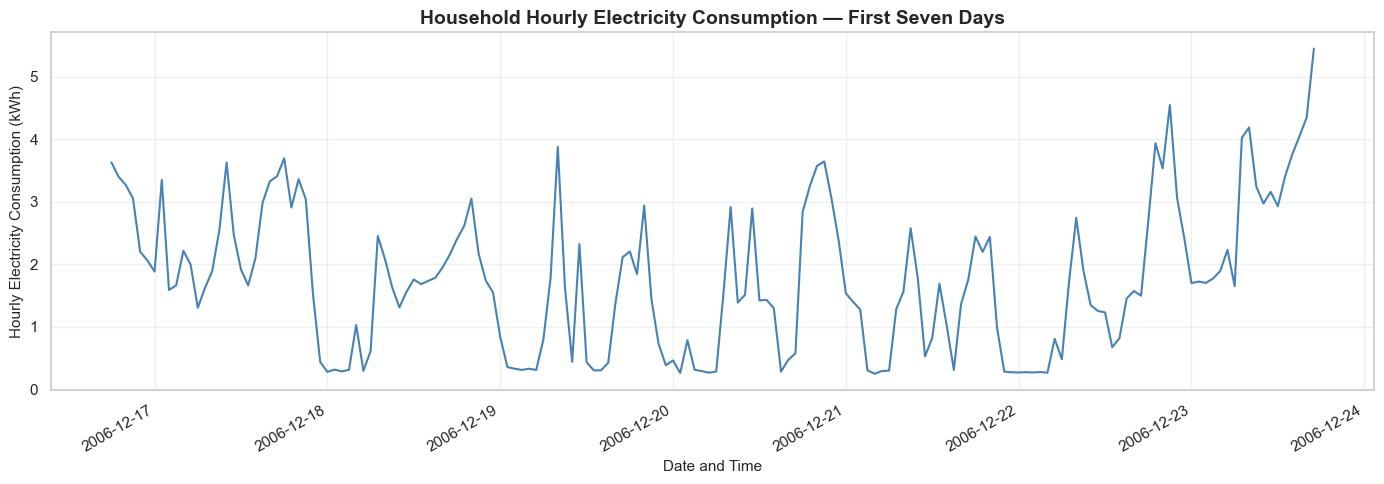

Hourly Electricity Consumption Visualization
---------------------------------------------
Complete hourly observations plotted: 168
Start date: 2006-12-16 18:00:00
End date: 2006-12-23 18:00:00
Average hourly consumption: 1.771 kWh
Maximum hourly consumption: 5.453 kWh
Minimum hourly consumption: 0.247 kWh


In [17]:
# Phase 4 - Step 4.10: Hourly Electricity Consumption Trends

import matplotlib.pyplot as plt
import pandas as pd

# Select only complete hourly observations
hourly_valid = df_hourly.loc[
    df_hourly["Complete_Hour"] &
    df_hourly["Energy_kWh"].notna()
].copy()

# Select the first seven days of available complete-hour data
start_time = hourly_valid.index.min()
end_time = start_time + pd.Timedelta(days=7)

weekly_sample = hourly_valid.loc[
    (hourly_valid.index >= start_time) &
    (hourly_valid.index < end_time)
]

# Create the visualization
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    weekly_sample.index,
    weekly_sample["Energy_kWh"],
    color="steelblue",
    linewidth=1.5
)

ax.set_title(
    "Household Hourly Electricity Consumption — First Seven Days",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date and Time", fontsize=11)
ax.set_ylabel("Hourly Electricity Consumption (kWh)", fontsize=11)

ax.grid(True, alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()

# Save visualization to the project's figure folder
fig.savefig(
    "../figure/hourly_electricity_consumption_first_week.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display summary information
print("Hourly Electricity Consumption Visualization")
print("-" * 45)
print(f"Complete hourly observations plotted: {len(weekly_sample):,}")
print(f"Start date: {start_time}")
print(f"End date: {end_time}")
print(f"Average hourly consumption: {weekly_sample['Energy_kWh'].mean():.3f} kWh")
print(f"Maximum hourly consumption: {weekly_sample['Energy_kWh'].max():.3f} kWh")
print(f"Minimum hourly consumption: {weekly_sample['Energy_kWh'].min():.3f} kWh")

#### Interpretation of Hourly Electricity Consumption

The first seven days of complete hourly electricity consumption
observations reveal substantial fluctuations in household energy use.

Across the 168 hourly observations, average electricity consumption
was approximately 1.771 kWh per hour, with a minimum of 0.247 kWh
and a maximum of 5.453 kWh.

The time-series visualization shows alternating periods of relatively
low electricity consumption and pronounced consumption peaks.

These variations may reflect differences in household activity,
appliance usage, and daily electricity demand.

However, the observed patterns cannot be attributed to specific
household activities without additional contextual information.

The results demonstrate the importance of examining daily and
weekly consumption patterns to better understand electricity demand
and support subsequent forecasting analysis.

### 4.11 Daily Electricity Consumption Analysis

This section examines daily household electricity consumption by
aggregating the previously calculated hourly energy measurements.

Daily energy consumption is expressed in kilowatt-hours (kWh).

To ensure reliable daily totals, a day is considered complete only
when all 24 hourly intervals contain valid energy measurements.

Incomplete days are retained for data-quality assessment but
excluded from calculations requiring complete daily consumption.

The analysis provides a foundation for identifying daily consumption
patterns, variability, and longer-term electricity demand trends.

In [18]:
# Phase 4 - Step 4.11: Daily Electricity Consumption Analysis

import pandas as pd

# Identify valid hourly energy observations
valid_hourly_energy = df_hourly["Energy_kWh"].where(
    df_hourly["Complete_Hour"]
)

# Aggregate hourly energy into daily totals
df_daily = pd.DataFrame({
    "Energy_kWh": valid_hourly_energy.resample("D").sum(min_count=24),
    "Valid_Hours": valid_hourly_energy.resample("D").count()
})

# Identify days with all 24 valid hourly observations
df_daily["Complete_Day"] = df_daily["Valid_Hours"].eq(24)

# Explicitly exclude incomplete days from daily energy totals
df_daily.loc[
    ~df_daily["Complete_Day"], "Energy_kWh"
] = float("nan")

# Summarize daily data quality
total_days = len(df_daily)
complete_days = int(df_daily["Complete_Day"].sum())
incomplete_days = total_days - complete_days

print("Daily Electricity Consumption Aggregation")
print("-" * 50)

print(f"Total calendar days: {total_days:,}")
print(f"Complete days: {complete_days:,}")
print(f"Incomplete days: {incomplete_days:,}")

print(
    f"Daily completeness rate: "
    f"{complete_days / total_days * 100:.2f}%"
)

print("\nFirst ten daily observations:")
display(df_daily.head(10))

# Validate daily aggregation
print("\nDaily Aggregation Validation")
print("-" * 50)

print(
    "All complete days contain 24 valid hours:",
    df_daily.loc[
        df_daily["Complete_Day"], "Valid_Hours"
    ].eq(24).all()
)

print(
    "Incomplete days have missing daily energy:",
    df_daily.loc[
        ~df_daily["Complete_Day"], "Energy_kWh"
    ].isna().all()
)

print(
    "Complete days have valid daily energy:",
    df_daily.loc[
        df_daily["Complete_Day"], "Energy_kWh"
    ].notna().all()
)

Daily Electricity Consumption Aggregation
--------------------------------------------------
Total calendar days: 1,442
Complete days: 1,410
Incomplete days: 32
Daily completeness rate: 97.78%

First ten daily observations:


,Energy_kWh,Valid_Hours,Complete_Day
Datetime,,,
2006-12-16,NaN,6,False
2006-12-17,56.507667,24,True
2006-12-18,36.730433,24,True
2006-12-19,27.769900,24,True
2006-12-20,37.095800,24,True
2006-12-21,28.618567,24,True
2006-12-22,39.022300,24,True
2006-12-23,79.556433,24,True
2006-12-24,42.500200,24,True



Daily Aggregation Validation
--------------------------------------------------
All complete days contain 24 valid hours: True
Incomplete days have missing daily energy: True
Complete days have valid daily energy: True



### 4.12 Daily Electricity Consumption Trends

This section visualizes daily household electricity consumption
across the complete observation period.

Only days containing 24 valid hourly energy measurements are
included in the analysis.

The visualization examines long-term consumption variability,
periods of elevated electricity demand, and potential changes
in household electricity usage over time.

A 30-day rolling average is included to highlight longer-term
patterns while reducing short-term fluctuations.


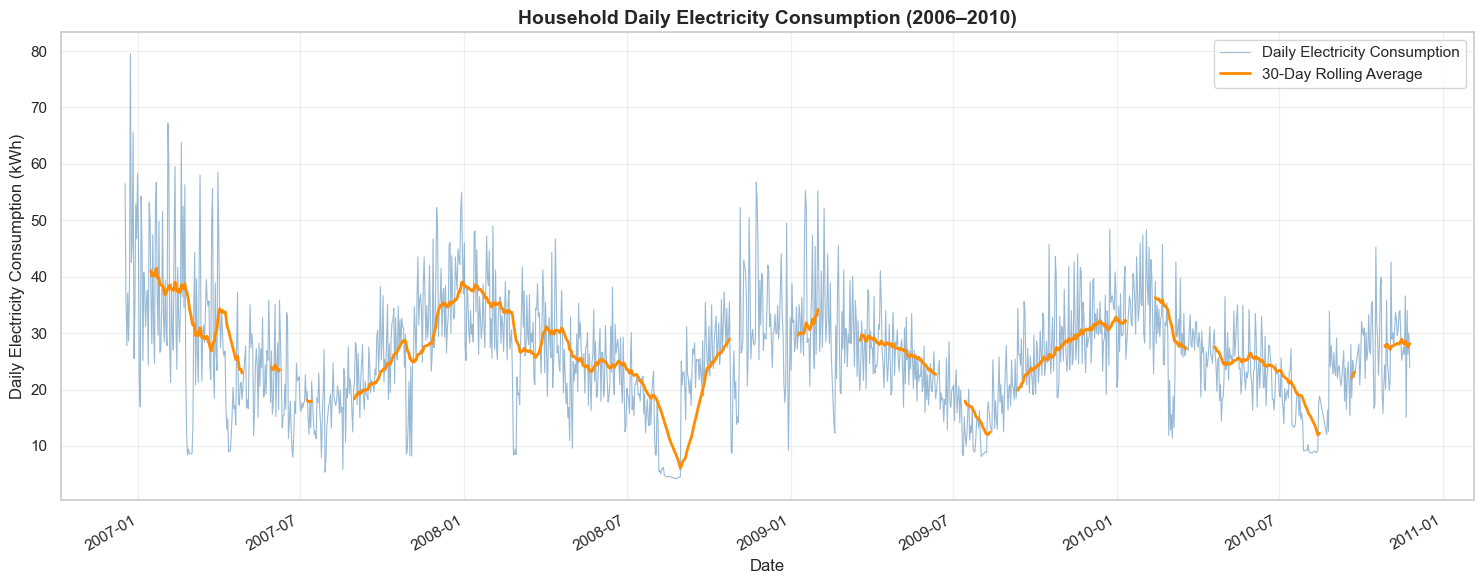

Daily Electricity Consumption Summary
---------------------------------------------
Complete days analyzed: 1,410
Average daily consumption: 26.202 kWh
Median daily consumption: 25.937 kWh
Maximum daily consumption: 79.556 kWh
Minimum daily consumption: 4.172 kWh
Standard deviation: 10.009 kWh


In [19]:

# Phase 4 - Step 4.12: Daily Electricity Consumption Trends

import matplotlib.pyplot as plt

# Select complete daily energy observations
daily_valid = df_daily.loc[
    df_daily["Complete_Day"], "Energy_kWh"
].copy()

# Calculate a 30-day rolling average
# Require at least 30 valid daily observations
daily_rolling_30 = df_daily["Energy_kWh"].rolling(
    window=30,
    min_periods=30
).mean()

# Create the visualization
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    daily_valid.index,
    daily_valid,
    color="steelblue",
    linewidth=0.8,
    alpha=0.55,
    label="Daily Electricity Consumption"
)

ax.plot(
    daily_rolling_30.index,
    daily_rolling_30,
    color="darkorange",
    linewidth=2,
    label="30-Day Rolling Average"
)

ax.set_title(
    "Household Daily Electricity Consumption (2006–2010)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Date")
ax.set_ylabel("Daily Electricity Consumption (kWh)")

ax.grid(True, alpha=0.3)
ax.legend()

fig.autofmt_xdate()
plt.tight_layout()

# Export the figure
fig.savefig(
    "../figure/daily_electricity_consumption_trends.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display descriptive statistics
print("Daily Electricity Consumption Summary")
print("-" * 45)
print(f"Complete days analyzed: {len(daily_valid):,}")
print(f"Average daily consumption: {daily_valid.mean():.3f} kWh")
print(f"Median daily consumption: {daily_valid.median():.3f} kWh")
print(f"Maximum daily consumption: {daily_valid.max():.3f} kWh")
print(f"Minimum daily consumption: {daily_valid.min():.3f} kWh")
print(f"Standard deviation: {daily_valid.std():.3f} kWh")



### 4.13 Daily Electricity Consumption by Day of the Week

This section investigates variations in household electricity
consumption across the seven days of the week.

Only complete daily observations are included to ensure that
missing measurements do not underestimate electricity usage.

The analysis compares average daily electricity consumption
from Monday to Sunday and provides an initial assessment of
weekday and weekend consumption patterns.


In [20]:

# Phase 4 - Step 4.13: Day-of-Week Consumption Analysis

import pandas as pd

# Use only complete daily observations
daily_weekday = df_daily.loc[
    df_daily["Complete_Day"], ["Energy_kWh"]
].copy()

# Extract day-of-week information
daily_weekday["Day_of_Week"] = daily_weekday.index.day_name()

# Define chronological weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Calculate descriptive statistics by weekday
weekday_summary = (
    daily_weekday.groupby("Day_of_Week")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .reindex(weekday_order)
)

# Rename columns for readability
weekday_summary.columns = [
    "Number_of_Days",
    "Mean_kWh",
    "Median_kWh",
    "Std_kWh"
]

print("Daily Electricity Consumption by Day of the Week")
print("-" * 55)

display(weekday_summary.round(3))

# Identify highest and lowest average consumption days
highest_day = weekday_summary["Mean_kWh"].idxmax()
lowest_day = weekday_summary["Mean_kWh"].idxmin()

print(f"\nHighest average consumption: {highest_day}")
print(f"Lowest average consumption: {lowest_day}")



Daily Electricity Consumption by Day of the Week
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh
Day_of_Week,,,,
Monday,202,23.965,24.132,8.382
Tuesday,202,25.726,25.875,9.342
Wednesday,202,25.971,26.386,9.099
Thursday,203,23.532,23.264,8.377
Friday,204,25.028,25.022,8.254
Saturday,198,30.009,29.344,12.290
Sunday,199,29.329,27.992,11.780



Highest average consumption: Saturday
Lowest average consumption: Thursday



### 4.14 Visualization of Daily Electricity Consumption by Day of the Week

This section visualizes average household electricity consumption
for each day of the week.

The analysis uses complete daily observations to avoid
underestimating consumption due to missing measurements.

The visualization highlights differences between weekday and
weekend electricity demand.


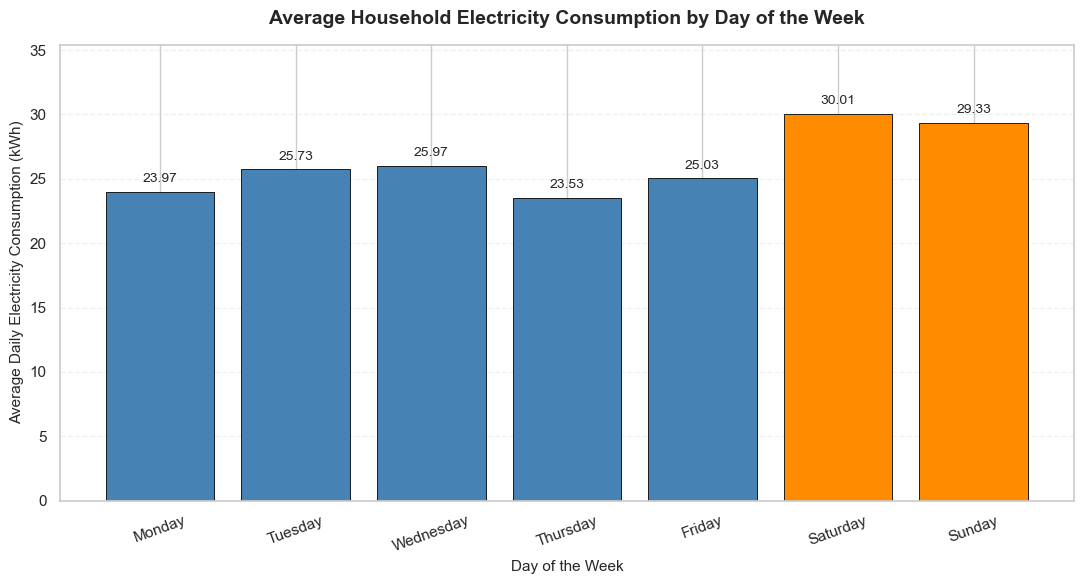

Weekday consumption visualization completed.
Figure saved to: ..\figure\weekday_electricity_consumption.png


In [21]:

# Phase 4 - Step 4.14: Weekday Electricity Consumption Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare average consumption values
weekday_means = weekday_summary["Mean_kWh"]

# Highlight Saturday and Sunday
bar_colors = [
    "steelblue" if day not in ["Saturday", "Sunday"]
    else "darkorange"
    for day in weekday_means.index
]

# Create visualization
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    weekday_means.index,
    weekday_means.values,
    color=bar_colors,
    edgecolor="black",
    linewidth=0.6
)

# Add consumption values above bars
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=10
    )

# Chart formatting
ax.set_title(
    "Average Household Electricity Consumption by Day of the Week",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Day of the Week", fontsize=11)
ax.set_ylabel("Average Daily Electricity Consumption (kWh)", fontsize=11)

ax.set_ylim(0, weekday_means.max() * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=20)
plt.tight_layout()

# Save figure to the project figure folder
figure_path = Path("../figure/weekday_electricity_consumption.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday consumption visualization completed.")
print(f"Figure saved to: {figure_path}")



### 4.15 Weekday versus Weekend Electricity Consumption Analysis

This section compares average daily household electricity
consumption between weekdays (Monday–Friday) and weekends
(Saturday–Sunday).

Only complete daily observations are considered.

The analysis calculates the average, median, standard deviation,
and percentage difference in electricity consumption between
the two groups.


In [22]:

# Phase 4 - Step 4.15: Weekday vs Weekend Analysis

# Create an independent working copy
weekend_analysis = daily_weekday.copy()

# Classify each observation
weekend_analysis["Day_Type"] = (
    weekend_analysis.index.dayofweek
    .map(lambda day: "Weekend" if day >= 5 else "Weekday")
)

# Calculate descriptive statistics
weekend_summary = (
    weekend_analysis.groupby("Day_Type")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .reindex(["Weekday", "Weekend"])
)

weekend_summary.columns = [
    "Number_of_Days",
    "Mean_kWh",
    "Median_kWh",
    "Std_kWh"
]

print("Weekday versus Weekend Electricity Consumption")
print("-" * 55)

display(weekend_summary.round(3))

# Calculate the difference in average consumption
weekday_mean = weekend_summary.loc["Weekday", "Mean_kWh"]
weekend_mean = weekend_summary.loc["Weekend", "Mean_kWh"]

absolute_difference = weekend_mean - weekday_mean

percentage_difference = (
    absolute_difference / weekday_mean
) * 100

print(f"\nWeekday average: {weekday_mean:.3f} kWh")
print(f"Weekend average: {weekend_mean:.3f} kWh")

print(
    f"Absolute difference: {absolute_difference:.3f} kWh"
)

print(
    f"Percentage difference: {percentage_difference:.2f}%"
)

print(
    "\nHigher average consumption:",
    "Weekend" if weekend_mean > weekday_mean else "Weekday"
)


Weekday versus Weekend Electricity Consumption
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh
Day_Type,,,,
Weekday,1013,24.843,24.749,8.736
Weekend,397,29.668,28.612,12.027



Weekday average: 24.843 kWh
Weekend average: 29.668 kWh
Absolute difference: 4.825 kWh
Percentage difference: 19.42%

Higher average consumption: Weekend



### 4.16 Visualization of Weekday versus Weekend Electricity Consumption

This section compares average daily household electricity
consumption between weekdays and weekends.

The visualization highlights the percentage difference in
average consumption and supports interpretation of household
electricity demand patterns.

Only complete daily observations are included.


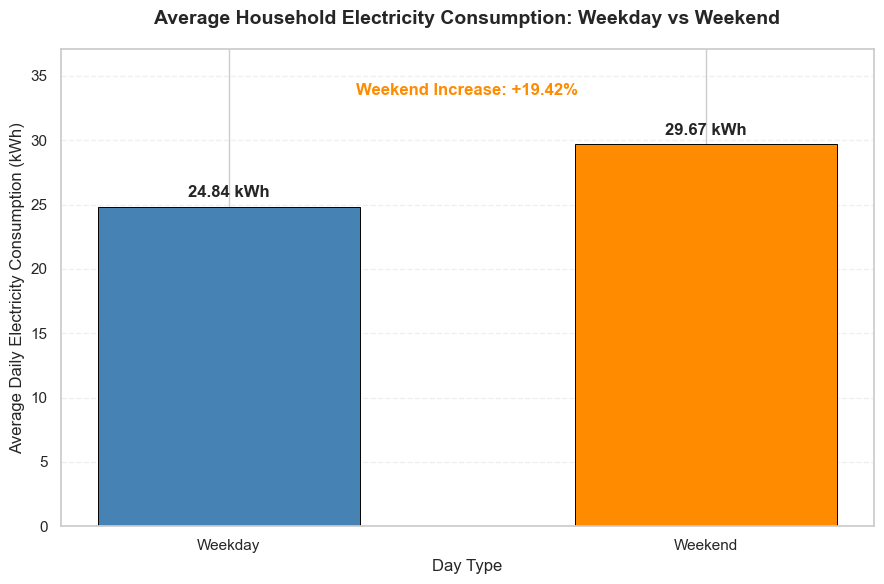

Weekday vs Weekend visualization completed.
Figure saved to: ..\figure\weekday_vs_weekend_consumption.png


In [23]:

# Phase 4 - Step 4.16: Weekday vs Weekend Visualization

import matplotlib.pyplot as plt
from pathlib import Path

# Prepare summary data
categories = ["Weekday", "Weekend"]
mean_values = weekend_summary.loc[categories, "Mean_kWh"]

# Create figure
fig, ax = plt.subplots(figsize=(9, 6))

bars = ax.bar(
    categories,
    mean_values,
    color=["steelblue", "darkorange"],
    edgecolor="black",
    width=0.55,
    linewidth=0.7
)

# Add values above each bar
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f} kWh",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

# Display percentage difference
ax.text(
    0.5,
    max(mean_values) * 1.13,
    f"Weekend Increase: {percentage_difference:+.2f}%",
    ha="center",
    fontsize=12,
    fontweight="bold",
    color="darkorange"
)

# Formatting
ax.set_title(
    "Average Household Electricity Consumption: Weekday vs Weekend",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_ylabel("Average Daily Electricity Consumption (kWh)")
ax.set_xlabel("Day Type")

ax.set_ylim(0, max(mean_values) * 1.25)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save visualization
figure_path = Path("../figure/weekday_vs_weekend_consumption.png")
figure_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday vs Weekend visualization completed.")
print(f"Figure saved to: {figure_path}")


### Monthly Electricity Consumption Analysis

This section investigates monthly variations in household electricity consumption between December 2006 and November 2010.

The analysis uses complete daily electricity consumption records to calculate monthly average daily consumption. This approach allows meaningful comparisons between months while avoiding misleading totals caused by missing observations or differences in month length.

The objectives are to:
- Identify months with higher and lower average electricity consumption.
- Examine changes in household electricity demand across the study period.
- Establish a foundation for subsequent seasonal consumption analysis.

In [24]:

# Phase 4 - Monthly Electricity Consumption Analysis
# Step 4.17: Calculate monthly consumption statistics

import pandas as pd

# Select only complete days with valid electricity consumption
daily_valid = df_daily.loc[
    df_daily["Complete_Day"] &
    df_daily["Energy_kWh"].notna(),
    ["Energy_kWh"]
].copy()

# Group daily electricity consumption by calendar month
monthly_summary = daily_valid.resample("MS").agg(
    Total_Energy_kWh=("Energy_kWh", "sum"),
    Average_Daily_kWh=("Energy_kWh", "mean"),
    Median_Daily_kWh=("Energy_kWh", "median"),
    Std_Daily_kWh=("Energy_kWh", "std"),
    Complete_Days=("Energy_kWh", "count")
)

# Count calendar days in each month within the dataset's date range
calendar_days = (
    df_daily["Energy_kWh"]
    .resample("MS")
    .size()
)

monthly_summary["Calendar_Days"] = calendar_days

# Calculate monthly data completeness
monthly_summary["Completeness_Percent"] = (
    monthly_summary["Complete_Days"]
    / monthly_summary["Calendar_Days"]
    * 100
)

# Exclude months with no complete daily observations
monthly_summary = monthly_summary.loc[
    monthly_summary["Complete_Days"] > 0
].copy()

print("Monthly Electricity Consumption Summary")
print("-" * 55)

print(f"Months analyzed: {len(monthly_summary):,}")
print(f"Complete daily observations: {len(daily_valid):,}")

print("\nFirst 12 monthly observations:")
display(monthly_summary.head(12).round(2))

print("\nLast 12 monthly observations:")
display(monthly_summary.tail(12).round(2))

print(
    f"\nAverage monthly data completeness: "
    f"{monthly_summary['Completeness_Percent'].mean():.2f}%"
)


Monthly Electricity Consumption Summary
-------------------------------------------------------
Months analyzed: 48
Complete daily observations: 1,410

First 12 monthly observations:


,Total_Energy_kWh,Average_Daily_kWh,Median_Daily_kWh,Std_Daily_kWh,Complete_Days,Calendar_Days,Completeness_Percent
Datetime,,,,,,,
2006-12-01,676.96,45.13,42.50,15.16,15,16,93.75
2007-01-01,1150.29,37.11,35.91,11.01,31,31,100.00
2007-02-01,941.61,33.63,30.85,17.28,28,28,100.00
2007-03-01,981.05,31.65,31.41,12.97,31,31,100.00
2007-04-01,578.97,21.44,18.24,9.32,27,30,90.00
2007-05-01,733.48,23.66,24.46,6.08,31,31,100.00
2007-06-01,577.15,19.90,17.87,7.59,29,30,96.67
2007-07-01,479.81,15.99,16.62,4.69,30,31,96.77
2007-08-01,550.61,18.35,18.65,4.20,30,31,96.77



Last 12 monthly observations:


,Total_Energy_kWh,Average_Daily_kWh,Median_Daily_kWh,Std_Daily_kWh,Complete_Days,Calendar_Days,Completeness_Percent
Datetime,,,,,,,
2009-12-01,1015.16,32.75,33.45,5.92,31,31,100.00
2010-01-01,958.08,34.22,34.80,6.59,28,31,90.32
2010-02-01,924.62,33.02,32.51,7.73,28,28,100.00
2010-03-01,785.11,27.07,27.72,7.34,29,31,93.55
2010-04-01,739.64,24.65,25.84,4.39,30,30,100.00
2010-05-01,814.90,26.29,25.28,4.78,31,31,100.00
2010-06-01,698.13,23.27,23.15,4.62,30,30,100.00
2010-07-01,536.51,17.31,18.06,4.48,31,31,100.00
2010-08-01,350.53,14.02,9.26,7.28,25,31,80.65



Average monthly data completeness: 97.73%


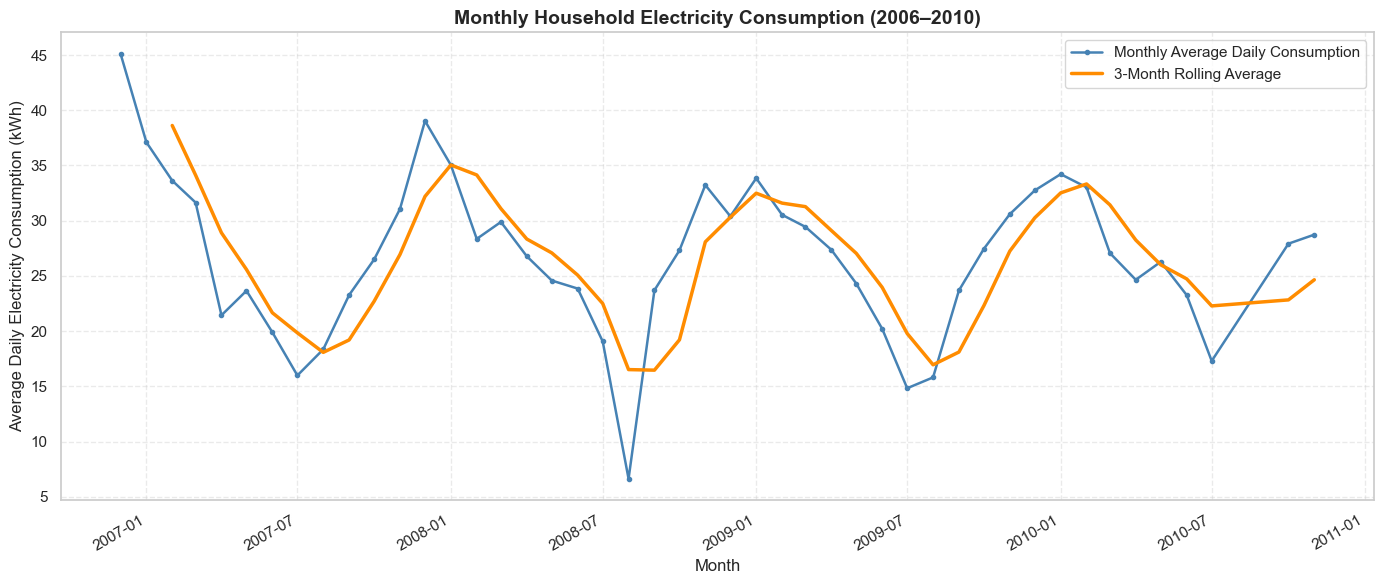

Monthly Electricity Consumption Visualization
--------------------------------------------------
Months included in visualization: 46
Months excluded (below 90% completeness): 2
Figure saved to: ../figure/monthly_electricity_consumption.png


In [25]:

# Step 4.18 - Monthly Electricity Consumption Visualization

import matplotlib.pyplot as plt

# Use average daily consumption for monthly comparisons
monthly_plot = monthly_summary[
    monthly_summary["Completeness_Percent"] >= 90
].copy()

# Calculate a 3-month rolling average
monthly_plot["Rolling_3_Months"] = (
    monthly_plot["Average_Daily_kWh"]
    .rolling(window=3, min_periods=3)
    .mean()
)

# Create visualization
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    monthly_plot.index,
    monthly_plot["Average_Daily_kWh"],
    color="steelblue",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="Monthly Average Daily Consumption"
)

ax.plot(
    monthly_plot.index,
    monthly_plot["Rolling_3_Months"],
    color="darkorange",
    linewidth=2.5,
    label="3-Month Rolling Average"
)

ax.set_title(
    "Monthly Household Electricity Consumption (2006–2010)",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Month")
ax.set_ylabel("Average Daily Electricity Consumption (kWh)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)

fig.autofmt_xdate()
plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/monthly_electricity_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly Electricity Consumption Visualization")
print("-" * 50)
print(f"Months included in visualization: {len(monthly_plot)}")
print(f"Months excluded (below 90% completeness): {len(monthly_summary) - len(monthly_plot)}")
print("Figure saved to: ../figure/monthly_electricity_consumption.png")



### Interpretation of Monthly Electricity Consumption

The monthly electricity consumption analysis reveals substantial variation in household electricity demand between December 2006 and November 2010.

**Key findings:**

1. **Seasonal consumption patterns:** Average daily electricity consumption generally increases during colder months and decreases during warmer months, suggesting a possible relationship between electricity demand and seasonal household activities.

2. **Recurring annual variation:** Similar consumption patterns occur across multiple years, indicating that seasonal effects may contribute to changes in electricity demand.

3. **Unusual consumption periods:** A pronounced reduction in electricity consumption is visible during 2008. Further investigation is required to determine whether this reflects household behavior, data availability, or other factors.

4. **Data completeness:** Of the 48 calendar months represented in the dataset, 46 satisfied the minimum 90% completeness threshold used for visualization.

**Analytical implication:**

The recurring monthly patterns suggest that calendar-related features, particularly month and season, may be useful predictors in subsequent electricity demand forecasting models. However, these relationships should be evaluated quantitatively before drawing firm conclusions.


### Seasonal Electricity Consumption Analysis

This section examines how household electricity consumption varies across the four meteorological seasons: winter, spring, summer, and autumn.

The analysis uses complete daily electricity consumption records to calculate seasonal averages, medians, standard deviations, and observation counts.

The objectives are to:
- Compare average daily electricity consumption across seasons.
- Identify the seasons with the highest and lowest electricity demand.
- Examine variability in household electricity consumption.
- Assess whether seasonal patterns may be useful for electricity demand forecasting.

In [26]:

# Step 4.19 - Seasonal Electricity Consumption Statistics

import pandas as pd

# Use complete daily electricity consumption records
seasonal_daily = daily_valid[["Energy_kWh"]].copy()

# Extract calendar month
seasonal_daily["Month"] = seasonal_daily.index.month

# Assign meteorological seasons
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

seasonal_daily["Season"] = seasonal_daily["Month"].map(season_map)

# Define logical season order
season_order = ["Winter", "Spring", "Summer", "Autumn"]

# Calculate seasonal statistics
seasonal_summary = (
    seasonal_daily.groupby("Season")["Energy_kWh"]
    .agg(
        Number_of_Days="count",
        Mean_kWh="mean",
        Median_kWh="median",
        Std_kWh="std",
        Minimum_kWh="min",
        Maximum_kWh="max"
    )
    .reindex(season_order)
)

print("Seasonal Electricity Consumption Summary")
print("-" * 55)

display(seasonal_summary.round(3))

# Identify highest and lowest average consumption
highest_season = seasonal_summary["Mean_kWh"].idxmax()
lowest_season = seasonal_summary["Mean_kWh"].idxmin()

print(f"\nHighest average consumption: {highest_season}")
print(f"Lowest average consumption: {lowest_season}")

print(
    f"Difference between highest and lowest seasonal averages: "
    f"{seasonal_summary['Mean_kWh'].max() - seasonal_summary['Mean_kWh'].min():.3f} kWh"
)

print(
    f"\nTotal complete days analyzed: "
    f"{seasonal_summary['Number_of_Days'].sum():,}"
)


Seasonal Electricity Consumption Summary
-------------------------------------------------------


,Number_of_Days,Mean_kWh,Median_kWh,Std_kWh,Minimum_kWh,Maximum_kWh
Season,,,,,,
Winter,339,34.043,33.005,10.328,8.362,79.556
Spring,363,26.482,26.332,7.530,8.595,58.492
Summer,355,17.425,17.870,6.769,4.172,38.152
Autumn,353,27.211,26.292,7.496,8.209,56.790



Highest average consumption: Winter
Lowest average consumption: Summer
Difference between highest and lowest seasonal averages: 16.618 kWh

Total complete days analyzed: 1,410


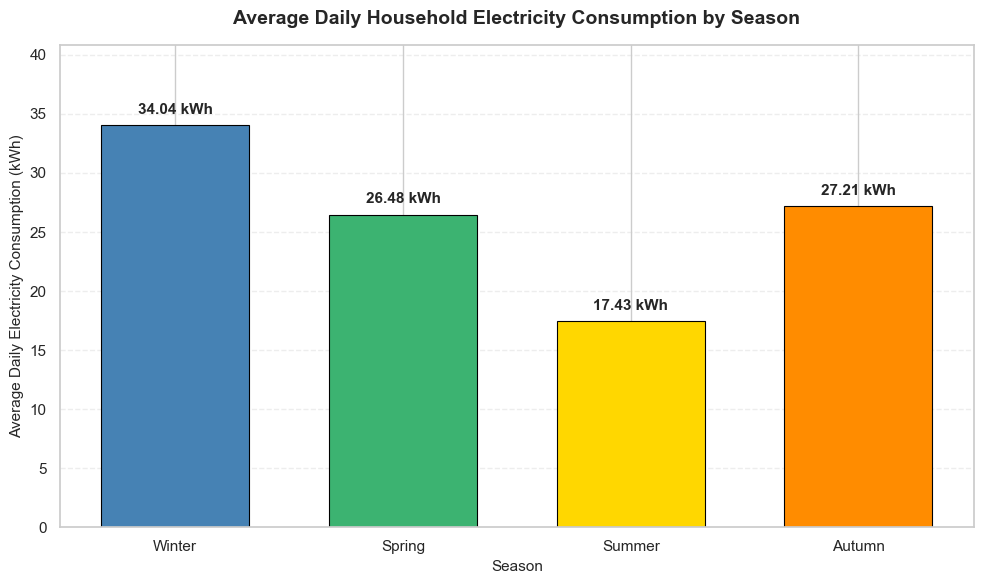

Seasonal electricity consumption visualization completed.
Figure saved to: ../figure/seasonal_electricity_consumption.png


In [27]:

# Step 4.20 - Seasonal Electricity Consumption Visualization

import matplotlib.pyplot as plt

# Extract seasonal averages
seasons = seasonal_summary.index
average_consumption = seasonal_summary["Mean_kWh"]

# Assign colors to the four seasons
colors = ["steelblue", "mediumseagreen", "gold", "darkorange"]

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    seasons,
    average_consumption,
    color=colors,
    edgecolor="black",
    linewidth=0.8,
    width=0.65
)

# Add values above each bar
for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.2f} kWh",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

# Chart formatting
ax.set_title(
    "Average Daily Household Electricity Consumption by Season",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Season", fontsize=11)
ax.set_ylabel("Average Daily Electricity Consumption (kWh)", fontsize=11)

ax.set_ylim(0, average_consumption.max() * 1.2)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/seasonal_electricity_consumption.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Seasonal electricity consumption visualization completed.")
print("Figure saved to: ../figure/seasonal_electricity_consumption.png")


### 4.21 Interpretation of Seasonal Electricity Consumption

The seasonal analysis reveals substantial variation in household electricity consumption throughout the year.

**Key findings:**

- **Winter:** Average daily electricity consumption is highest at **34.04 kWh**, suggesting increased demand for household electrical appliances during colder months.
- **Spring:** Average daily consumption decreases to **26.48 kWh**, indicating a transition toward lower electricity demand.
- **Summer:** Average daily consumption reaches its lowest level at **17.43 kWh**, potentially reflecting reduced use of heating-related electrical appliances.
- **Autumn:** Average daily consumption increases to **27.21 kWh**, suggesting electricity demand begins rising as temperatures decline.

**Seasonal variation:**

The difference between winter and summer average daily consumption is approximately **16.62 kWh**, with winter consumption approximately **95.4% higher** than summer consumption.

**Implications for electricity demand forecasting:**

These findings suggest that seasonal information may be valuable when developing electricity demand forecasting models. Calendar-based features, such as month and season, could help capture recurring variations in household electricity consumption.

However, the dataset does not contain weather measurements or appliance-level heating information sufficient to establish the exact causes of these seasonal differences.

**Conclusion:**

Seasonal electricity consumption patterns should be considered during feature engineering and model development to improve the representation of long-term demand variations.

## 5. Hourly Electricity Consumption Pattern Analysis

### 5.1 Average Electricity Consumption by Hour of Day

This section investigates how household electricity consumption varies throughout a typical 24-hour period.

The analysis uses complete hourly observations from the cleaned dataset to identify recurring electricity demand patterns.

**Objectives:**
- Calculate average electricity consumption for each hour of the day.
- Identify peak electricity consumption hours.
- Identify periods of relatively low electricity consumption.
- Examine daily demand patterns relevant to electricity forecasting.

In [28]:
# Section 5.1.1 - Average Electricity Consumption by Hour of Day

import pandas as pd

# Select only complete hourly observations
hourly_complete = df_hourly.loc[
    df_hourly["Complete_Hour"] & df_hourly["Energy_kWh"].notna()
].copy()

# Extract the hour of the day (0 to 23)
hourly_complete["Hour_of_Day"] = hourly_complete.index.hour

# Calculate average electricity consumption for each hour
hourly_profile = (
    hourly_complete.groupby("Hour_of_Day")["Energy_kWh"]
    .agg(["count", "mean", "median", "std"])
    .rename(columns={
        "count": "Number_of_Hours",
        "mean": "Mean_kWh",
        "median": "Median_kWh",
        "std": "Std_kWh"
    })
    .reindex(range(24))
)

# Display the hourly consumption summary
print("Average Household Electricity Consumption by Hour of Day")
print("-" * 60)

display(hourly_profile.round(3))

# Identify peak and off-peak consumption hours
peak_hour = hourly_profile["Mean_kWh"].idxmax()
lowest_hour = hourly_profile["Mean_kWh"].idxmin()

print(f"\nPeak consumption hour: {peak_hour:02d}:00")
print(f"Average consumption at peak hour: {hourly_profile.loc[peak_hour, 'Mean_kWh']:.3f} kWh")

print(f"\nLowest consumption hour: {lowest_hour:02d}:00")
print(f"Average consumption at lowest hour: {hourly_profile.loc[lowest_hour, 'Mean_kWh']:.3f} kWh")

Average Household Electricity Consumption by Hour of Day
------------------------------------------------------------


,Number_of_Hours,Mean_kWh,Median_kWh,Std_kWh
Hour_of_Day,,,,
0,1424,0.659,0.392,0.618
1,1424,0.539,0.347,0.501
2,1424,0.481,0.332,0.410
3,1422,0.445,0.325,0.357
4,1422,0.444,0.325,0.344
5,1421,0.454,0.323,0.354
6,1421,0.792,0.679,0.513
7,1421,1.502,1.580,0.894
8,1421,1.461,1.488,0.753



Peak consumption hour: 20:00
Average consumption at peak hour: 1.899 kWh

Lowest consumption hour: 04:00
Average consumption at lowest hour: 0.444 kWh


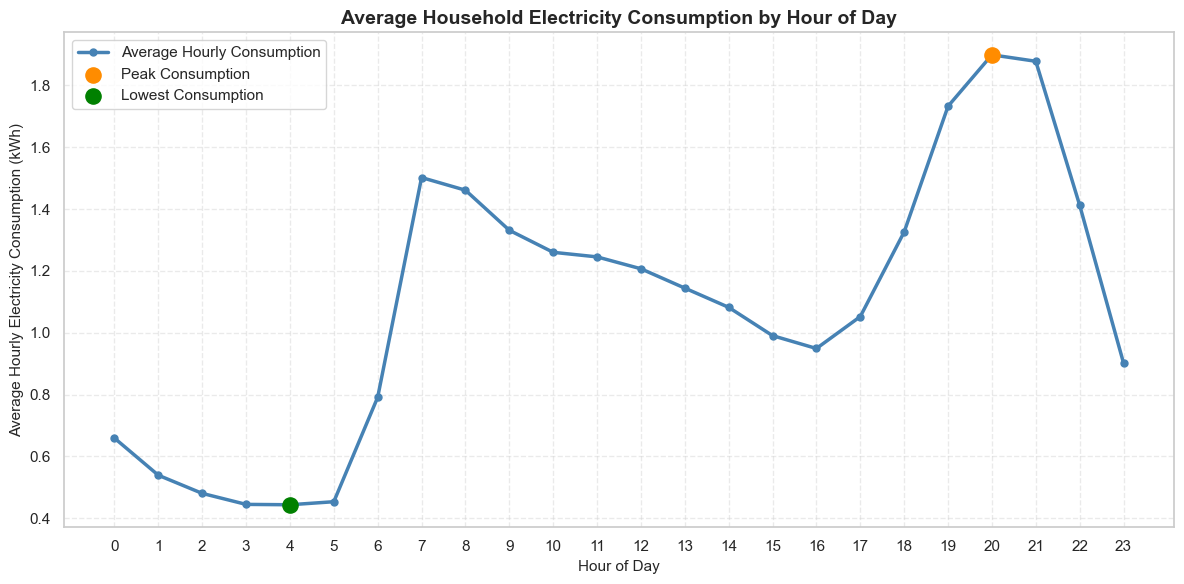

Hourly consumption profile visualization completed.
Figure saved to: ../figure/hourly_consumption_profile.png


In [29]:
# Section 5.1.2 - Hourly Electricity Consumption Profile

import matplotlib.pyplot as plt

# Average consumption for each hour
hours = hourly_profile.index
average_consumption = hourly_profile["Mean_kWh"]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    hours,
    average_consumption,
    color="steelblue",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Average Hourly Consumption"
)

# Highlight peak consumption
ax.scatter(
    peak_hour,
    average_consumption.loc[peak_hour],
    color="darkorange",
    s=120,
    zorder=5,
    label="Peak Consumption"
)

# Highlight minimum consumption
ax.scatter(
    lowest_hour,
    average_consumption.loc[lowest_hour],
    color="green",
    s=120,
    zorder=5,
    label="Lowest Consumption"
)

ax.set_title(
    "Average Household Electricity Consumption by Hour of Day",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day", fontsize=11)
ax.set_ylabel("Average Hourly Electricity Consumption (kWh)", fontsize=11)

ax.set_xticks(range(24))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

# Save the figure
plt.savefig(
    "../figure/hourly_consumption_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Hourly consumption profile visualization completed.")
print("Figure saved to: ../figure/hourly_consumption_profile.png")

### Interpretation of the Hourly Electricity Consumption Profile

The hourly electricity consumption profile reveals a distinct daily
demand pattern, characterized by morning and evening consumption peaks.

- **Early morning:** Electricity consumption is lowest at 04:00,
  averaging 0.444 kWh per hour.
- **Morning:** Consumption increases substantially between 06:00
  and 08:00, suggesting increased household activity.
- **Afternoon:** Electricity consumption gradually declines from
  the morning peak.
- **Evening:** Consumption increases again, reaching its highest
  average value of 1.899 kWh at 20:00.

The observed pattern suggests that household electricity demand
is influenced by daily routines and appliance usage.

These time-dependent consumption characteristics provide useful
information for feature engineering and electricity demand forecasting.

## 5.2 Weekday vs. Weekend Hourly Electricity Consumption

This section compares hourly household electricity consumption
patterns between weekdays (Monday–Friday) and weekends
(Saturday–Sunday).

The objective is to identify differences in electricity demand
throughout the day and determine whether day type influences
the timing of peak household electricity consumption.

In [30]:
# Section 5.2.1 - Weekday vs Weekend Hourly Consumption

# Reuse the complete hourly observations from Section 5.1
hourly_daytype = hourly_complete.copy()

# Identify weekdays and weekends
hourly_daytype["Day_of_Week"] = hourly_daytype.index.dayofweek

hourly_daytype["Day_Type"] = hourly_daytype["Day_of_Week"].map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)

# Calculate mean hourly consumption for each day type
hourly_daytype_profile = (
    hourly_daytype
    .groupby(["Hour_of_Day", "Day_Type"])["Energy_kWh"]
    .mean()
    .unstack("Day_Type")
    .reindex(range(24))
)

# Display results
print("Weekday vs Weekend Hourly Electricity Consumption")
print("-" * 60)

display(hourly_daytype_profile.round(3))

# Identify peak consumption hours
for day_type in ["Weekday", "Weekend"]:
    peak_hour = hourly_daytype_profile[day_type].idxmax()
    peak_value = hourly_daytype_profile.loc[peak_hour, day_type]

    print(
        f"{day_type} peak hour: {peak_hour:02d}:00 "
        f"| Average consumption: {peak_value:.3f} kWh"
    )

Weekday vs Weekend Hourly Electricity Consumption
------------------------------------------------------------


Day_Type,Weekday,Weekend
Hour_of_Day,,
0,0.569,0.890
1,0.468,0.721
2,0.435,0.596
3,0.412,0.530
4,0.426,0.490
5,0.431,0.512
6,0.875,0.579
7,1.715,0.961
8,1.580,1.158


Weekday peak hour: 21:00 | Average consumption: 1.856 kWh
Weekend peak hour: 19:00 | Average consumption: 2.051 kWh


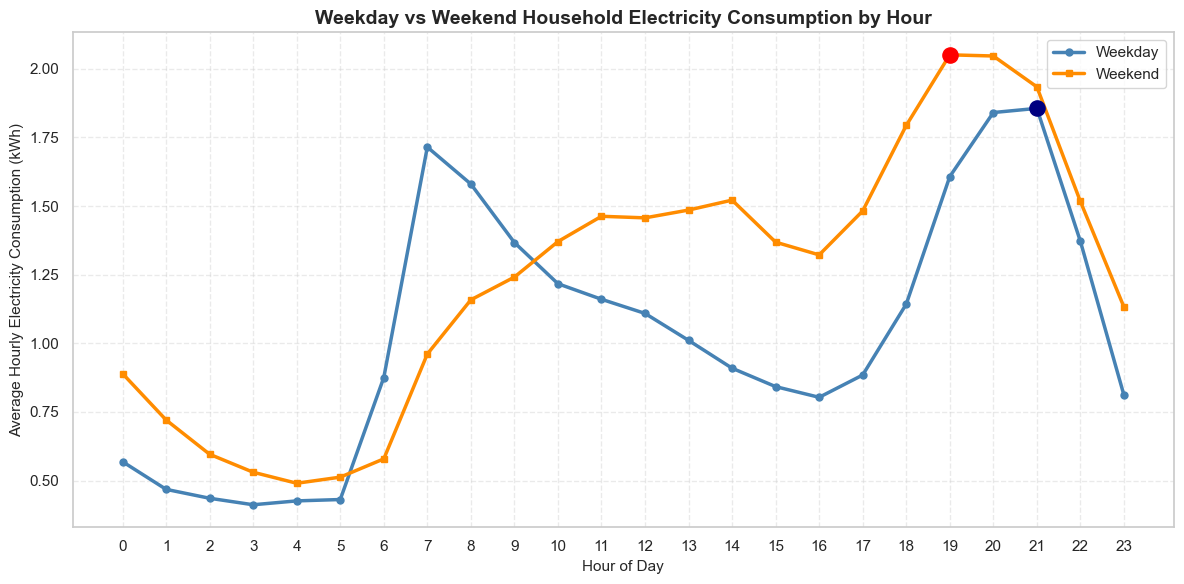

Weekday vs Weekend hourly consumption visualization completed.
Figure saved to: ../figure/weekday_weekend_hourly_profile.png


In [31]:
# Section 5.2.2 - Weekday vs Weekend Hourly Consumption

import matplotlib.pyplot as plt

hours = hourly_daytype_profile.index

fig, ax = plt.subplots(figsize=(12, 6))

# Weekday profile
ax.plot(
    hours,
    hourly_daytype_profile["Weekday"],
    color="steelblue",
    marker="o",
    linewidth=2.5,
    markersize=5,
    label="Weekday"
)

# Weekend profile
ax.plot(
    hours,
    hourly_daytype_profile["Weekend"],
    color="darkorange",
    marker="s",
    linewidth=2.5,
    markersize=5,
    label="Weekend"
)

# Identify peak hours
weekday_peak = hourly_daytype_profile["Weekday"].idxmax()
weekend_peak = hourly_daytype_profile["Weekend"].idxmax()

# Highlight weekday peak
ax.scatter(
    weekday_peak,
    hourly_daytype_profile.loc[weekday_peak, "Weekday"],
    color="navy",
    s=120,
    zorder=5
)

# Highlight weekend peak
ax.scatter(
    weekend_peak,
    hourly_daytype_profile.loc[weekend_peak, "Weekend"],
    color="red",
    s=120,
    zorder=5
)

# Chart formatting
ax.set_title(
    "Weekday vs Weekend Household Electricity Consumption by Hour",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Hour of Day", fontsize=11)
ax.set_ylabel("Average Hourly Electricity Consumption (kWh)", fontsize=11)

ax.set_xticks(range(24))
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend()

plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/weekday_weekend_hourly_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Weekday vs Weekend hourly consumption visualization completed.")
print("Figure saved to: ../figure/weekday_weekend_hourly_profile.png")

### Interpretation of Weekday and Weekend Hourly Electricity Consumption

The comparison of weekday and weekend hourly electricity consumption reveals differences in both the timing and magnitude of household electricity demand.

- **Morning consumption:** Weekday electricity demand increases sharply around 07:00, whereas weekend consumption rises more gradually during the morning.
- **Afternoon consumption:** Weekend electricity demand generally exceeds weekday demand from approximately 10:00 to 18:00.
- **Evening peak:** Weekday consumption reaches its maximum of 1.856 kWh at 21:00, while weekend consumption peaks earlier at 19:00, averaging 2.051 kWh.
- **Daily consumption patterns:** The differences suggest that household activity schedules may influence electricity demand throughout the day.

These findings demonstrate that electricity consumption patterns vary according to both the hour of day and whether the observation falls on a weekday or weekend.

Consequently, **hour of day, day of week, and weekend indicators** should be considered during feature engineering for electricity demand forecasting.

## 5.3 Hourly Electricity Consumption Patterns Across Seasons

This section examines how hourly household electricity consumption
varies across winter, spring, summer, and autumn.

Unlike the earlier seasonal analysis, which compared average daily
electricity consumption, this analysis investigates differences
in the timing and magnitude of electricity demand throughout
the 24-hour cycle.

The objective is to identify seasonal peak consumption hours
and understand how seasonal demand patterns may contribute
to electricity consumption forecasting.

In [32]:
# Section 5.3.1 - Seasonal Hourly Electricity Consumption Profiles

import pandas as pd

# Reuse complete hourly observations from Section 5.1
hourly_seasonal = hourly_complete.copy()

# Extract month from the datetime index
hourly_seasonal["Month"] = hourly_seasonal.index.month

# Define meteorological seasons
season_mapping = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

# Assign seasons
hourly_seasonal["Season"] = hourly_seasonal["Month"].map(
    season_mapping
)

# Calculate average electricity consumption by season and hour
seasonal_hourly_profile = (
    hourly_seasonal
    .groupby(["Hour_of_Day", "Season"])["Energy_kWh"]
    .mean()
    .unstack("Season")
    .reindex(
        index=range(24),
        columns=["Winter", "Spring", "Summer", "Autumn"]
    )
)

print("Seasonal Hourly Electricity Consumption Profile")
print("-" * 60)

display(seasonal_hourly_profile.round(3))

# Identify peak consumption hours for each season
print("\nSeasonal Peak Electricity Consumption")
print("-" * 60)

for season in ["Winter", "Spring", "Summer", "Autumn"]:

    peak_hour = seasonal_hourly_profile[season].idxmax()

    peak_consumption = seasonal_hourly_profile.loc[
        peak_hour, season
    ]

    print(
        f"{season}: Peak at {peak_hour:02d}:00 "
        f"| Average consumption: {peak_consumption:.3f} kWh"
    )

Seasonal Hourly Electricity Consumption Profile
------------------------------------------------------------


Season,Winter,Spring,Summer,Autumn
Hour_of_Day,,,,
0,0.844,0.620,0.580,0.602
1,0.679,0.537,0.450,0.497
2,0.606,0.492,0.378,0.453
3,0.557,0.466,0.349,0.413
4,0.565,0.444,0.362,0.409
5,0.566,0.458,0.368,0.428
6,0.981,0.808,0.557,0.829
7,1.833,1.482,0.935,1.776
8,1.869,1.422,1.013,1.560



Seasonal Peak Electricity Consumption
------------------------------------------------------------
Winter: Peak at 20:00 | Average consumption: 2.493 kWh
Spring: Peak at 21:00 | Average consumption: 2.035 kWh
Summer: Peak at 21:00 | Average consumption: 1.159 kWh
Autumn: Peak at 20:00 | Average consumption: 2.230 kWh


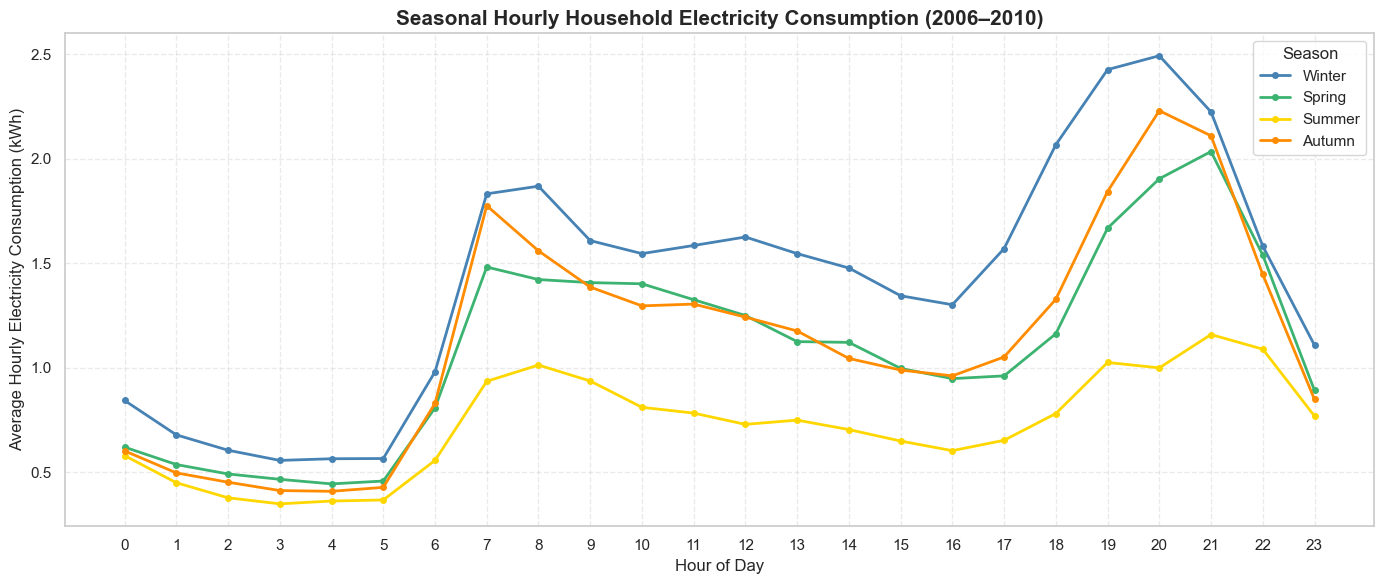

Seasonal hourly electricity consumption visualization completed.
Figure saved to: ../figure/seasonal_hourly_consumption_profile.png


In [33]:
# Section 5.3.2 - Seasonal Hourly Electricity Consumption Visualization

import matplotlib.pyplot as plt

# Define consistent seasonal colors
season_colors = {
    "Winter": "steelblue",
    "Spring": "mediumseagreen",
    "Summer": "gold",
    "Autumn": "darkorange"
}

plt.figure(figsize=(14, 6))

# Plot each seasonal hourly consumption profile
for season in ["Winter", "Spring", "Summer", "Autumn"]:

    plt.plot(
        seasonal_hourly_profile.index,
        seasonal_hourly_profile[season],
        marker="o",
        linewidth=2,
        markersize=4,
        color=season_colors[season],
        label=season
    )

# Chart formatting
plt.title(
    "Seasonal Hourly Household Electricity Consumption (2006–2010)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Average Hourly Electricity Consumption (kWh)", fontsize=12)

plt.xticks(range(24))
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Season")
plt.tight_layout()

# Save figure
plt.savefig(
    "../figure/seasonal_hourly_consumption_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Seasonal hourly electricity consumption visualization completed.")
print(
    "Figure saved to: "
    "../figure/seasonal_hourly_consumption_profile.png"
)

### 5.3.3 Interpretation of Seasonal Hourly Electricity Consumption

The seasonal hourly electricity consumption profiles reveal distinct
variations in household electricity demand across the four seasons.

**Key Findings:**

1. **Winter Consumption:** Winter exhibits the highest electricity
   consumption throughout most of the day, with a peak of approximately
   2.493 kWh at 20:00.

2. **Summer Consumption:** Summer records the lowest electricity
   consumption, with a peak of approximately 1.159 kWh at 21:00.

3. **Spring and Autumn:** Spring and autumn exhibit intermediate
   consumption patterns, with evening peaks of approximately
   2.035 kWh and 2.230 kWh, respectively.

4. **Evening Demand Peaks:** All four seasons exhibit their highest
   electricity consumption between 20:00 and 21:00, suggesting
   that evening household activities are an important driver
   of electricity demand.

5. **Seasonal Variation:** The differences between seasonal profiles
   suggest that electricity consumption is influenced by seasonal
   factors, potentially including temperature, daylight duration,
   and household routines.

**Implications for Electricity Demand Forecasting:**

These findings suggest that hour-of-day and seasonal information
should be considered as potential predictors when developing
electricity demand forecasting models.

However, the observed seasonal differences do not independently
establish the causes of electricity consumption variations.

## 5.4 Electricity Consumption Distribution and Variability Analysis

### 5.4.1 Introduction

Understanding the distribution and variability of household electricity consumption is essential for identifying typical demand levels, fluctuations, and unusually high consumption periods.

While the previous sections examined temporal patterns across days, months, seasons, and hours, this section focuses on the statistical characteristics of electricity consumption.

**Objectives:**

1. Examine the distribution of hourly electricity consumption.
2. Evaluate the variability and spread of electricity demand.
3. Identify unusually high or low consumption observations.
4. Investigate the implications of consumption variability for electricity demand forecasting.

**Analytical Approach:**

The analysis will use descriptive statistics and visualizations, including histograms and boxplots, to investigate the distribution of hourly electricity consumption.

The findings will support subsequent feature engineering, forecasting model development, and model evaluation.

In [34]:

# Section 5.4.2 - Descriptive Statistics of Hourly Electricity Consumption

import pandas as pd

# Reuse the hourly dataset already validated in earlier sections
hourly_consumption = hourly_complete["Energy_kWh"].dropna()

# Calculate descriptive statistics
consumption_statistics = hourly_consumption.describe()

# Calculate additional distribution statistics
skewness = hourly_consumption.skew()
kurtosis = hourly_consumption.kurt()

print("Hourly Electricity Consumption - Descriptive Statistics")
print("-" * 60)

display(consumption_statistics.to_frame(name="Energy_kWh").round(3))

print(f"\nSkewness: {skewness:.3f}")
print(f"Kurtosis: {kurtosis:.3f}")

print(f"\nMinimum hourly consumption: {hourly_consumption.min():.3f} kWh")
print(f"Maximum hourly consumption: {hourly_consumption.max():.3f} kWh")
print(f"Average hourly consumption: {hourly_consumption.mean():.3f} kWh")
print(f"Median hourly consumption: {hourly_consumption.median():.3f} kWh")

print(f"\nTotal complete hourly observations analyzed: {len(hourly_consumption):,}")

Hourly Electricity Consumption - Descriptive Statistics
------------------------------------------------------------


,Energy_kWh
count,34139.000
mean,1.091
std,0.898
min,0.124
25%,0.342
50%,0.803
75%,1.579
max,6.561



Skewness: 1.298
Kurtosis: 1.764

Minimum hourly consumption: 0.124 kWh
Maximum hourly consumption: 6.561 kWh
Average hourly consumption: 1.091 kWh
Median hourly consumption: 0.803 kWh

Total complete hourly observations analyzed: 34,139



### 5.4.3 Distribution of Hourly Electricity Consumption

This section examines the distribution of hourly household electricity consumption using a histogram and boxplot.

The analysis aims to identify typical consumption levels, distribution asymmetry, variability, and potential high-demand outliers. These characteristics are important when selecting and evaluating electricity demand forecasting models.


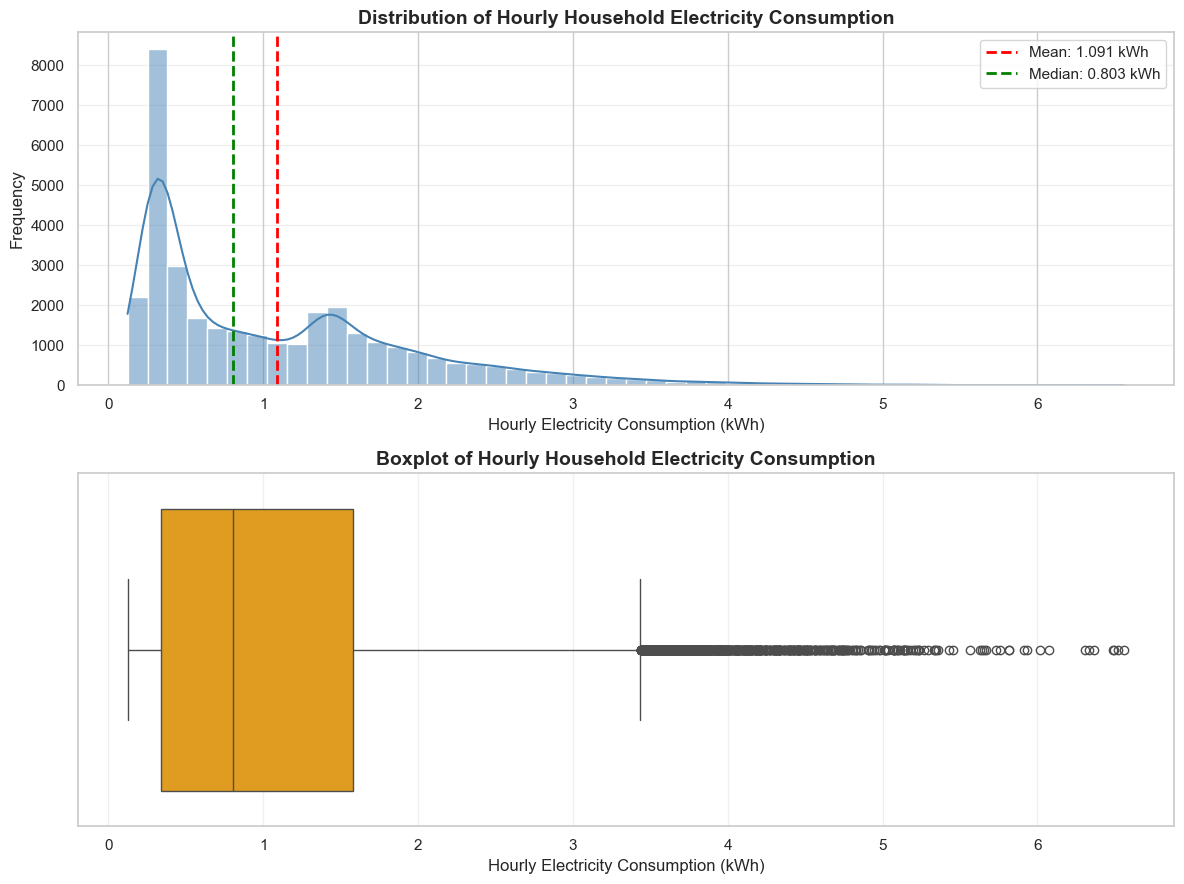

Hourly electricity consumption distribution analysis completed.
Figure saved to: ../figure/hourly_consumption_distribution.png


In [35]:

# Section 5.4.3 - Distribution of Hourly Electricity Consumption

import matplotlib.pyplot as plt
import seaborn as sns

# Reuse the validated hourly consumption series
hourly_consumption = hourly_complete["Energy_kWh"].dropna()

# Create histogram and boxplot
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

# Histogram
sns.histplot(
    hourly_consumption,
    bins=50,
    kde=True,
    color="steelblue",
    edgecolor="white",
    ax=axes[0]
)

axes[0].axvline(
    hourly_consumption.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean: {hourly_consumption.mean():.3f} kWh"
)

axes[0].axvline(
    hourly_consumption.median(),
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median: {hourly_consumption.median():.3f} kWh"
)

axes[0].set_title(
    "Distribution of Hourly Household Electricity Consumption",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_xlabel("Hourly Electricity Consumption (kWh)")
axes[0].set_ylabel("Frequency")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Boxplot
sns.boxplot(
    x=hourly_consumption,
    color="orange",
    ax=axes[1]
)

axes[1].set_title(
    "Boxplot of Hourly Household Electricity Consumption",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Hourly Electricity Consumption (kWh)")
axes[1].grid(axis="x", alpha=0.3)

plt.tight_layout()

# Save figure
figure_path = "../figure/hourly_consumption_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Hourly electricity consumption distribution analysis completed.")
print(f"Figure saved to: {figure_path}")



### Interpretation of Hourly Electricity Consumption Distribution

The distribution of hourly household electricity consumption is positively skewed, with a skewness coefficient of 1.298.

The mean hourly electricity consumption (1.091 kWh) exceeds the median (0.803 kWh), indicating that relatively high-consumption observations influence the overall average.

The histogram shows that most hourly observations are concentrated at relatively low electricity consumption levels, while a smaller number of observations extend toward substantially higher consumption values.

The boxplot reveals that the middle 50% of hourly electricity consumption observations fall between 0.342 kWh and 1.579 kWh.

Using the conventional 1.5 × interquartile range criterion, hourly consumption above approximately 3.435 kWh is classified as a potential high-consumption outlier.

However, these observations are not necessarily measurement errors. They may represent genuine periods of elevated household electricity demand and should therefore be investigated rather than automatically removed.

**Implications for forecasting:**

The positive skewness, substantial variability, and presence of high-consumption observations suggest that forecasting models should be evaluated for their ability to predict both typical electricity demand and unusually high-demand periods.



### 5.4.4 Investigation of High Electricity Consumption Observations

This subsection investigates unusually high hourly electricity consumption observations identified using the interquartile range (IQR) method.

The upper outlier threshold is calculated as:

Upper Threshold = Q3 + 1.5 × IQR

where IQR = Q3 − Q1.

Hourly electricity consumption observations exceeding this threshold are classified as potential high-consumption outliers.

The analysis determines the number and percentage of such observations and identifies the hours with the highest recorded electricity consumption.

These observations are retained for further investigation because unusually high electricity demand may represent genuine household consumption behavior rather than measurement errors.


In [36]:

# Section 5.4.4 - Investigation of High Electricity Consumption

# Use the hourly consumption series from Section 5.4.3
hourly_consumption = hourly_complete["Energy_kWh"].dropna()

# Calculate quartiles and interquartile range
q1 = hourly_consumption.quantile(0.25)
q3 = hourly_consumption.quantile(0.75)

iqr = q3 - q1

# Calculate upper outlier threshold
upper_threshold = q3 + 1.5 * iqr

# Identify high-consumption observations
high_consumption_hours = hourly_consumption[
    hourly_consumption > upper_threshold
]

# Calculate frequency and percentage
total_hours = len(hourly_consumption)
high_hours_count = len(high_consumption_hours)
high_hours_percentage = (high_hours_count / total_hours) * 100

print("HIGH ELECTRICITY CONSUMPTION ANALYSIS")
print("-" * 50)

print(f"Total valid hourly observations: {total_hours:,}")
print(f"First quartile (Q1): {q1:.3f} kWh")
print(f"Third quartile (Q3): {q3:.3f} kWh")
print(f"Interquartile range (IQR): {iqr:.3f} kWh")
print(f"Upper outlier threshold: {upper_threshold:.3f} kWh")

print(f"\nHigh-consumption hours: {high_hours_count:,}")
print(f"Percentage of high-consumption hours: {high_hours_percentage:.2f}%")

print("\nTOP 10 HIGHEST ELECTRICITY CONSUMPTION HOURS")
print("-" * 50)

display(
    high_consumption_hours
    .nlargest(10)
    .rename("Energy_kWh")
    .to_frame()
)


HIGH ELECTRICITY CONSUMPTION ANALYSIS
--------------------------------------------------
Total valid hourly observations: 34,139
First quartile (Q1): 0.342 kWh
Third quartile (Q3): 1.579 kWh
Interquartile range (IQR): 1.237 kWh
Upper outlier threshold: 3.435 kWh

High-consumption hours: 732
Percentage of high-consumption hours: 2.14%

TOP 10 HIGHEST ELECTRICITY CONSUMPTION HOURS
--------------------------------------------------


,Energy_kWh
Datetime,
2008-11-23 18:00:00,6.560533
2009-01-16 20:00:00,6.519633
2008-02-02 19:00:00,6.496033
2007-12-23 19:00:00,6.488000
2007-02-22 21:00:00,6.363867
2007-12-28 17:00:00,6.333667
2008-11-23 20:00:00,6.310567
2007-01-21 20:00:00,6.076567
2008-01-26 19:00:00,6.013800



### Interpretation of High Electricity Consumption Observations

The analysis identified 732 high-consumption hours among 34,139 valid hourly observations, representing approximately 2.14% of the dataset.

Using the interquartile range (IQR) method, hourly electricity consumption exceeding 3.435 kWh was classified as unusually high.

The maximum recorded hourly electricity consumption was approximately 6.561 kWh, observed on November 23, 2008, at 18:00.

An examination of the ten highest-consumption observations revealed that all occurred between 17:00 and 21:00, suggesting a possible association between extreme electricity demand and evening household activities.

Additionally, the ten highest observations occurred during November, December, January, and February, suggesting a potential seasonal influence on peak electricity consumption.

However, these observations alone are insufficient to establish a general relationship between peak demand, time of day, and season. Further analysis would be required to confirm these patterns.

The identified high-consumption observations are retained because they may represent genuine electricity demand events rather than measurement errors.

**Implications for Forecasting**

Although unusually high-consumption observations account for a relatively small proportion of the dataset, they may be important when evaluating forecasting performance, particularly during peak-demand periods.



### 5.4.5 Correlation Analysis of Household Electricity Measurements

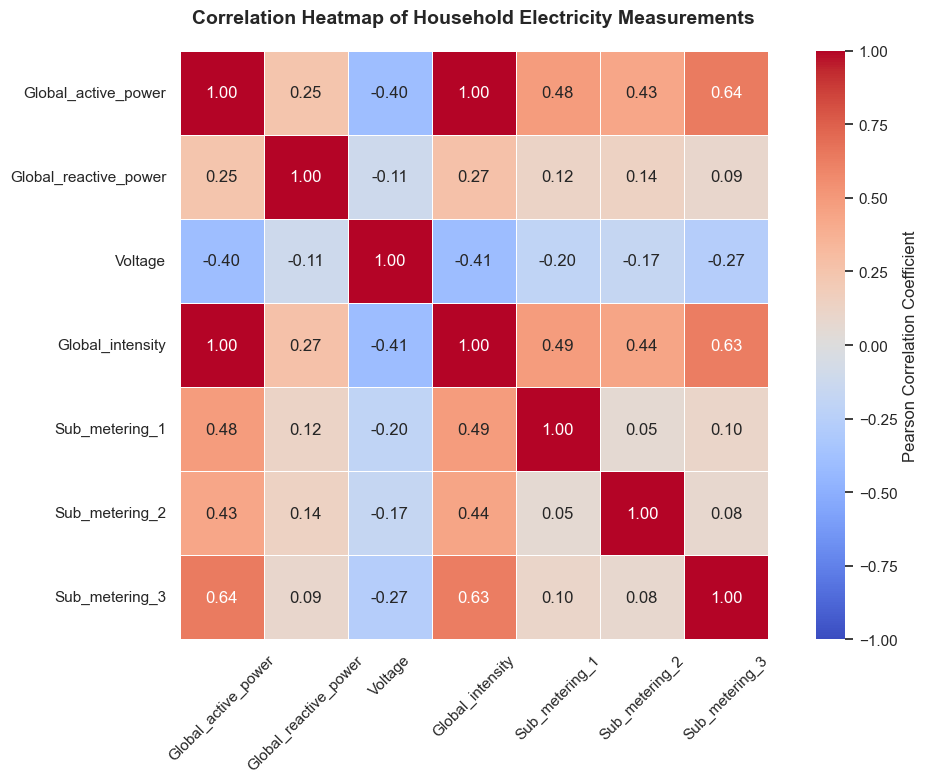

Correlation heatmap saved to: ..\figure\household_electricity_correlation_heatmap.png


In [37]:

# Correlation Heatmap of Household Electricity Measurements

# Select the seven electricity measurement variables
correlation_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Calculate Pearson correlation coefficients
correlation_matrix = df_eda[correlation_columns].corr(
    method="pearson"
)

# Set visualization style
sns.set_theme(style="white")

fig, ax = plt.subplots(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
    ax=ax
)

ax.set_title(
    "Correlation Heatmap of Household Electricity Measurements",
    fontsize=14,
    fontweight="bold",
    pad=20
)

ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

# Save visualization
figure_dir = Path("../figure")
figure_dir.mkdir(parents=True, exist_ok=True)

figure_path = (
    figure_dir /
    "household_electricity_correlation_heatmap.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved to:", figure_path)



#### Interpretation of the Correlation Heatmap

The Pearson correlation heatmap reveals several important relationships among household electricity measurements.

**1. Strong Relationship Between Active Power and Current Intensity**

Global active power and global current intensity exhibit an almost perfect positive correlation (r ≈ 1.00). This indicates that both measurements vary closely together and contain substantially overlapping information.

**2. Relationship Between Active Power and Sub-Metering Measurements**

Global active power exhibits positive correlations with all three sub-metering measurements:

- Sub-metering 1: r = 0.48
- Sub-metering 2: r = 0.43
- Sub-metering 3: r = 0.64

Sub-metering 3 demonstrates the strongest association with overall active power among the three sub-metering categories.

**3. Negative Relationship Between Voltage and Electricity Demand**

Voltage exhibits a moderate negative correlation with global active power (r = -0.40) and current intensity (r = -0.41).

This indicates that periods of higher household electricity demand tend to coincide with lower recorded voltage.

**4. Weak Relationships Between Sub-Metering Categories**

The correlations between individual sub-metering measurements are relatively weak.

For example, Sub-metering 1 and Sub-metering 2 have a correlation coefficient of approximately 0.05, suggesting limited linear association between these appliance groups.

**5. Implications for Electricity Consumption Forecasting**

The correlation analysis demonstrates that household electricity measurements exhibit varying degrees of linear association.

The strong relationship between active power and current intensity highlights potential feature redundancy, while the relationships involving sub-metering measurements provide insight into household electricity consumption patterns.

However, correlation does not establish causation or guarantee predictive usefulness.

Future forecasting experiments could investigate lagged appliance-level measurements while ensuring that all predictors are available at the time of forecasting.

**Overall Conclusion**

The correlation heatmap provides additional evidence that household electricity consumption is associated with several electrical measurements, particularly current intensity and sub-metering consumption.

These findings complement the temporal patterns identified during exploratory data analysis and provide useful context for future forecasting model development.



## 5.5 Summary of Household Electricity Consumption Patterns

The exploratory analysis of household electricity consumption revealed several important characteristics of electricity demand.

### Key Findings

**1. Hourly Electricity Consumption Patterns**

The hourly consumption analysis examined variations in electricity demand throughout the day, including differences between weekdays and weekends.

**2. Seasonal Electricity Consumption Patterns**

The seasonal analysis examined how hourly electricity demand varies across different periods of the year, providing a basis for investigating seasonal influences on household energy consumption.

**3. Statistical Distribution of Electricity Consumption**

The distribution of hourly electricity consumption was positively skewed, with a mean of 1.091 kWh and a median of 0.803 kWh.

The middle 50% of hourly consumption observations ranged from 0.342 kWh to 1.579 kWh, indicating substantial variability in household electricity demand.

**4. High Electricity Consumption Observations**

Using the interquartile range method, 732 hourly observations (2.14%) were identified as unusually high, exceeding the threshold of 3.435 kWh.

The ten highest-consumption observations occurred between 17:00 and 21:00, suggesting that evening periods may be associated with elevated electricity demand.

### Implications for Electricity Consumption Forecasting

The findings highlight the importance of considering:

- Hour-of-day effects and recurring daily consumption patterns.
- Differences in electricity consumption between weekdays and weekends.
- Seasonal variations in household electricity demand.
- Variability in electricity consumption and occasional high-demand periods.

These characteristics provide useful context for selecting, developing, and evaluating electricity consumption forecasting models.

The next stage of the project will focus on preparing the validated electricity consumption time series for forecasting while avoiding unnecessary duplication of earlier data-processing steps.



# 6. Electricity Consumption Forecasting

## 6.1 Forecasting Objectives and Methodology

### 6.1.1 Forecasting Objective

The objective of this section is to develop and evaluate time-series forecasting models capable of predicting household electricity consumption using historical observations.

The forecasting target is hourly electricity consumption, measured in kilowatt-hours (kWh).

The analysis will investigate whether historical consumption patterns can be used to predict future electricity demand accurately.

### 6.1.2 Forecasting Approach

The forecasting methodology will follow these stages:

1. Prepare the validated hourly electricity consumption time series.
2. Divide the dataset chronologically into training, validation, and testing periods.
3. Develop simple baseline forecasting models.
4. Develop and evaluate more advanced forecasting models.
5. Compare model performance using appropriate forecasting error metrics.
6. Visualize forecasts and interpret model performance.

### 6.1.3 Forecasting Evaluation Metrics

Forecasting performance will be evaluated using:

- **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted electricity consumption.
- **Root Mean Squared Error (RMSE):** Penalizes larger forecasting errors more heavily.
- **Mean Absolute Percentage Error (MAPE):** Measures percentage forecasting error, with caution when actual consumption values are close to zero.

### 6.1.4 Methodological Considerations

Because electricity consumption observations are time-dependent, chronological data splitting will be used instead of random splitting.

Data leakage will be avoided by ensuring that forecasting models do not use information that would be unavailable at the time of prediction.

Missing observations and incomplete hours will be handled carefully to preserve the temporal structure of the dataset.

Model performance will be assessed on previously unseen observations to evaluate forecasting accuracy and generalization.



## 6.2 Preparing the Time Series for Forecasting

### 6.2.1 Verification of the Existing Hourly Time Series

The validated hourly electricity consumption dataset developed during earlier stages of this project is used as the starting point for forecasting.

Before model development, the time series is inspected to confirm its chronological structure, observation coverage, and completeness.

This verification ensures that missing hourly observations are identified and that the temporal sequence is preserved.

The objective is to reuse the existing processed dataset without repeating earlier data cleaning or energy aggregation.


In [38]:

# Section 6.2.1 - Verify Existing Hourly Time Series

import pandas as pd

# Reuse the validated hourly dataset
forecast_series = hourly_complete["Energy_kWh"].copy()

# Ensure chronological order
forecast_series = forecast_series.sort_index()

print("HOURLY TIME SERIES VERIFICATION")
print("-" * 50)

print(f"Start date: {forecast_series.index.min()}")
print(f"End date: {forecast_series.index.max()}")

print(f"\nTotal hourly observations: {len(forecast_series):,}")
print(f"Missing consumption values: {forecast_series.isna().sum():,}")

print(f"\nIndex type: {type(forecast_series.index).__name__}")
print(f"Chronologically sorted: {forecast_series.index.is_monotonic_increasing}")
print(f"Duplicate timestamps: {forecast_series.index.duplicated().sum():,}")

# Check hourly timestamp coverage
expected_hours = pd.date_range(
    start=forecast_series.index.min(),
    end=forecast_series.index.max(),
    freq="h"
)

missing_timestamps = expected_hours.difference(forecast_series.index)

print(f"\nExpected hourly timestamps: {len(expected_hours):,}")
print(f"Missing hourly timestamps: {len(missing_timestamps):,}")

print("\nFIRST FIVE OBSERVATIONS")
display(forecast_series.head().to_frame())

print("\nLAST FIVE OBSERVATIONS")
display(forecast_series.tail().to_frame())


HOURLY TIME SERIES VERIFICATION
--------------------------------------------------
Start date: 2006-12-16 18:00:00
End date: 2010-11-26 20:00:00

Total hourly observations: 34,139
Missing consumption values: 0

Index type: DatetimeIndex
Chronologically sorted: True
Duplicate timestamps: 0

Expected hourly timestamps: 34,587
Missing hourly timestamps: 448

FIRST FIVE OBSERVATIONS


,Energy_kWh
Datetime,
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467
2006-12-16 22:00:00,2.200133



LAST FIVE OBSERVATIONS


,Energy_kWh
Datetime,
2010-11-26 16:00:00,1.067933
2010-11-26 17:00:00,1.725900
2010-11-26 18:00:00,1.573467
2010-11-26 19:00:00,1.659333
2010-11-26 20:00:00,1.163700



### 6.2.2 Restoring the Complete Hourly Time Index

The verification process identified 448 missing hourly timestamps within the forecasting period.

These gaps resulted from the exclusion of incomplete hourly observations during earlier data-quality processing.

To preserve the temporal structure required for forecasting, the validated hourly consumption series is reindexed to a complete hourly timeline.

Missing timestamps are represented as NaN values rather than being automatically filled.

This approach preserves the original validated electricity consumption measurements while allowing missing-data handling strategies to be evaluated before model development.


In [39]:

# Section 6.2.2 - Restore Complete Hourly Time Index

# Create a continuous hourly timeline
complete_hourly_index = pd.date_range(
    start=forecast_series.index.min(),
    end=forecast_series.index.max(),
    freq="h"
)

# Reindex without modifying existing consumption values
forecast_series_regular = forecast_series.reindex(
    complete_hourly_index
)

forecast_series_regular.index.name = "Datetime"
forecast_series_regular.name = "Energy_kWh"

print("RESTORED HOURLY TIME SERIES")
print("-" * 50)

print(f"Original valid observations: {forecast_series.notna().sum():,}")
print(f"Total hourly timestamps: {len(forecast_series_regular):,}")
print(f"Missing hourly values: {forecast_series_regular.isna().sum():,}")

print(
    f"Missing percentage: "
    f"{forecast_series_regular.isna().mean() * 100:.2f}%"
)

print(
    f"Hourly frequency: "
    f"{forecast_series_regular.index.freq}"
)

# Confirm that original measurements remain unchanged
assert forecast_series_regular.loc[
    forecast_series.index
].equals(forecast_series)

print("\nOriginal validated measurements preserved: True")

print("\nFIRST FIVE OBSERVATIONS")
display(forecast_series_regular.head().to_frame())


RESTORED HOURLY TIME SERIES
--------------------------------------------------
Original valid observations: 34,139
Total hourly timestamps: 34,587
Missing hourly values: 448
Missing percentage: 1.30%
Hourly frequency: <Hour>

Original validated measurements preserved: True

FIRST FIVE OBSERVATIONS


,Energy_kWh
Datetime,
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467
2006-12-16 22:00:00,2.200133



### 6.2.3 Investigation of Missing Hourly Periods

Although the hourly time index has been restored, 448 hourly observations (1.30%) contain missing electricity consumption values.

This subsection investigates the temporal distribution of these missing observations.

Specifically, the analysis identifies consecutive missing-hour periods, determines their durations, and examines the longest gaps.

Understanding the duration and frequency of missing periods is necessary before selecting an appropriate missing-data handling strategy for forecasting.

No missing values are modified during this investigation.


In [40]:

# Section 6.2.3 - Investigate Consecutive Missing Hourly Periods

import pandas as pd

# Identify missing hourly observations
missing_mask = forecast_series_regular.isna()

# Identify consecutive groups of missing and valid hours
group_ids = missing_mask.ne(missing_mask.shift()).cumsum()

# Extract missing-hour periods
missing_periods = (
    pd.DataFrame({
        "Datetime": forecast_series_regular.index,
        "Missing": missing_mask.to_numpy(),
        "Group": group_ids.to_numpy()
    })
    .loc[lambda df: df["Missing"]]
    .groupby("Group")
    .agg(
        Start=("Datetime", "min"),
        End=("Datetime", "max"),
        Duration_Hours=("Missing", "size")
    )
    .reset_index(drop=True)
)

# Sort missing periods by duration
missing_periods = missing_periods.sort_values(
    "Duration_Hours",
    ascending=False
).reset_index(drop=True)

print("MISSING HOURLY PERIOD ANALYSIS")
print("-" * 50)

print(f"Total missing hours: {missing_mask.sum():,}")
print(f"Number of missing periods: {len(missing_periods):,}")

if not missing_periods.empty:
    print(
        f"Longest consecutive gap: "
        f"{missing_periods['Duration_Hours'].max():,} hours"
    )

    print(
        f"Median gap duration: "
        f"{missing_periods['Duration_Hours'].median():.1f} hours"
    )

    print(
        f"Single-hour gaps: "
        f"{(missing_periods['Duration_Hours'] == 1).sum():,}"
    )

    print("\nTOP 10 LONGEST MISSING PERIODS")
    print("-" * 50)

    display(missing_periods.head(10))


MISSING HOURLY PERIOD ANALYSIS
--------------------------------------------------
Total missing hours: 448
Number of missing periods: 15
Longest consecutive gap: 121 hours
Median gap duration: 4.0 hours
Single-hour gaps: 3

TOP 10 LONGEST MISSING PERIODS
--------------------------------------------------


,Start,End,Duration_Hours
0,2010-08-17 21:00:00,2010-08-22 21:00:00,121
1,2010-09-25 03:00:00,2010-09-28 19:00:00,89
2,2007-04-28 00:00:00,2007-04-30 14:00:00,63
3,2009-06-13 00:00:00,2009-06-15 07:00:00,56
4,2010-01-12 14:00:00,2010-01-14 19:00:00,54
5,2010-03-20 03:00:00,2010-03-21 13:00:00,35
6,2009-08-13 05:00:00,2009-08-13 19:00:00,15
7,2007-07-15 16:00:00,2007-07-15 19:00:00,4
8,2007-06-09 17:00:00,2007-06-09 18:00:00,2
9,2008-10-25 10:00:00,2008-10-25 11:00:00,2


 
### Interpretation of Missing Hourly Periods

The missing-data investigation identified 448 missing hourly observations distributed across 15 separate periods.

The longest consecutive missing period lasted 121 hours, while the median missing-period duration was 4 hours. Three missing periods consisted of a single hour.

Several extended gaps were identified, including periods lasting 121, 89, 63, 56, and 54 consecutive hours.

These findings indicate that missing observations are concentrated in a relatively small number of interruptions rather than being uniformly distributed throughout the dataset.

Although missing observations account for only 1.30% of the complete hourly timeline, the presence of extended gaps requires careful treatment during forecasting preparation.

Long missing periods should not be automatically filled using simple interpolation because this could introduce artificial electricity consumption patterns.

The original validated measurements will be preserved, and missing-data handling will be designed to avoid using future information when constructing forecasting inputs.

The next stage will establish the forecasting horizon and chronological data partitions before implementing the final missing-data strategy.



### 6.2.4 Forecasting Horizon and Prediction Strategy

The forecasting task is defined as one-hour-ahead household electricity consumption prediction.

The objective is to predict electricity consumption for the next hour using historical consumption observations and relevant time-based information available at the prediction time.

**Forecasting Target**

Hourly household electricity consumption, measured in kilowatt-hours (kWh).

**Forecasting Horizon**

One hour ahead (t + 1).

**Prediction Strategy**

A supervised time-series forecasting approach will be adopted, in which historical electricity consumption observations are used to predict the next hourly consumption value.

Potential predictors include:

- Electricity consumption during previous hours.
- Electricity consumption at the same hour on the previous day.
- Electricity consumption at the same hour on the previous week.
- Hour of day.
- Day of week.
- Weekend indicators.
- Seasonal calendar information.

**Missing-Data Considerations**

Missing hourly consumption values will remain explicitly identified during forecasting preparation.

Historical input features will be constructed without using future observations, and missing target values will not be used to calculate forecasting errors.

**Modeling Objective**

The forecasting models will be evaluated based on their ability to predict previously unseen hourly electricity consumption observations.

Chronological training, validation, and testing partitions will be used to preserve temporal ordering and prevent data leakage.



## 6.3 Chronological Training, Validation, and Testing Split

### 6.3.1 Creating Chronological Data Partitions

The regularly indexed hourly electricity consumption series is divided chronologically into training, validation, and testing datasets.

The dataset is partitioned using the following proportions:

- Training dataset: 70%
- Validation dataset: 15%
- Testing dataset: 15%

The split is based on the complete hourly timeline, including timestamps with missing consumption values.

This preserves the temporal structure of the dataset and avoids shifting the boundaries by removing missing observations.

No random shuffling is performed.

Missing values are retained at this stage. Any subsequent missing-data treatment will be designed to avoid information leakage across the training, validation, and testing periods.


In [41]:

# Section 6.3.1 - Chronological Train/Validation/Test Split

# Use the regularly indexed hourly forecasting series
forecast_data = forecast_series_regular.copy()

# Define split proportions
train_ratio = 0.70
val_ratio = 0.15

# Calculate chronological split boundaries
n_total = len(forecast_data)

train_end = int(n_total * train_ratio)
val_end = int(n_total * (train_ratio + val_ratio))

# Create chronological partitions
train_series = forecast_data.iloc[:train_end].copy()
val_series = forecast_data.iloc[train_end:val_end].copy()
test_series = forecast_data.iloc[val_end:].copy()

print("CHRONOLOGICAL FORECASTING DATA SPLIT")
print("-" * 55)

for name, series in [
    ("Training", train_series),
    ("Validation", val_series),
    ("Testing", test_series)
]:
    print(f"\n{name.upper()} DATASET")
    print(f"Start: {series.index.min()}")
    print(f"End: {series.index.max()}")
    print(f"Total hours: {len(series):,}")
    print(f"Valid observations: {series.notna().sum():,}")
    print(f"Missing observations: {series.isna().sum():,}")

# Verify the partitions
assert len(train_series) + len(val_series) + len(test_series) == n_total

assert train_series.index.max() < val_series.index.min()
assert val_series.index.max() < test_series.index.min()

print("\nChronological split verification: PASSED")


CHRONOLOGICAL FORECASTING DATA SPLIT
-------------------------------------------------------

TRAINING DATASET
Start: 2006-12-16 18:00:00
End: 2009-09-20 11:00:00
Total hours: 24,210
Valid observations: 24,061
Missing observations: 149

VALIDATION DATASET
Start: 2009-09-20 12:00:00
End: 2010-04-24 15:00:00
Total hours: 5,188
Valid observations: 5,099
Missing observations: 89

TESTING DATASET
Start: 2010-04-24 16:00:00
End: 2010-11-26 20:00:00
Total hours: 5,189
Valid observations: 4,979
Missing observations: 210

Chronological split verification: PASSED



### 6.3.2 Verification and Interpretation of Chronological Data Partitions

The hourly electricity consumption dataset was successfully divided into chronological training, validation, and testing periods.

The training dataset contains 24,210 hourly timestamps, including 24,061 valid observations and 149 missing observations.

The validation dataset contains 5,188 hourly timestamps, including 5,099 valid observations and 89 missing observations.

The testing dataset contains 5,189 hourly timestamps, including 4,979 valid observations and 210 missing observations.

The chronological split verification passed, confirming that the training, validation, and testing periods are ordered correctly without temporal overlap.

The testing dataset contains a higher proportion of missing observations than the other partitions. This will be considered when evaluating forecasting models.

Missing target observations will be excluded from forecasting error calculations. Historical lag features will be constructed using only information available before the predicted hour.

This partitioning strategy provides the foundation for leakage-aware forecasting model development.


### 6.3.3 Constructing Lagged Forecasting Features

Lagged features are historical electricity consumption observations used as predictors of future electricity demand.

For the one-hour-ahead forecasting task, lagged features will be constructed using electricity consumption values from previous hours.

The following lag features will be considered:

- Lag 1: Electricity consumption one hour earlier.
- Lag 2: Electricity consumption two hours earlier.
- Lag 3: Electricity consumption three hours earlier.
- Lag 24: Electricity consumption at the same hour on the previous day.
- Lag 168: Electricity consumption at the same hour on the previous week.

These features capture short-term consumption behavior as well as recurring daily and weekly patterns.

Lagged features will be created using the complete hourly time index to ensure that each lag represents the correct number of elapsed hours.

Missing observations will remain as NaN values rather than being automatically replaced.

All lagged predictors will use only historical observations available before the target hour, thereby avoiding future-data leakage.


In [42]:

# Section 6.3.3 - Construct Lagged Forecasting Features

import pandas as pd

# Use the regularly indexed hourly time series
forecast_features = pd.DataFrame(
    {"Energy_kWh": forecast_series_regular.copy()}
)

# Define historical lag periods (in hours)
lag_hours = [1, 2, 3, 24, 168]

# Construct lagged features
for lag in lag_hours:
    forecast_features[f"Lag_{lag}"] = (
        forecast_features["Energy_kWh"].shift(lag)
    )

print("LAGGED FORECASTING FEATURES")
print("-" * 55)

print(f"Total hourly timestamps: {len(forecast_features):,}")
print(f"Number of lagged features: {len(lag_hours)}")

print("\nMISSING VALUES BY COLUMN")
display(forecast_features.isna().sum().to_frame("Missing_Values"))

print("\nSAMPLE OF FORECASTING FEATURES")
display(forecast_features.iloc[168:178])


LAGGED FORECASTING FEATURES
-------------------------------------------------------
Total hourly timestamps: 34,587
Number of lagged features: 5

MISSING VALUES BY COLUMN


,Missing_Values
Energy_kWh,448
Lag_1,449
Lag_2,450
Lag_3,451
Lag_24,472
Lag_168,616



SAMPLE OF FORECASTING FEATURES


,Energy_kWh,Lag_1,Lag_2,Lag_3,Lag_24,Lag_168
Datetime,,,,,,
2006-12-23 18:00:00,3.879400,5.452533,4.349100,4.049100,2.686967,3.632200
2006-12-23 19:00:00,4.117833,3.879400,5.452533,4.349100,3.938167,3.400233
2006-12-23 20:00:00,4.181400,4.117833,3.879400,5.452533,3.536067,3.268567
2006-12-23 21:00:00,3.288433,4.181400,4.117833,3.879400,4.548667,3.056467
2006-12-23 22:00:00,4.327933,3.288433,4.181400,4.117833,3.065067,2.200133
2006-12-23 23:00:00,5.562467,4.327933,3.288433,4.181400,2.419200,2.061600
2006-12-24 00:00:00,4.028000,5.562467,4.327933,3.288433,1.698233,1.882467
2006-12-24 01:00:00,3.275700,4.028000,5.562467,4.327933,1.722800,3.349400
2006-12-24 02:00:00,2.303033,3.275700,4.028000,5.562467,1.700767,1.587267



### 6.3.4 Constructing Calendar-Based Forecasting Features

Calendar-based features are introduced to capture recurring temporal patterns in household electricity consumption.

The exploratory analysis identified variations in electricity demand across different hours, weekdays, weekends, and seasons.

The following calendar features are constructed:

- Hour of day (0–23).
- Day of week (Monday = 0, Sunday = 6).
- Month of year (1–12).
- Weekend indicator (1 for Saturday or Sunday, otherwise 0).

These features are derived directly from the hourly timestamp and do not require future electricity consumption measurements.

Calendar-based features complement historical lagged consumption features and may improve the forecasting models' ability to capture recurring electricity demand patterns.


In [43]:

# Section 6.3.4 - Construct Calendar-Based Forecasting Features

# Continue using the existing forecasting feature dataset
forecast_features["Hour"] = forecast_features.index.hour

forecast_features["Day_of_Week"] = (
    forecast_features.index.dayofweek
)

forecast_features["Month"] = forecast_features.index.month

forecast_features["Is_Weekend"] = (
    forecast_features.index.dayofweek >= 5
).astype(int)

print("CALENDAR-BASED FORECASTING FEATURES")
print("-" * 55)

print(f"Total hourly timestamps: {len(forecast_features):,}")

print("\nFORECASTING FEATURE COLUMNS")
print(forecast_features.columns.tolist())

print("\nMISSING VALUES IN CALENDAR FEATURES")
calendar_columns = [
    "Hour",
    "Day_of_Week",
    "Month",
    "Is_Weekend"
]

display(
    forecast_features[calendar_columns]
    .isna()
    .sum()
    .to_frame("Missing_Values")
)

print("\nSAMPLE OF CALENDAR FEATURES")
display(
    forecast_features[
        ["Energy_kWh"] + calendar_columns
    ].head(10)
)


CALENDAR-BASED FORECASTING FEATURES
-------------------------------------------------------
Total hourly timestamps: 34,587

FORECASTING FEATURE COLUMNS
['Energy_kWh', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_24', 'Lag_168', 'Hour', 'Day_of_Week', 'Month', 'Is_Weekend']

MISSING VALUES IN CALENDAR FEATURES


,Missing_Values
Hour,0
Day_of_Week,0
Month,0
Is_Weekend,0



SAMPLE OF CALENDAR FEATURES


,Energy_kWh,Hour,Day_of_Week,Month,Is_Weekend
Datetime,,,,,
2006-12-16 18:00:00,3.632200,18,5,12,1
2006-12-16 19:00:00,3.400233,19,5,12,1
2006-12-16 20:00:00,3.268567,20,5,12,1
2006-12-16 21:00:00,3.056467,21,5,12,1
2006-12-16 22:00:00,2.200133,22,5,12,1
2006-12-16 23:00:00,2.061600,23,5,12,1
2006-12-17 00:00:00,1.882467,0,6,12,1
2006-12-17 01:00:00,3.349400,1,6,12,1
2006-12-17 02:00:00,1.587267,2,6,12,1



### 6.3.5 Preparing Forecasting Feature Matrices

The historical lag features and calendar-based features are combined to form the input variables for one-hour-ahead electricity consumption forecasting.

The forecasting target is hourly electricity consumption (Energy_kWh), while the predictor variables consist of five historical lag features and four calendar-based features.

The feature dataset is divided using the chronological training, validation, and testing boundaries established in Section 6.3.1.

Before constructing the final model-ready datasets, the availability of complete predictor values and valid target observations is assessed separately for each partition.

This assessment helps identify observations that cannot be used directly by forecasting models requiring complete numerical inputs.

No missing values are filled or removed during this verification stage.


In [44]:

# Section 6.3.5 - Verify Forecasting Feature Matrices

# Define predictor columns
feature_columns = [
    "Lag_1",
    "Lag_2",
    "Lag_3",
    "Lag_24",
    "Lag_168",
    "Hour",
    "Day_of_Week",
    "Month",
    "Is_Weekend"
]

target_column = "Energy_kWh"

# Apply existing chronological boundaries
train_features = forecast_features.loc[train_series.index].copy()
val_features = forecast_features.loc[val_series.index].copy()
test_features = forecast_features.loc[test_series.index].copy()

print("FORECASTING FEATURE MATRIX VERIFICATION")
print("-" * 55)

for name, data in [
    ("Training", train_features),
    ("Validation", val_features),
    ("Testing", test_features)
]:
    valid_target = data[target_column].notna()
    complete_predictors = data[feature_columns].notna().all(axis=1)

    model_ready = valid_target & complete_predictors

    print(f"\n{name.upper()} DATASET")
    print(f"Total timestamps: {len(data):,}")
    print(f"Valid targets: {valid_target.sum():,}")
    print(f"Complete predictor rows: {complete_predictors.sum():,}")
    print(f"Rows with valid target and predictors: {model_ready.sum():,}")
    print(f"Rows requiring missing-data handling: {(~model_ready).sum():,}")

# Confirm chronological partitioning
assert train_features.index.max() < val_features.index.min()
assert val_features.index.max() < test_features.index.min()

# Confirm all expected predictors are available
assert all(col in forecast_features.columns for col in feature_columns)

print("\nFeature matrix verification: PASSED")


FORECASTING FEATURE MATRIX VERIFICATION
-------------------------------------------------------

TRAINING DATASET
Total timestamps: 24,210
Valid targets: 24,061
Complete predictor rows: 23,650
Rows with valid target and predictors: 23,639
Rows requiring missing-data handling: 571

VALIDATION DATASET
Total timestamps: 5,188
Valid targets: 5,099
Complete predictor rows: 4,964
Rows with valid target and predictors: 4,962
Rows requiring missing-data handling: 226

TESTING DATASET
Total timestamps: 5,189
Valid targets: 4,979
Complete predictor rows: 4,723
Rows with valid target and predictors: 4,721
Rows requiring missing-data handling: 468

Feature matrix verification: PASSED



### 6.3.6 Creating the Final Model-Ready Datasets

The forecasting feature matrix verification identified 33,322 observations with complete predictor values and valid electricity consumption targets.

For the initial forecasting models, a complete-case strategy is adopted.

Observations containing missing target values or missing predictor values are excluded from the model-ready datasets.

This strategy avoids introducing artificial electricity consumption measurements, particularly across extended missing periods.

The original regularly indexed forecasting dataset remains unchanged.

Training, validation, and testing observations retain their original chronological timestamps and partition boundaries.

Because incomplete observations are excluded, the resulting model-ready datasets may contain gaps between consecutive timestamps. These gaps will be considered when interpreting forecasting performance.

The model-ready datasets will be used to train, validate, and evaluate one-hour-ahead electricity consumption forecasting models.


In [45]:

# Section 6.3.6 - Create Final Model-Ready Datasets

# Retain only rows with valid target and predictor values
train_ready = train_features.dropna(
    subset=[target_column] + feature_columns
).copy()

val_ready = val_features.dropna(
    subset=[target_column] + feature_columns
).copy()

test_ready = test_features.dropna(
    subset=[target_column] + feature_columns
).copy()

# Separate predictors (X) and target (y)
X_train = train_ready[feature_columns]
y_train = train_ready[target_column]

X_val = val_ready[feature_columns]
y_val = val_ready[target_column]

X_test = test_ready[feature_columns]
y_test = test_ready[target_column]

print("FINAL MODEL-READY FORECASTING DATASETS")
print("-" * 55)

for name, X, y in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Testing", X_test, y_test)
]:
    print(f"\n{name.upper()} DATASET")
    print(f"Predictor matrix shape: {X.shape}")
    print(f"Target vector shape: {y.shape}")
    print(f"Missing predictor values: {X.isna().sum().sum()}")
    print(f"Missing target values: {y.isna().sum()}")

# Verify feature consistency
assert X_train.columns.equals(X_val.columns)
assert X_val.columns.equals(X_test.columns)

# Verify chronological separation
assert X_train.index.max() < X_val.index.min()
assert X_val.index.max() < X_test.index.min()

# Verify predictor-target alignment
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

print("\nModel-ready dataset verification: PASSED")


FINAL MODEL-READY FORECASTING DATASETS
-------------------------------------------------------

TRAINING DATASET
Predictor matrix shape: (23639, 9)
Target vector shape: (23639,)
Missing predictor values: 0
Missing target values: 0

VALIDATION DATASET
Predictor matrix shape: (4962, 9)
Target vector shape: (4962,)
Missing predictor values: 0
Missing target values: 0

TESTING DATASET
Predictor matrix shape: (4721, 9)
Target vector shape: (4721,)
Missing predictor values: 0
Missing target values: 0

Model-ready dataset verification: PASSED



## 6.4 Baseline Electricity Consumption Forecasting

Before developing advanced machine learning forecasting models, a simple persistence baseline is established to provide a reference for evaluating predictive performance.

The persistence model assumes that electricity consumption during the next hour will be equal to the consumption observed during the preceding hour.

Mathematically:

\[
\hat{y}_t = y_{t-1}
\]

where:

- \(\hat{y}_t\) represents the predicted electricity consumption at hour \(t\).
- \(y_{t-1}\) represents the observed electricity consumption one hour earlier.

This approach requires no model training and provides a straightforward benchmark for assessing whether more sophisticated forecasting methods offer meaningful improvements.

The baseline will be evaluated using the chronological validation and testing datasets. Only observations with valid targets and available previous-hour consumption will be included in the evaluation.

### 6.4.1 Persistence Baseline Forecasting


In [46]:

# Section 6.4.1 - Persistence Baseline Forecasting

import pandas as pd

# The persistence baseline predicts that the next hour's
# electricity consumption equals the previous hour's consumption.

# Use the original Lag_1 feature to preserve hourly alignment.
baseline_val_predictions = X_val["Lag_1"].copy()
baseline_test_predictions = X_test["Lag_1"].copy()

# Compare actual and predicted electricity consumption
baseline_val_results = pd.DataFrame({
    "Actual_kWh": y_val,
    "Predicted_kWh": baseline_val_predictions
})

baseline_test_results = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": baseline_test_predictions
})

# Verify correct timestamp alignment
assert baseline_val_results.notna().all().all()
assert baseline_test_results.notna().all().all()

assert baseline_val_results.index.equals(y_val.index)
assert baseline_test_results.index.equals(y_test.index)

print("PERSISTENCE BASELINE FORECASTING")
print("-" * 55)

print("\nVALIDATION DATASET")
print(f"Total predictions: {len(baseline_val_results):,}")
print("\nFirst 10 predictions:")
display(baseline_val_results.head(10))

print("\nTESTING DATASET")
print(f"Total predictions: {len(baseline_test_results):,}")
print("\nFirst 10 predictions:")
display(baseline_test_results.head(10))

print("\nPersistence baseline prediction verification: PASSED")


PERSISTENCE BASELINE FORECASTING
-------------------------------------------------------

VALIDATION DATASET
Total predictions: 4,962

First 10 predictions:


,Actual_kWh,Predicted_kWh
Datetime,,
2009-09-20 12:00:00,2.133267,1.207400
2009-09-20 13:00:00,2.496667,2.133267
2009-09-20 14:00:00,1.817433,2.496667
2009-09-20 15:00:00,1.536567,1.817433
2009-09-20 16:00:00,1.938800,1.536567
2009-09-20 17:00:00,1.784433,1.938800
2009-09-20 18:00:00,1.474467,1.784433
2009-09-20 19:00:00,2.298033,1.474467
2009-09-20 20:00:00,2.652667,2.298033



TESTING DATASET
Total predictions: 4,721

First 10 predictions:


,Actual_kWh,Predicted_kWh
Datetime,,
2010-04-24 16:00:00,0.698800,1.242133
2010-04-24 17:00:00,1.680833,0.698800
2010-04-24 18:00:00,2.445300,1.680833
2010-04-24 19:00:00,2.478067,2.445300
2010-04-24 20:00:00,2.027500,2.478067
2010-04-24 21:00:00,3.143333,2.027500
2010-04-24 22:00:00,3.031200,3.143333
2010-04-24 23:00:00,1.744200,3.031200
2010-04-25 00:00:00,1.636633,1.744200



Persistence baseline prediction verification: PASSED



### 6.4.2 Evaluating Persistence Baseline Forecasting Performance

The persistence baseline is evaluated using the validation dataset to establish a benchmark for subsequent forecasting models.

Three performance metrics are considered:

1. **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted hourly electricity consumption.

2. **Root Mean Squared Error (RMSE):** Measures prediction error while assigning greater weight to larger forecasting errors.

3. **Coefficient of Determination (R²):** Measures forecasting performance relative to a constant prediction equal to the mean observed consumption.

Lower MAE and RMSE values indicate better forecasting accuracy, while higher R² values indicate better predictive performance.

The testing dataset is reserved for final evaluation after model development and selection.


In [47]:

# Section 6.4.2 - Evaluate Persistence Baseline on Validation Data

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Actual and predicted validation values
y_true = baseline_val_results["Actual_kWh"]
y_pred = baseline_val_results["Predicted_kWh"]

# Calculate forecasting performance metrics
baseline_mae = mean_absolute_error(y_true, y_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

baseline_r2 = r2_score(y_true, y_pred)

# Store results for comparison with future models
baseline_metrics = pd.DataFrame({
    "Model": ["Persistence Baseline"],
    "MAE_kWh": [baseline_mae],
    "RMSE_kWh": [baseline_rmse],
    "R2": [baseline_r2]
})

print("PERSISTENCE BASELINE - VALIDATION PERFORMANCE")
print("-" * 55)

print(f"Validation observations: {len(y_true):,}")
print(f"Mean Absolute Error (MAE): {baseline_mae:.4f} kWh")
print(f"Root Mean Squared Error (RMSE): {baseline_rmse:.4f} kWh")
print(f"Coefficient of Determination (R²): {baseline_r2:.4f}")

print("\nBASELINE PERFORMANCE SUMMARY")
display(baseline_metrics.round(4))

print("\nBaseline validation evaluation completed successfully.")


PERSISTENCE BASELINE - VALIDATION PERFORMANCE
-------------------------------------------------------
Validation observations: 4,962
Mean Absolute Error (MAE): 0.4619 kWh
Root Mean Squared Error (RMSE): 0.6884 kWh
Coefficient of Determination (R²): 0.3965

BASELINE PERFORMANCE SUMMARY


,Model,MAE_kWh,RMSE_kWh,R2
0,Persistence Baseline,0.4619,0.6884,0.3965



Baseline validation evaluation completed successfully.



### 6.4.3 Visualizing Persistence Baseline Predictions

The persistence baseline predictions are visualized against actual hourly electricity consumption to examine the model's ability to follow short-term demand variations.

A seven-day period from the validation dataset is selected to provide a clear comparison between observed and predicted electricity consumption.

The visualization helps identify periods where the persistence model closely follows actual consumption and periods where sudden changes in electricity demand lead to larger forecasting errors.

This graphical assessment complements the quantitative evaluation using MAE, RMSE, and R².


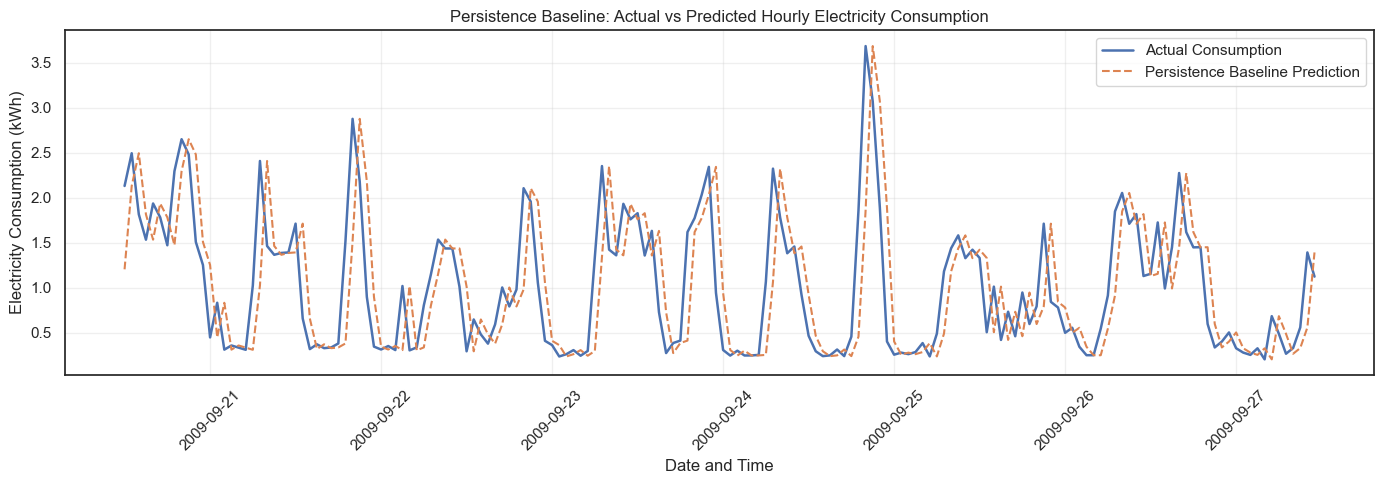

Baseline forecasting visualization completed.
Period: 2009-09-20 12:00:00 to 2009-09-27 11:00:00
Observations displayed: 168
Figure saved to: ../figure/persistence_baseline_validation.png


In [48]:

# Section 6.4.3 - Visualize Persistence Baseline Predictions

import matplotlib.pyplot as plt
import pandas as pd

# Select the first complete 7-day calendar window
# containing all 168 hourly validation predictions.
window_hours = 168
plot_data = None

for start_time in baseline_val_results.index:
    end_time = start_time + pd.Timedelta(hours=window_hours - 1)

    candidate = baseline_val_results.loc[start_time:end_time]

    if (
        len(candidate) == window_hours
        and candidate.index.equals(
            pd.date_range(start_time, periods=window_hours, freq="h")
        )
    ):
        plot_data = candidate
        break

if plot_data is None:
    print("No continuous 7-day validation window was found.")
else:
    plt.figure(figsize=(14, 5))

    plt.plot(
        plot_data.index,
        plot_data["Actual_kWh"],
        label="Actual Consumption",
        linewidth=1.8
    )

    plt.plot(
        plot_data.index,
        plot_data["Predicted_kWh"],
        label="Persistence Baseline Prediction",
        linewidth=1.5,
        linestyle="--"
    )

    plt.title(
        "Persistence Baseline: Actual vs Predicted Hourly Electricity Consumption"
    )

    plt.xlabel("Date and Time")
    plt.ylabel("Electricity Consumption (kWh)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()

    figure_path = "../figure/persistence_baseline_validation.png"

    plt.savefig(
        figure_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Baseline forecasting visualization completed.")
    print(f"Period: {plot_data.index.min()} to {plot_data.index.max()}")
    print(f"Observations displayed: {len(plot_data)}")
    print(f"Figure saved to: {figure_path}")



### Interpretation of Persistence Baseline Forecasting Results

The persistence baseline was evaluated using 4,962 observations from the chronological validation dataset.

The model achieved a Mean Absolute Error (MAE) of 0.4619 kWh, a Root Mean Squared Error (RMSE) of 0.6884 kWh, and a coefficient of determination (R²) of 0.3965.

The visualization of 168 consecutive hourly observations between September 20 and September 27, 2009, shows that the persistence model generally follows the observed electricity consumption pattern.

However, the predicted values exhibit a one-hour delay relative to the actual consumption measurements. This behavior is particularly evident during periods of rapid increases or decreases in electricity demand.

The persistence model therefore provides a useful reference forecast but has limited ability to anticipate sudden changes in household electricity consumption.

These findings establish a benchmark for subsequent machine learning forecasting models. The advanced models will be assessed based on their ability to reduce MAE and RMSE while improving R² on the validation dataset.

The testing dataset remains reserved for final evaluation after model selection.



## 6.5 Machine Learning Forecasting Models

This section develops machine learning models for predicting hourly household electricity consumption using historical electricity consumption measurements and calendar-based forecasting features.

The models will be trained using the chronological training dataset and evaluated using the validation dataset. Their performance will be compared against the persistence baseline using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

The testing dataset will remain reserved for final evaluation after model selection.

### 6.5.1 Linear Regression Forecasting

Linear Regression is used as the first machine learning forecasting model. It estimates hourly electricity consumption as a linear combination of the available forecasting features.

The model uses nine predictors:

- Lag_1, Lag_2, Lag_3, Lag_24, and Lag_168: historical electricity consumption measurements.
- Hour: hour of the day.
- Day_of_Week: day of the week.
- Month: month of the year.
- Is_Weekend: indicator distinguishing weekends from weekdays.

The Linear Regression model will be fitted using the training dataset and evaluated on the validation dataset.

Its forecasting performance will be compared with the persistence baseline to determine whether incorporating additional historical and calendar information improves prediction accuracy.


In [49]:

# Section 6.5.1.1 - Linear Regression Model Training

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
linear_regression_model = LinearRegression()

# Train the model using the training dataset only
linear_regression_model.fit(X_train, y_train)

# Display training information
print("LINEAR REGRESSION MODEL TRAINING")
print("-" * 55)

print(f"Training observations: {X_train.shape[0]:,}")
print(f"Number of forecasting features: {X_train.shape[1]}")

print("\nForecasting features:")
for feature in X_train.columns:
    print(f"- {feature}")

print("\nLinear Regression model training completed successfully.")


LINEAR REGRESSION MODEL TRAINING
-------------------------------------------------------
Training observations: 23,639
Number of forecasting features: 9

Forecasting features:
- Lag_1
- Lag_2
- Lag_3
- Lag_24
- Lag_168
- Hour
- Day_of_Week
- Month
- Is_Weekend

Linear Regression model training completed successfully.


In [50]:

# Section 6.5.1.2 - Linear Regression Validation Predictions

import pandas as pd

# Generate predictions using the validation dataset
linear_regression_val_predictions = linear_regression_model.predict(X_val)

# Organize actual and predicted consumption values
linear_regression_val_results = pd.DataFrame(
    {
        "Actual_kWh": y_val,
        "Predicted_kWh": linear_regression_val_predictions
    },
    index=y_val.index
)

# Display prediction information
print("LINEAR REGRESSION - VALIDATION PREDICTIONS")
print("-" * 55)

print(f"Validation observations: {len(y_val):,}")
print(f"Predictions generated: {len(linear_regression_val_predictions):,}")

print("\nFIRST 10 VALIDATION PREDICTIONS")
display(linear_regression_val_results.head(10))

print("\nLinear Regression validation predictions completed successfully.")


LINEAR REGRESSION - VALIDATION PREDICTIONS
-------------------------------------------------------
Validation observations: 4,962
Predictions generated: 4,962

FIRST 10 VALIDATION PREDICTIONS


,Actual_kWh,Predicted_kWh
Datetime,,
2009-09-20 12:00:00,2.133267,1.468497
2009-09-20 13:00:00,2.496667,2.183461
2009-09-20 14:00:00,1.817433,2.071778
2009-09-20 15:00:00,1.536567,1.613309
2009-09-20 16:00:00,1.938800,1.337839
2009-09-20 17:00:00,1.784433,1.987629
2009-09-20 18:00:00,1.474467,1.662690
2009-09-20 19:00:00,2.298033,1.382988
2009-09-20 20:00:00,2.652667,2.263095



Linear Regression validation predictions completed successfully.


In [51]:

# Section 6.5.1.3 - Linear Regression Validation Evaluation

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate validation performance metrics
linear_regression_mae = mean_absolute_error(
    y_val, linear_regression_val_predictions
)

linear_regression_rmse = np.sqrt(
    mean_squared_error(y_val, linear_regression_val_predictions)
)

linear_regression_r2 = r2_score(
    y_val, linear_regression_val_predictions
)

# Display performance results
print("LINEAR REGRESSION - VALIDATION PERFORMANCE")
print("-" * 55)

print(f"Validation observations: {len(y_val):,}")
print(f"Mean Absolute Error (MAE): {linear_regression_mae:.4f} kWh")
print(f"Root Mean Squared Error (RMSE): {linear_regression_rmse:.4f} kWh")
print(f"Coefficient of Determination (R²): {linear_regression_r2:.4f}")

# Create a performance summary
linear_regression_metrics = pd.DataFrame({
    "Model": ["Linear Regression"],
    "MAE_kWh": [linear_regression_mae],
    "RMSE_kWh": [linear_regression_rmse],
    "R2": [linear_regression_r2]
})

print("\nLINEAR REGRESSION PERFORMANCE SUMMARY")
display(linear_regression_metrics.round(4))

print("\nLinear Regression validation evaluation completed successfully.")


LINEAR REGRESSION - VALIDATION PERFORMANCE
-------------------------------------------------------
Validation observations: 4,962
Mean Absolute Error (MAE): 0.4176 kWh
Root Mean Squared Error (RMSE): 0.5896 kWh
Coefficient of Determination (R²): 0.5573

LINEAR REGRESSION PERFORMANCE SUMMARY


,Model,MAE_kWh,RMSE_kWh,R2
0,Linear Regression,0.4176,0.5896,0.5573



Linear Regression validation evaluation completed successfully.


In [52]:

# Section 6.5.1.4 - Baseline vs Linear Regression Comparison

# Combine the previously calculated model metrics
model_comparison = pd.concat(
    [baseline_metrics, linear_regression_metrics],
    ignore_index=True
)

# Calculate improvement relative to the persistence baseline
mae_improvement = (
    (model_comparison.loc[0, "MAE_kWh"] -
     model_comparison.loc[1, "MAE_kWh"])
    / model_comparison.loc[0, "MAE_kWh"] * 100
)

rmse_improvement = (
    (model_comparison.loc[0, "RMSE_kWh"] -
     model_comparison.loc[1, "RMSE_kWh"])
    / model_comparison.loc[0, "RMSE_kWh"] * 100
)

# Display results
print("FORECASTING MODEL PERFORMANCE COMPARISON")
print("-" * 55)

display(model_comparison.round(4))

print(f"\nMAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

print("\nModel comparison completed successfully.")


FORECASTING MODEL PERFORMANCE COMPARISON
-------------------------------------------------------


,Model,MAE_kWh,RMSE_kWh,R2
0,Persistence Baseline,0.4619,0.6884,0.3965
1,Linear Regression,0.4176,0.5896,0.5573



MAE improvement: 9.60%
RMSE improvement: 14.35%

Model comparison completed successfully.


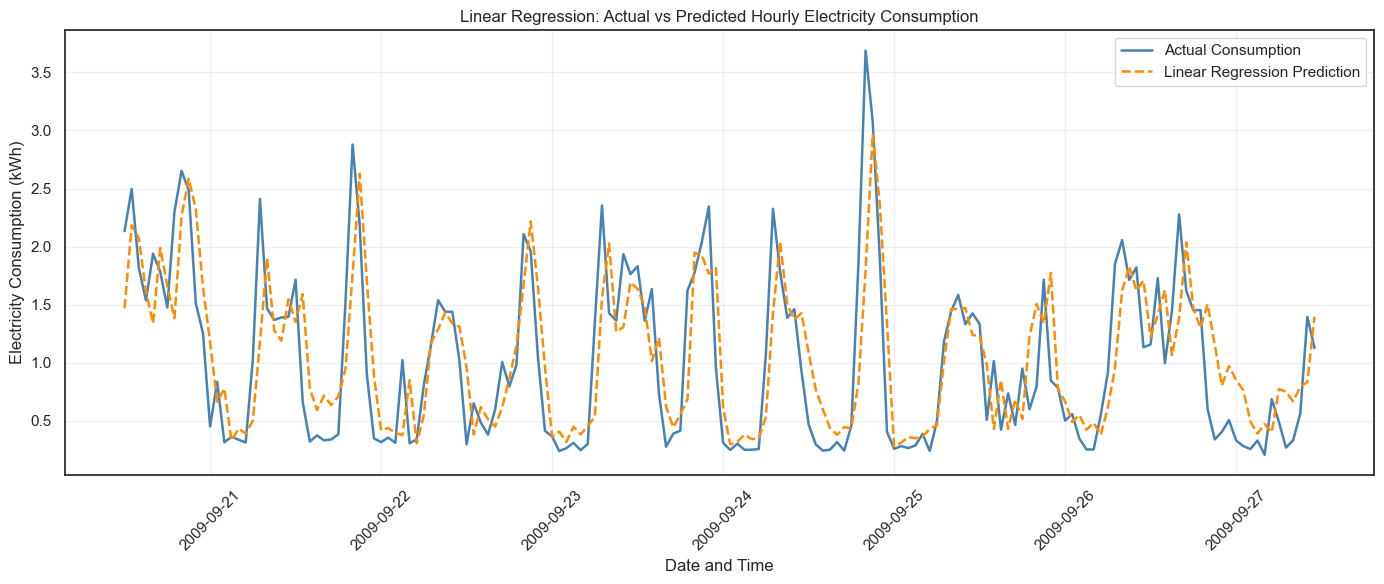

Linear Regression forecasting visualization completed.
Observations displayed: 168
Figure saved to: ../figure/linear_regression_validation.png


In [53]:

# Section 6.5.1.5 - Linear Regression Forecasting Visualization

import matplotlib.pyplot as plt

# Select the first 168 validation observations (7 days)
plot_data = linear_regression_val_results.iloc[:168]

# Create the visualization
plt.figure(figsize=(14, 6))

plt.plot(
    plot_data.index,
    plot_data["Actual_kWh"],
    label="Actual Consumption",
    color="steelblue",
    linewidth=1.8
)

plt.plot(
    plot_data.index,
    plot_data["Predicted_kWh"],
    label="Linear Regression Prediction",
    color="darkorange",
    linestyle="--",
    linewidth=1.8
)

plt.title(
    "Linear Regression: Actual vs Predicted Hourly Electricity Consumption"
)

plt.xlabel("Date and Time")
plt.ylabel("Electricity Consumption (kWh)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

# Save the figure
figure_path = "../figure/linear_regression_validation.png"

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Linear Regression forecasting visualization completed.")
print(f"Observations displayed: {len(plot_data)}")
print(f"Figure saved to: {figure_path}")


### 6.5.2 Interpretation of Linear Regression Forecasting Performance

The Linear Regression model demonstrates a reasonable ability to capture temporal variations in hourly household electricity consumption. The predicted values generally follow the observed consumption patterns, indicating that the combination of lagged consumption and calendar-based features provides useful forecasting information.

Compared with the persistence baseline, Linear Regression achieved a 9.60% reduction in Mean Absolute Error (MAE) and a 14.35% reduction in Root Mean Squared Error (RMSE) on the validation dataset. The coefficient of determination (R²) also improved from 0.3965 to 0.5573.

Visual inspection indicates that the model captures several periods of elevated electricity consumption but occasionally underestimates sharp demand peaks and overestimates consumption during low-demand periods.

These findings suggest that Linear Regression provides a stronger forecasting benchmark than the persistence model. However, its limitations in capturing abrupt and potentially nonlinear consumption patterns motivate the evaluation of more flexible machine learning algorithms.

The model comparison is based exclusively on validation data. Final forecasting performance will be assessed using the previously reserved testing dataset after model selection.


## Random Forest Regression Forecasting

Random Forest Regression is an ensemble machine learning algorithm that combines predictions from multiple decision trees to improve predictive accuracy and reduce overfitting.

Unlike Linear Regression, which assumes an additive linear relationship between predictors and electricity consumption, Random Forest can capture nonlinear relationships and interactions among forecasting features.

In this section, a Random Forest Regression model will be trained using the previously prepared training dataset. Its performance will be evaluated using the validation dataset and compared with the Persistence Baseline and Linear Regression models.

The model will use the same nine forecasting features to ensure a consistent comparison across forecasting approaches.

Model performance will be assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the Coefficient of Determination (R²).


In [54]:

# Section 6.5.2.1 - Random Forest Regression Model Training

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model using the training dataset only
random_forest_model.fit(X_train, y_train)

# Display training information
print("RANDOM FOREST REGRESSION MODEL TRAINING")
print("-" * 55)

print(f"Training observations: {len(X_train):,}")
print(f"Number of forecasting features: {X_train.shape[1]}")
print(f"Number of decision trees: {random_forest_model.n_estimators}")
print(f"Maximum tree depth: {random_forest_model.max_depth}")
print(f"Minimum samples per leaf: {random_forest_model.min_samples_leaf}")

print("\nForecasting features:")
for feature in X_train.columns:
    print(f" - {feature}")

print("\nRandom Forest Regression model training completed successfully.")


RANDOM FOREST REGRESSION MODEL TRAINING
-------------------------------------------------------
Training observations: 23,639
Number of forecasting features: 9
Number of decision trees: 100
Maximum tree depth: 15
Minimum samples per leaf: 2

Forecasting features:
 - Lag_1
 - Lag_2
 - Lag_3
 - Lag_24
 - Lag_168
 - Hour
 - Day_of_Week
 - Month
 - Is_Weekend

Random Forest Regression model training completed successfully.


In [55]:

# Section 6.5.2.2 - Random Forest Validation Predictions

import pandas as pd

# Generate predictions using the validation dataset
random_forest_val_predictions = random_forest_model.predict(X_val)

# Create a comparison DataFrame
random_forest_val_results = pd.DataFrame({
    "Actual_kWh": y_val,
    "Predicted_kWh": random_forest_val_predictions
}, index=y_val.index)

# Display prediction information
print("RANDOM FOREST REGRESSION - VALIDATION PREDICTIONS")
print("-" * 55)

print(f"Validation observations: {len(y_val):,}")
print(f"Predictions generated: {len(random_forest_val_predictions):,}")

print("\nFIRST 10 VALIDATION PREDICTIONS")
display(random_forest_val_results.head(10))

# Verify prediction consistency
assert len(random_forest_val_predictions) == len(y_val)
assert random_forest_val_results.notna().all().all()

print("\nRandom Forest validation prediction verification: PASSED")


RANDOM FOREST REGRESSION - VALIDATION PREDICTIONS
-------------------------------------------------------
Validation observations: 4,962
Predictions generated: 4,962

FIRST 10 VALIDATION PREDICTIONS


,Actual_kWh,Predicted_kWh
Datetime,,
2009-09-20 12:00:00,2.133267,1.654518
2009-09-20 13:00:00,2.496667,2.079632
2009-09-20 14:00:00,1.817433,1.934031
2009-09-20 15:00:00,1.536567,1.731759
2009-09-20 16:00:00,1.938800,1.545910
2009-09-20 17:00:00,1.784433,2.034538
2009-09-20 18:00:00,1.474467,1.739235
2009-09-20 19:00:00,2.298033,1.617776
2009-09-20 20:00:00,2.652667,2.550833



Random Forest validation prediction verification: PASSED


In [56]:

# Section 6.5.2.3 - Random Forest Validation Performance Evaluation

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate validation performance metrics
rf_mae = mean_absolute_error(
    y_val, random_forest_val_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(y_val, random_forest_val_predictions)
)

rf_r2 = r2_score(
    y_val, random_forest_val_predictions
)

# Store results for later model comparison
random_forest_metrics = pd.DataFrame({
    "Model": ["Random Forest Regression"],
    "MAE_kWh": [rf_mae],
    "RMSE_kWh": [rf_rmse],
    "R2": [rf_r2]
})

# Display results
print("RANDOM FOREST REGRESSION - VALIDATION PERFORMANCE")
print("-" * 55)

print(f"Validation observations: {len(y_val):,}")
print(f"Mean Absolute Error (MAE): {rf_mae:.4f} kWh")
print(f"Root Mean Squared Error (RMSE): {rf_rmse:.4f} kWh")
print(f"Coefficient of Determination (R²): {rf_r2:.4f}")

print("\nRANDOM FOREST PERFORMANCE SUMMARY")
display(random_forest_metrics.round(4))

print("\nRandom Forest validation evaluation completed successfully.")


RANDOM FOREST REGRESSION - VALIDATION PERFORMANCE
-------------------------------------------------------
Validation observations: 4,962
Mean Absolute Error (MAE): 0.3768 kWh
Root Mean Squared Error (RMSE): 0.5479 kWh
Coefficient of Determination (R²): 0.6178

RANDOM FOREST PERFORMANCE SUMMARY


,Model,MAE_kWh,RMSE_kWh,R2
0,Random Forest Regression,0.3768,0.5479,0.6178



Random Forest validation evaluation completed successfully.


In [57]:

# Section 6.5.2.4 - Comparison of Three Forecasting Models

import pandas as pd

# Combine previously calculated validation metrics
three_model_comparison = pd.concat(
    [
        baseline_metrics,
        linear_regression_metrics,
        random_forest_metrics
    ],
    ignore_index=True
)

# Rank models by validation MAE
three_model_comparison = (
    three_model_comparison
    .sort_values("MAE_kWh")
    .reset_index(drop=True)
)

# Calculate improvements over Linear Regression
lr_mae = linear_regression_metrics["MAE_kWh"].iloc[0]
lr_rmse = linear_regression_metrics["RMSE_kWh"].iloc[0]

rf_mae_improvement = (
    (lr_mae - rf_mae) / lr_mae
) * 100

rf_rmse_improvement = (
    (lr_rmse - rf_rmse) / lr_rmse
) * 100

print("THREE-MODEL VALIDATION PERFORMANCE COMPARISON")
print("-" * 55)

display(three_model_comparison.round(4))

print("\nRANDOM FOREST IMPROVEMENT OVER LINEAR REGRESSION")
print(f"MAE improvement: {rf_mae_improvement:.2f}%")
print(f"RMSE improvement: {rf_rmse_improvement:.2f}%")

print(
    f"\nBest model by validation MAE: "
    f"{three_model_comparison.iloc[0]['Model']}"
)

print("\nThree-model comparison completed successfully.")


THREE-MODEL VALIDATION PERFORMANCE COMPARISON
-------------------------------------------------------


,Model,MAE_kWh,RMSE_kWh,R2
0,Random Forest Regression,0.3768,0.5479,0.6178
1,Linear Regression,0.4176,0.5896,0.5573
2,Persistence Baseline,0.4619,0.6884,0.3965



RANDOM FOREST IMPROVEMENT OVER LINEAR REGRESSION
MAE improvement: 9.77%
RMSE improvement: 7.08%

Best model by validation MAE: Random Forest Regression

Three-model comparison completed successfully.


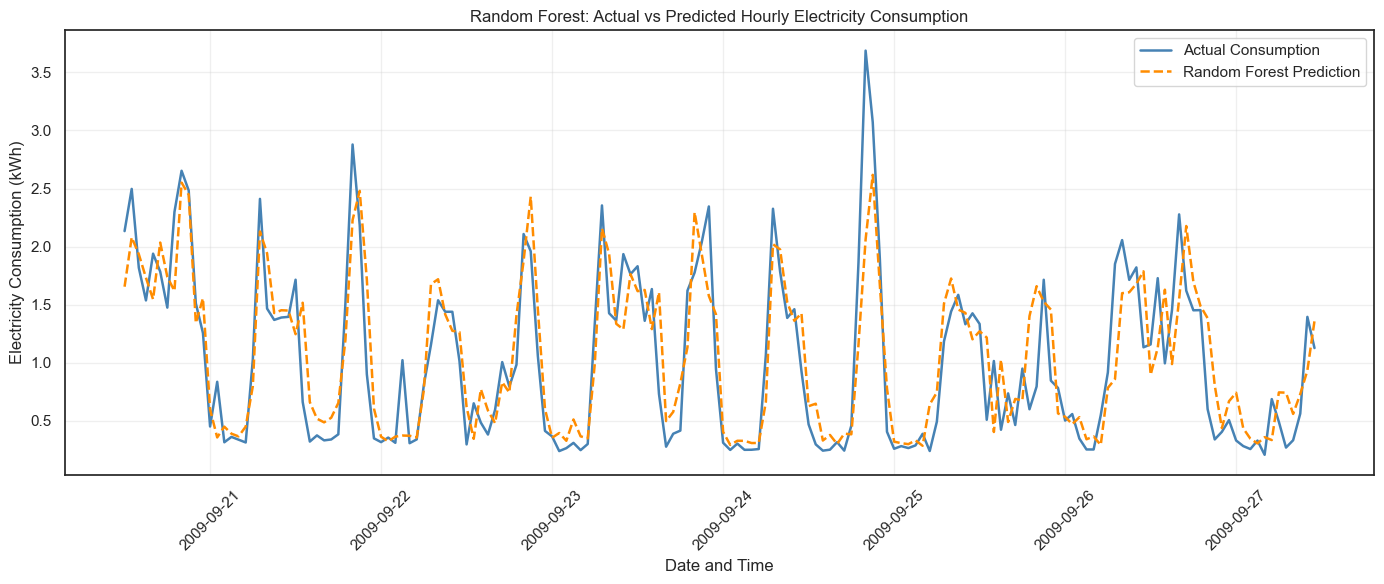

Random Forest forecasting visualization completed.
Observations displayed: 168
Figure saved to: ../figure/random_forest_validation.png


In [58]:

# Section 6.5.2.5 - Random Forest Forecasting Visualization

import matplotlib.pyplot as plt

# Select the first seven days (168 hours) of validation results
rf_plot_data = random_forest_val_results.iloc[:168]

# Create the visualization
plt.figure(figsize=(14, 6))

plt.plot(
    rf_plot_data.index,
    rf_plot_data["Actual_kWh"],
    label="Actual Consumption",
    color="steelblue",
    linewidth=1.8
)

plt.plot(
    rf_plot_data.index,
    rf_plot_data["Predicted_kWh"],
    label="Random Forest Prediction",
    color="darkorange",
    linestyle="--",
    linewidth=1.8
)

plt.title(
    "Random Forest: Actual vs Predicted Hourly Electricity Consumption"
)
plt.xlabel("Date and Time")
plt.ylabel("Electricity Consumption (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

# Save the figure
figure_path = "../figure/random_forest_validation.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Random Forest forecasting visualization completed.")
print(f"Observations displayed: {len(rf_plot_data):,}")
print(f"Figure saved to: {figure_path}")


### Interpretation of Random Forest Forecasting Performance

The Random Forest Regression model demonstrates a reasonable ability to predict hourly household electricity consumption. The predicted values generally follow the actual consumption pattern, capturing both low-demand periods and several increases in electricity usage.

However, the model does not perfectly reproduce all consumption fluctuations. In particular, some periods of unusually high electricity demand are underestimated, while occasional overestimations occur during rapidly changing consumption conditions.

The validation results indicate that Random Forest Regression outperforms both Linear Regression and the Persistence Baseline, achieving a Mean Absolute Error (MAE) of 0.3768 kWh, a Root Mean Squared Error (RMSE) of 0.5479 kWh, and an R² score of 0.6178.

These findings suggest that Random Forest captures useful nonlinear relationships between historical electricity consumption and calendar-based forecasting features.

Nevertheless, the model's performance must be assessed on the previously unseen testing dataset before drawing conclusions about its generalization capability.


### 6.5.3 XGBoost Regression — Gradient Boosting Forecasting Model

This section develops an XGBoost Regression model to forecast hourly household electricity consumption.

The model uses the existing training and validation datasets and the same forecasting features as the previous machine learning models.

Its performance will be compared against the Persistence Baseline, Linear Regression, and Random Forest Regression models.


In [59]:

# Section 6.5.3.1 - Check XGBoost Installation

try:
    import xgboost as xgb

    print("XGBoost is installed successfully.")
    print("XGBoost version:", xgb.__version__)

except ImportError:
    print("XGBoost is not installed in this environment.")


XGBoost is installed successfully.
XGBoost version: 3.4.1


In [60]:

# Section 6.5.3.2 - Install XGBoost

%pip install xgboost


Note: you may need to restart the kernel to use updated packages.


In [61]:

# Section 6.5.3.3 - Verify XGBoost Installation

import xgboost as xgb

print("XGBoost imported successfully.")
print("XGBoost version:", xgb.__version__)


XGBoost imported successfully.
XGBoost version: 3.4.1


In [62]:

# Section 6.5.3.4 - Verify Forecasting Datasets

required_variables = [
    "X_train",
    "X_val",
    "y_train",
    "y_val"
]

for variable in required_variables:
    if variable in globals():
        data = globals()[variable]
        print(f"{variable}: Available - Shape: {data.shape}")
    else:
        print(f"{variable}: NOT AVAILABLE")


X_train: Available - Shape: (23639, 9)
X_val: Available - Shape: (4962, 9)
y_train: Available - Shape: (23639,)
y_val: Available - Shape: (4962,)


In [63]:

# Section 6.5.3.5 - Train XGBoost Regression Model

import xgboost as xgb
import time

# Initialize the XGBoost regression model
xgb_model = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Record training start time
start_time = time.time()

# Train using the existing training dataset
xgb_model.fit(X_train, y_train)

# Calculate training duration
training_time = time.time() - start_time

print("XGBoost Regression training completed successfully.")
print(f"Training observations: {len(X_train):,}")
print(f"Number of forecasting features: {X_train.shape[1]}")
print(f"Training time: {training_time:.2f} seconds")


XGBoost Regression training completed successfully.
Training observations: 23,639
Number of forecasting features: 9
Training time: 1.50 seconds


In [64]:

# Section 6.5.3.6 - XGBoost Validation Performance

import pandas as pd
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Generate predictions on the validation dataset
xgb_val_predictions = xgb_model.predict(X_val)

# Calculate validation performance metrics
xgb_val_mae = mean_absolute_error(
    y_val, xgb_val_predictions
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_val_predictions)
)

xgb_val_r2 = r2_score(
    y_val, xgb_val_predictions
)

# Store the results
xgb_validation_metrics = pd.DataFrame({
    "Model": ["XGBoost Regression"],
    "MAE": [xgb_val_mae],
    "RMSE": [xgb_val_rmse],
    "R2": [xgb_val_r2]
})

print("XGBoost Validation Performance")
print("-" * 40)
print(f"Validation observations: {len(y_val):,}")
print(f"MAE:  {xgb_val_mae:.4f} kWh")
print(f"RMSE: {xgb_val_rmse:.4f} kWh")
print(f"R²:   {xgb_val_r2:.4f}")
display(xgb_validation_metrics.round(4))


XGBoost Validation Performance
----------------------------------------
Validation observations: 4,962
MAE:  0.3728 kWh
RMSE: 0.5372 kWh
R²:   0.6324


,Model,MAE,RMSE,R2
0,XGBoost Regression,0.3728,0.5372,0.6324



#### Interpretation of XGBoost Validation Performance

The XGBoost Regression model was evaluated using 4,962 observations from the validation dataset.

The model achieved the following forecasting performance:

- Mean Absolute Error (MAE): 0.3728 kWh
- Root Mean Squared Error (RMSE): 0.5372 kWh
- Coefficient of Determination (R²): 0.6324

Compared with Random Forest Regression, which achieved an MAE of 0.3768 kWh, RMSE of 0.5479 kWh, and R² of 0.6178, XGBoost demonstrated improved forecasting accuracy across all three evaluation metrics.

Specifically, XGBoost reduced MAE by approximately 1.06% and RMSE by approximately 1.95%, while increasing R² by 0.0146.

These results suggest that gradient boosting captures household electricity consumption patterns slightly more effectively than the previously evaluated Random Forest model under the current experimental configuration.

However, the performance improvements are relatively modest and do not establish that XGBoost will consistently outperform Random Forest on unseen future observations.

At this stage, XGBoost Regression is the best-performing model based on validation performance.




### 6.5.4 LSTM Neural Network — Sequence-Based Electricity Forecasting

This section develops a Long Short-Term Memory (LSTM) neural network for hourly household electricity consumption forecasting.

Unlike the previous machine learning models, LSTM processes sequences of historical observations to learn temporal dependencies in electricity consumption.

The model will use chronologically ordered electricity consumption data, with appropriate scaling and sequence preparation.

Its validation performance will be compared with Persistence Baseline, Linear Regression, Random Forest Regression, and XGBoost Regression using MAE, RMSE, and R².

Care will be taken to prevent data leakage and maintain a consistent forecasting horizon across models.


In [65]:

# Section 6.5.4.1 - Check TensorFlow Installation

import sys

print("Python version:", sys.version.split()[0])

try:
    import tensorflow as tf

    print("TensorFlow installed successfully.")
    print("TensorFlow version:", tf.__version__)
    print("Keras version:", tf.keras.__version__)

except ImportError:
    print("TensorFlow is not installed in this environment.")

except Exception as error:
    print("TensorFlow could not be initialized.")
    print("Error:", error)


Python version: 3.13.9
TensorFlow installed successfully.
TensorFlow version: 2.21.0
Keras version: 3.15.1


In [66]:

# Section 6.5.4.2 - Install TensorFlow

%pip install tensorflow


Note: you may need to restart the kernel to use updated packages.


In [67]:

# Section 6.5.4.3 - Verify TensorFlow and Keras

import tensorflow as tf
from tensorflow import keras

print("TensorFlow imported successfully.")
print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)

# Check whether LSTM is available
print("LSTM layer available:", hasattr(keras.layers, "LSTM"))


TensorFlow imported successfully.
TensorFlow version: 2.21.0
Keras version: 3.15.1
LSTM layer available: True


In [68]:

# Section 6.5.4.4 - Check Package Compatibility

%pip check


No broken requirements found.
Note: you may need to restart the kernel to use updated packages.


In [69]:

# Section 6.5.4.5 - Resolve Protobuf Compatibility

%pip install "protobuf>=6.31.1,<7"


Note: you may need to restart the kernel to use updated packages.


In [70]:

# Section 6.5.4.6 - Verify LSTM Environment

import tensorflow as tf
from tensorflow import keras
import google.protobuf

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__)
print("Protobuf version:", google.protobuf.__version__)

print(
    "LSTM layer available:",
    hasattr(keras.layers, "LSTM")
)


TensorFlow version: 2.21.0
Keras version: 3.15.1
Protobuf version: 6.33.6
LSTM layer available: True


In [71]:

# Section 6.5.4.7 - Diagnose Protobuf Environment

import sys
import importlib.metadata as metadata
import google.protobuf

print("Python executable:", sys.executable)
print("Protobuf imported version:", google.protobuf.__version__)
print("Protobuf installed version:", metadata.version("protobuf"))
print("Protobuf location:", google.protobuf.__file__)


Python executable: C:\Users\USER\anaconda3\python.exe
Protobuf imported version: 6.33.6
Protobuf installed version: 6.33.6
Protobuf location: C:\Users\USER\anaconda3\Lib\site-packages\google\protobuf\__init__.py


In [80]:

# Section 6.5.4.9 - Final Package Compatibility Check

%pip check


No broken requirements found.
Note: you may need to restart the kernel to use updated packages.


In [81]:

# Section 6.5.4.10 - Verify Existing Forecasting Datasets

required_variables = [
    "hourly_valid",
    "forecast_features",
    "train_ready",
    "val_ready",
    "test_ready",
    "X_train",
    "X_val",
    "y_train",
    "y_val"
]

print("LSTM Data Availability Check")
print("-" * 45)

for variable in required_variables:
    if variable in globals():
        data = globals()[variable]
        print(f"{variable}: Available - Shape: {data.shape}")
    else:
        print(f"{variable}: NOT AVAILABLE")


LSTM Data Availability Check
---------------------------------------------
hourly_valid: Available - Shape: (34139, 3)
forecast_features: Available - Shape: (34587, 10)
train_ready: Available - Shape: (23639, 10)
val_ready: Available - Shape: (4962, 10)
test_ready: Available - Shape: (4721, 10)
X_train: Available - Shape: (23639, 9)
X_val: Available - Shape: (4962, 9)
y_train: Available - Shape: (23639,)
y_val: Available - Shape: (4962,)


In [82]:

# Section 6.5.4.11 - Inspect Data Structure for LSTM

datasets = {
    "hourly_valid": hourly_valid,
    "forecast_features": forecast_features,
    "train_ready": train_ready,
    "val_ready": val_ready
}

for name, data in datasets.items():
    print(f"\n{'=' * 55}")
    print(f"Dataset: {name}")
    print(f"{'=' * 55}")

    print("Shape:", data.shape)
    print("Columns:", data.columns.tolist())
    print("Index type:", type(data.index).__name__)

    print("First timestamp:", data.index.min())
    print("Last timestamp:", data.index.max())

    print("\nFirst 3 observations:")
    display(data.head(3))



Dataset: hourly_valid
Shape: (34139, 3)
Columns: ['Energy_kWh', 'Valid_Minutes', 'Complete_Hour']
Index type: DatetimeIndex
First timestamp: 2006-12-16 18:00:00
Last timestamp: 2010-11-26 20:00:00

First 3 observations:


,Energy_kWh,Valid_Minutes,Complete_Hour
Datetime,,,
2006-12-16 18:00:00,3.632200,60,True
2006-12-16 19:00:00,3.400233,60,True
2006-12-16 20:00:00,3.268567,60,True



Dataset: forecast_features
Shape: (34587, 10)
Columns: ['Energy_kWh', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_24', 'Lag_168', 'Hour', 'Day_of_Week', 'Month', 'Is_Weekend']
Index type: DatetimeIndex
First timestamp: 2006-12-16 18:00:00
Last timestamp: 2010-11-26 20:00:00

First 3 observations:


,Energy_kWh,Lag_1,Lag_2,Lag_3,Lag_24,Lag_168,Hour,Day_of_Week,Month,Is_Weekend
Datetime,,,,,,,,,,
2006-12-16 18:00:00,3.632200,NaN,NaN,NaN,NaN,NaN,18,5,12,1
2006-12-16 19:00:00,3.400233,3.632200,NaN,NaN,NaN,NaN,19,5,12,1
2006-12-16 20:00:00,3.268567,3.400233,3.6322,NaN,NaN,NaN,20,5,12,1



Dataset: train_ready
Shape: (23639, 10)
Columns: ['Energy_kWh', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_24', 'Lag_168', 'Hour', 'Day_of_Week', 'Month', 'Is_Weekend']
Index type: DatetimeIndex
First timestamp: 2006-12-23 18:00:00
Last timestamp: 2009-09-20 11:00:00

First 3 observations:


,Energy_kWh,Lag_1,Lag_2,Lag_3,Lag_24,Lag_168,Hour,Day_of_Week,Month,Is_Weekend
Datetime,,,,,,,,,,
2006-12-23 18:00:00,3.879400,5.452533,4.349100,4.049100,2.686967,3.632200,18,5,12,1
2006-12-23 19:00:00,4.117833,3.879400,5.452533,4.349100,3.938167,3.400233,19,5,12,1
2006-12-23 20:00:00,4.181400,4.117833,3.879400,5.452533,3.536067,3.268567,20,5,12,1



Dataset: val_ready
Shape: (4962, 10)
Columns: ['Energy_kWh', 'Lag_1', 'Lag_2', 'Lag_3', 'Lag_24', 'Lag_168', 'Hour', 'Day_of_Week', 'Month', 'Is_Weekend']
Index type: DatetimeIndex
First timestamp: 2009-09-20 12:00:00
Last timestamp: 2010-04-24 15:00:00

First 3 observations:


,Energy_kWh,Lag_1,Lag_2,Lag_3,Lag_24,Lag_168,Hour,Day_of_Week,Month,Is_Weekend
Datetime,,,,,,,,,,
2009-09-20 12:00:00,2.133267,1.207400,0.361367,1.182567,1.803167,1.790267,12,6,9,1
2009-09-20 13:00:00,2.496667,2.133267,1.207400,0.361367,3.328400,1.458000,13,6,9,1
2009-09-20 14:00:00,1.817433,2.496667,2.133267,1.207400,1.722500,1.181133,14,6,9,1


In [83]:

# Section 6.5.4.12 - Verify Temporal Continuity for LSTM

import pandas as pd

datasets_to_check = {
    "Training": train_ready,
    "Validation": val_ready,
    "Testing": test_ready
}

for name, data in datasets_to_check.items():

    timestamps = data.index.sort_values()

    time_differences = timestamps.to_series().diff().dropna()

    expected_interval = pd.Timedelta(hours=1)

    missing_intervals = (
        time_differences > expected_interval
    ).sum()

    duplicate_or_short_intervals = (
        time_differences < expected_interval
    ).sum()

    print(f"\n{name} Dataset")
    print("-" * 45)

    print("Observations:", len(data))

    print("First timestamp:", timestamps.min())
    print("Last timestamp:", timestamps.max())

    print("Gaps greater than 1 hour:", missing_intervals)

    print(
        "Intervals shorter than 1 hour:",
        duplicate_or_short_intervals
    )

    print(
        "Maximum time gap:",
        time_differences.max()
    )

    print(
        "Chronologically sorted:",
        data.index.is_monotonic_increasing
    )

    print(
        "Duplicate timestamps:",
        data.index.duplicated().sum()
    )



Training Dataset
---------------------------------------------
Observations: 23639
First timestamp: 2006-12-23 18:00:00
Last timestamp: 2009-09-20 11:00:00
Gaps greater than 1 hour: 31
Intervals shorter than 1 hour: 0
Maximum time gap: 3 days 16:00:00
Chronologically sorted: True
Duplicate timestamps: 0

Validation Dataset
---------------------------------------------
Observations: 4962
First timestamp: 2009-09-20 12:00:00
Last timestamp: 2010-04-24 15:00:00
Gaps greater than 1 hour: 4
Intervals shorter than 1 hour: 0
Maximum time gap: 3 days 07:00:00
Chronologically sorted: True
Duplicate timestamps: 0

Testing Dataset
---------------------------------------------
Observations: 4721
First timestamp: 2010-04-24 16:00:00
Last timestamp: 2010-11-26 20:00:00
Gaps greater than 1 hour: 4
Intervals shorter than 1 hour: 0
Maximum time gap: 6 days 02:00:00
Chronologically sorted: True
Duplicate timestamps: 0


In [84]:

# Section 6.5.4.13 - Create Gap-Aware LSTM Sequences

import numpy as np

LOOKBACK = 24

def create_lstm_sequences(data, lookback=24):
    """
    Create sequences using consecutive hourly observations.
    Each sequence predicts the hour immediately after
    the input window.
    """

    data = data.sort_index()

    values = data["Energy_kWh"].to_numpy(dtype=np.float32)
    timestamps = data.index

    X_sequences = []
    y_sequences = []
    target_timestamps = []

    for i in range(lookback, len(data)):

        window_times = timestamps[i-lookback:i+1]

        time_differences = window_times[1:] - window_times[:-1]

        if not np.all(
            time_differences == pd.Timedelta(hours=1)
        ):
            continue

        X_sequences.append(
            values[i-lookback:i].reshape(lookback, 1)
        )

        y_sequences.append(values[i])
        target_timestamps.append(timestamps[i])

    X_sequences = np.asarray(
        X_sequences, dtype=np.float32
    ).reshape(-1, lookback, 1)

    y_sequences = np.asarray(
        y_sequences, dtype=np.float32
    )

    return (
        X_sequences,
        y_sequences,
        pd.DatetimeIndex(target_timestamps)
    )


# Prepare sequences separately to preserve dataset boundaries

X_train_lstm, y_train_lstm, train_lstm_dates = (
    create_lstm_sequences(train_ready, LOOKBACK)
)

X_val_lstm, y_val_lstm, val_lstm_dates = (
    create_lstm_sequences(val_ready, LOOKBACK)
)

X_test_lstm, y_test_lstm, test_lstm_dates = (
    create_lstm_sequences(test_ready, LOOKBACK)
)


# Display sequence dimensions

for name, X, y in [
    ("Training", X_train_lstm, y_train_lstm),
    ("Validation", X_val_lstm, y_val_lstm),
    ("Testing", X_test_lstm, y_test_lstm)
]:
    print(f"\n{name} LSTM Sequences")
    print("-" * 40)
    print("Input shape:", X.shape)
    print("Target shape:", y.shape)
    print("Lookback hours:", LOOKBACK)
    print("Number of sequences:", len(X))



Training LSTM Sequences
----------------------------------------
Input shape: (22928, 24, 1)
Target shape: (22928,)
Lookback hours: 24
Number of sequences: 22928

Validation LSTM Sequences
----------------------------------------
Input shape: (4842, 24, 1)
Target shape: (4842,)
Lookback hours: 24
Number of sequences: 4842

Testing LSTM Sequences
----------------------------------------
Input shape: (4602, 24, 1)
Target shape: (4602,)
Lookback hours: 24
Number of sequences: 4602


In [86]:
# Section 6.5.4.14 - Scale LSTM Input Sequences

import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Initialize scaler
lstm_scaler = MinMaxScaler(feature_range=(0, 1))

# Fit scaler using training consumption values only
lstm_scaler.fit(
    train_ready[["Energy_kWh"]].to_numpy()
)

# Scale training sequences
X_train_lstm_scaled = lstm_scaler.transform(
    X_train_lstm.reshape(-1, 1)
).reshape(X_train_lstm.shape)

# Scale validation sequences
X_val_lstm_scaled = lstm_scaler.transform(
    X_val_lstm.reshape(-1, 1)
).reshape(X_val_lstm.shape)

# Scale testing sequences
X_test_lstm_scaled = lstm_scaler.transform(
    X_test_lstm.reshape(-1, 1)
).reshape(X_test_lstm.shape)

# Display results
print("LSTM Input Scaling Completed")
print("-" * 40)

print("Training shape:", X_train_lstm_scaled.shape)
print("Validation shape:", X_val_lstm_scaled.shape)
print("Testing shape:", X_test_lstm_scaled.shape)

print("\nTraining scaled minimum:", X_train_lstm_scaled.min())
print("Training scaled maximum:", X_train_lstm_scaled.max())

LSTM Input Scaling Completed
----------------------------------------
Training shape: (22928, 24, 1)
Validation shape: (4842, 24, 1)
Testing shape: (4602, 24, 1)

Training scaled minimum: -1.0772119e-09
Training scaled maximum: 1.0


In [87]:

# Section 6.5.4.15 - Scale LSTM Target Values

# Scale target values using the existing training-fitted scaler
y_train_lstm_scaled = lstm_scaler.transform(
    y_train_lstm.reshape(-1, 1)
).flatten()

y_val_lstm_scaled = lstm_scaler.transform(
    y_val_lstm.reshape(-1, 1)
).flatten()

y_test_lstm_scaled = lstm_scaler.transform(
    y_test_lstm.reshape(-1, 1)
).flatten()

# Display scaling results
print("LSTM Target Scaling Completed")
print("-" * 40)

print("Training target shape:", y_train_lstm_scaled.shape)
print("Validation target shape:", y_val_lstm_scaled.shape)
print("Testing target shape:", y_test_lstm_scaled.shape)

print("\nTraining target minimum:", y_train_lstm_scaled.min())
print("Training target maximum:", y_train_lstm_scaled.max())

print("\nFirst 5 original training targets:")
print(y_train_lstm[:5])

print("\nFirst 5 scaled training targets:")
print(y_train_lstm_scaled[:5])


LSTM Target Scaling Completed
----------------------------------------
Training target shape: (22928,)
Validation target shape: (4842,)
Testing target shape: (4602,)

Training target minimum: -1.0772119e-09
Training target maximum: 1.0

First 5 original training targets:
[0.5052     0.45403334 0.4741     0.48403335 0.47976667]

First 5 scaled training targets:
[0.05922443 0.05127501 0.05439263 0.05593591 0.05527302]


In [88]:

# Section 6.5.4.16 - Build LSTM Architecture

import tensorflow as tf
from tensorflow import keras

# Set random seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Define the LSTM model
lstm_model = keras.Sequential([
    keras.Input(shape=(24, 1)),

    keras.layers.LSTM(
        units=64,
        activation="tanh"
    ),

    keras.layers.Dropout(0.2),

    keras.layers.Dense(1)
])

# Compile the model
lstm_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mse",
    metrics=["mae"]
)

# Display model architecture
lstm_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

## 6.6 Final Model Evaluation on the Testing Dataset

### 6.6.1 Testing the Selected Random Forest Regression Model

Following the validation-stage comparison, Random Forest Regression was selected as the best-performing forecasting model based on its lower prediction errors and higher coefficient of determination.

The selected model will now be evaluated using the previously unseen testing dataset, containing 4,721 hourly observations.

This final evaluation aims to assess the model's ability to generalize beyond the training and validation periods. Model performance will be assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²).

The testing dataset will not be used to train the model or adjust its hyperparameters.

In [72]:
# Section 6.6.1.1 - Final Random Forest Model Testing
# Generate predictions on the unseen testing dataset

rf_test_predictions = random_forest_model.predict(X_test)

print("RANDOM FOREST - FINAL TEST PREDICTIONS")
print("-" * 55)

print(f"Testing observations: {len(X_test):,}")
print(f"Predictions generated: {len(rf_test_predictions):,}")

# Display the first 10 actual and predicted values
rf_test_results = pd.DataFrame({
    "Actual_kWh": y_test,
    "Predicted_kWh": rf_test_predictions
}, index=y_test.index)

print("\nFIRST 10 TEST PREDICTIONS")
display(rf_test_results.head(10))

print("\nFinal test predictions generated successfully.")

RANDOM FOREST - FINAL TEST PREDICTIONS
-------------------------------------------------------
Testing observations: 4,721
Predictions generated: 4,721

FIRST 10 TEST PREDICTIONS


,Actual_kWh,Predicted_kWh
Datetime,,
2010-04-24 16:00:00,0.698800,1.360201
2010-04-24 17:00:00,1.680833,0.799737
2010-04-24 18:00:00,2.445300,1.843848
2010-04-24 19:00:00,2.478067,2.379348
2010-04-24 20:00:00,2.027500,2.211476
2010-04-24 21:00:00,3.143333,1.944447
2010-04-24 22:00:00,3.031200,2.184523
2010-04-24 23:00:00,1.744200,2.385952
2010-04-25 00:00:00,1.636633,0.999964



Final test predictions generated successfully.


In [73]:

# Section 6.6.1.2 - Final Random Forest Testing Performance

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Calculate final testing metrics
rf_test_mae = mean_absolute_error(y_test, rf_test_predictions)

rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, rf_test_predictions)
)

rf_test_r2 = r2_score(y_test, rf_test_predictions)

# Display final testing results
print("RANDOM FOREST - FINAL TESTING PERFORMANCE")
print("-" * 55)

print(f"Testing observations: {len(y_test):,}")
print(f"Mean Absolute Error (MAE): {rf_test_mae:.4f} kWh")
print(f"Root Mean Squared Error (RMSE): {rf_test_rmse:.4f} kWh")
print(f"Coefficient of Determination (R²): {rf_test_r2:.4f}")

# Store results for later comparison
rf_test_metrics = pd.DataFrame({
    "Model": ["Random Forest Regression"],
    "MAE_kWh": [rf_test_mae],
    "RMSE_kWh": [rf_test_rmse],
    "R2": [rf_test_r2]
})

print("\nFINAL TESTING PERFORMANCE SUMMARY")
display(rf_test_metrics.round(4))

print("\nFinal Random Forest testing evaluation completed successfully.")


RANDOM FOREST - FINAL TESTING PERFORMANCE
-------------------------------------------------------
Testing observations: 4,721
Mean Absolute Error (MAE): 0.3275 kWh
Root Mean Squared Error (RMSE): 0.4750 kWh
Coefficient of Determination (R²): 0.5499

FINAL TESTING PERFORMANCE SUMMARY


,Model,MAE_kWh,RMSE_kWh,R2
0,Random Forest Regression,0.3275,0.475,0.5499



Final Random Forest testing evaluation completed successfully.


### 6.6.2 Interpretation of Final Random Forest Testing Performance

The Random Forest Regression model was evaluated on 4,721 previously unseen hourly electricity consumption observations.

The model achieved a Mean Absolute Error (MAE) of 0.3275 kWh, a Root Mean Squared Error (RMSE) of 0.4750 kWh, and a coefficient of determination (R²) of 0.5499.

Compared with the validation results, the testing MAE decreased from 0.3768 kWh to 0.3275 kWh, while RMSE decreased from 0.5479 kWh to 0.4750 kWh. These findings indicate lower prediction errors during the testing period.

However, the R² score decreased from 0.6178 during validation to 0.5499 during testing, suggesting that the model explains a smaller proportion of consumption variability in the testing dataset.

Overall, the results demonstrate reasonable generalization performance on previously unseen data. Nevertheless, the model still exhibits prediction errors, particularly during periods of changing or unusually high electricity demand.

The final testing results provide an independent assessment of the selected model's forecasting performance without using the testing dataset for model selection or hyperparameter tuning.

### 6.7 Visualization of Random Forest Predictions on the Testing Dataset

To assess the forecasting performance of the selected Random Forest Regression model, actual and predicted hourly electricity consumption values are compared over a seven-day period within the testing dataset.

The visualization provides a time-based assessment of the model's ability to reproduce electricity consumption patterns, including periods of low demand, increasing consumption, and peak electricity usage.

This complements the numerical performance evaluation by highlighting the timing and magnitude of forecasting errors.

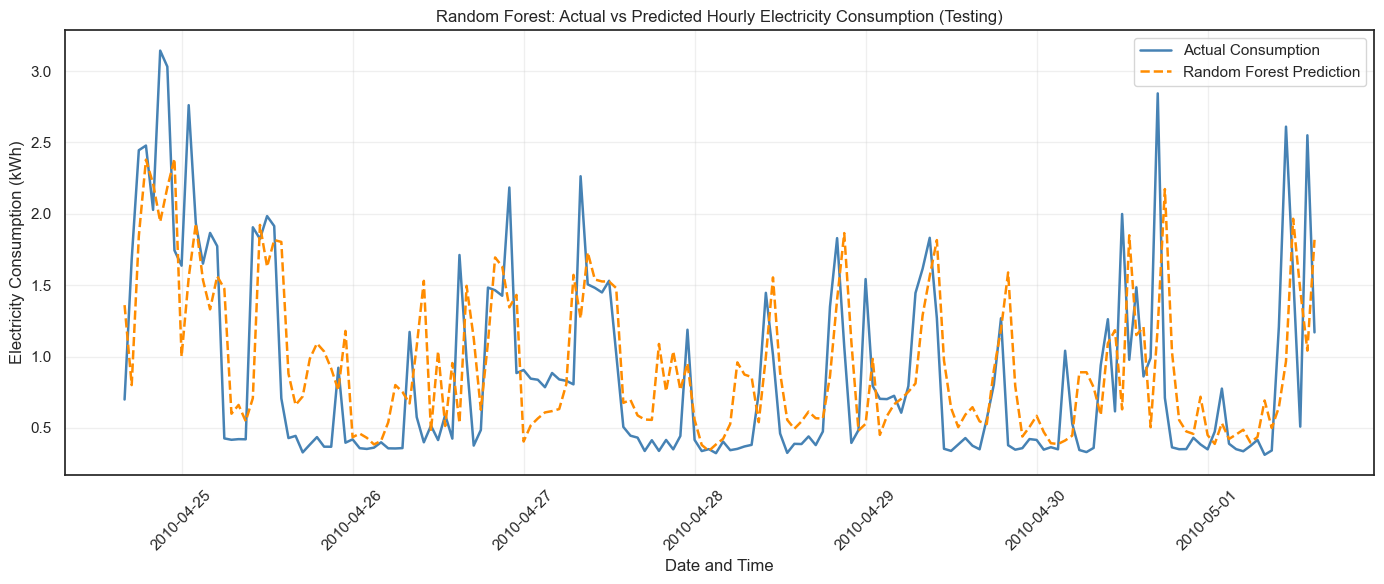

Random Forest testing visualization completed.
Observations displayed: 168
Period: 2010-04-24 16:00:00 to 2010-05-01 15:00:00
Figure saved to: ../figure/random_forest_testing.png


In [74]:

# Section 6.7.1 - Random Forest Testing Visualization

import matplotlib.pyplot as plt

# Select the first 168 consecutive hourly observations
rf_test_plot_data = rf_test_results.iloc[:168].copy()

# Create the visualization
plt.figure(figsize=(14, 6))

plt.plot(
    rf_test_plot_data.index,
    rf_test_plot_data["Actual_kWh"],
    label="Actual Consumption",
    color="steelblue",
    linewidth=1.8
)

plt.plot(
    rf_test_plot_data.index,
    rf_test_plot_data["Predicted_kWh"],
    label="Random Forest Prediction",
    color="darkorange",
    linestyle="--",
    linewidth=1.8
)

plt.title(
    "Random Forest: Actual vs Predicted Hourly Electricity Consumption (Testing)"
)

plt.xlabel("Date and Time")
plt.ylabel("Electricity Consumption (kWh)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()

# Save figure
figure_path = "../figure/random_forest_testing.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Random Forest testing visualization completed.")
print(f"Observations displayed: {len(rf_test_plot_data):,}")
print(f"Period: {rf_test_plot_data.index.min()} to {rf_test_plot_data.index.max()}")
print(f"Figure saved to: {figure_path}")


### Interpretation of Random Forest Final Testing Results

The Random Forest Regression model was evaluated on 4,721 previously unseen hourly electricity consumption observations to assess its generalization performance.

The model achieved a Mean Absolute Error (MAE) of 0.3275 kWh, a Root Mean Squared Error (RMSE) of 0.4750 kWh, and a coefficient of determination (R²) of 0.5499.

The visualization of 168 consecutive testing observations demonstrates that the model captures several recurring patterns in household electricity consumption, including periods of elevated and reduced demand.

However, the model occasionally underestimates sharp consumption peaks and overestimates electricity usage during low-demand periods. These discrepancies indicate that sudden changes in electricity demand remain difficult to predict accurately.

Overall, the final testing results demonstrate that Random Forest provides useful hourly electricity consumption forecasts on previously unseen data, although opportunities remain for improving predictions during periods of rapid demand fluctuation.

The testing dataset was reserved for final evaluation rather than model selection, supporting an independent assessment of the selected forecasting model.

## 6.8 Forecasting Model Diagnostics and Error Analysis

### Objective

Although the Random Forest Regression model demonstrated useful
forecasting performance on the unseen testing dataset, its predictions
did not perfectly match actual household electricity consumption.

This section investigates the model's prediction errors to better
understand its strengths, limitations, and reliability.

The analysis focuses on:

1. Calculating prediction errors (residuals).
2. Examining the distribution of forecasting errors.
3. Identifying periods of unusually large prediction errors.
4. Investigating whether forecasting errors vary by hour of day.
5. Assessing potential systematic overestimation or underestimation.

All diagnostic analyses will use the previously reserved testing
dataset to evaluate the final selected model.

In [75]:

# Section 6.8.1 - Forecasting Model Diagnostics - Calculate Prediction Errors

# Create a separate DataFrame to preserve the original testing results
rf_error_analysis = rf_test_results.copy()

# Calculate signed prediction errors (residuals)
rf_error_analysis["Residual_kWh"] = (
    rf_error_analysis["Actual_kWh"]
    - rf_error_analysis["Predicted_kWh"]
)

# Calculate absolute prediction errors
rf_error_analysis["Absolute_Error_kWh"] = (
    rf_error_analysis["Residual_kWh"].abs()
)

# Calculate squared prediction errors
rf_error_analysis["Squared_Error"] = (
    rf_error_analysis["Residual_kWh"] ** 2
)

print("RANDOM FOREST - FORECASTING ERROR ANALYSIS")
print("-" * 55)

print(f"Total testing observations: {len(rf_error_analysis):,}")

print("\nFIRST 10 FORECASTING ERRORS")
display(rf_error_analysis.head(10))

print("\nPrediction error calculation completed successfully.")


RANDOM FOREST - FORECASTING ERROR ANALYSIS
-------------------------------------------------------
Total testing observations: 4,721

FIRST 10 FORECASTING ERRORS


,Actual_kWh,Predicted_kWh,Residual_kWh,Absolute_Error_kWh,Squared_Error
Datetime,,,,,
2010-04-24 16:00:00,0.698800,1.360201,-0.661401,0.661401,0.437451
2010-04-24 17:00:00,1.680833,0.799737,0.881096,0.881096,0.776330
2010-04-24 18:00:00,2.445300,1.843848,0.601452,0.601452,0.361744
2010-04-24 19:00:00,2.478067,2.379348,0.098718,0.098718,0.009745
2010-04-24 20:00:00,2.027500,2.211476,-0.183976,0.183976,0.033847
2010-04-24 21:00:00,3.143333,1.944447,1.198886,1.198886,1.437329
2010-04-24 22:00:00,3.031200,2.184523,0.846677,0.846677,0.716862
2010-04-24 23:00:00,1.744200,2.385952,-0.641752,0.641752,0.411845
2010-04-25 00:00:00,1.636633,0.999964,0.636670,0.636670,0.405348



Prediction error calculation completed successfully.


### 6.8.1 - Distribution of Random Forest Forecasting Errors

The distribution of forecasting residuals is examined to assess whether the Random Forest model exhibits systematic prediction bias and to understand the variability of its forecasting errors.

Residuals are calculated as the difference between actual and predicted hourly electricity consumption.

A residual close to zero indicates an accurate prediction, while positive and negative residuals indicate underestimation and overestimation, respectively.

The analysis will examine the mean, median, standard deviation, minimum, maximum, skewness, and selected percentiles of the residuals.

A mean residual close to zero would suggest limited overall signed bias, although it would not necessarily indicate that prediction errors are small or randomly distributed.

The findings will help identify whether the forecasting model consistently overestimates or underestimates electricity demand and whether unusually large errors occur.

In [76]:

# Section 6.8.2 - Forecasting Model Diagnostics - Residual Descriptive Statistics

# Extract residuals from the existing error analysis
residuals = rf_error_analysis["Residual_kWh"]

# Calculate descriptive statistics
residual_statistics = residuals.describe()

# Calculate additional distribution measures
residual_mean = residuals.mean()
residual_median = residuals.median()
residual_std = residuals.std()
residual_skewness = residuals.skew()
residual_kurtosis = residuals.kurt()

# Count overpredictions and underpredictions
underpredictions = (residuals > 0).sum()
overpredictions = (residuals < 0).sum()
exact_predictions = (residuals == 0).sum()

print("RANDOM FOREST - RESIDUAL DESCRIPTIVE STATISTICS")
print("-" * 55)

display(residual_statistics.round(4))

print("\nADDITIONAL RESIDUAL STATISTICS")
print(f"Mean residual: {residual_mean:.4f} kWh")
print(f"Median residual: {residual_median:.4f} kWh")
print(f"Standard deviation: {residual_std:.4f} kWh")
print(f"Skewness: {residual_skewness:.4f}")
print(f"Excess kurtosis: {residual_kurtosis:.4f}")

print("\nPREDICTION DIRECTION")
print(f"Underpredictions: {underpredictions:,} ({underpredictions / len(residuals):.2%})")
print(f"Overpredictions: {overpredictions:,} ({overpredictions / len(residuals):.2%})")
print(f"Exact predictions: {exact_predictions:,} ({exact_predictions / len(residuals):.2%})")

print("\nResidual descriptive statistics completed successfully.")


RANDOM FOREST - RESIDUAL DESCRIPTIVE STATISTICS
-------------------------------------------------------


count    4721.0000
mean       -0.0338
std         0.4738
min        -1.9603
25%        -0.2542
50%        -0.0625
75%         0.1470
max         3.6595
Name: Residual_kWh, dtype: float64


ADDITIONAL RESIDUAL STATISTICS
Mean residual: -0.0338 kWh
Median residual: -0.0625 kWh
Standard deviation: 0.4738 kWh
Skewness: 0.8172
Excess kurtosis: 3.8487

PREDICTION DIRECTION
Underpredictions: 1,752 (37.11%)
Overpredictions: 2,969 (62.89%)
Exact predictions: 0 (0.00%)

Residual descriptive statistics completed successfully.


### Interpretation of Random Forest Residual Statistics

The residual analysis was conducted using 4,721 observations from the previously unseen testing dataset.

The mean residual of −0.0338 kWh and median residual of −0.0625 kWh indicate a slight tendency toward overprediction. This is further supported by the prediction direction analysis, which shows that 62.89% of forecasts overestimated actual electricity consumption, while 37.11% underestimated it.

The residual standard deviation of 0.4738 kWh indicates variability in forecasting errors. The residuals range from −1.9603 kWh to +3.6595 kWh, suggesting that the largest underprediction was greater in magnitude than the largest overprediction.

The positive skewness coefficient of 0.8172 indicates a right-skewed residual distribution, while the excess kurtosis of 3.8487 suggests heavier tails than a normal distribution, reflecting the presence of relatively extreme forecasting errors.

Overall, the Random Forest model exhibits a small negative mean residual but a greater frequency of overprediction. Nevertheless, some relatively large positive residuals indicate that the model can substantially underestimate electricity consumption during certain periods.

These findings highlight the importance of examining the distribution and temporal patterns of forecasting errors rather than relying exclusively on aggregate performance metrics.

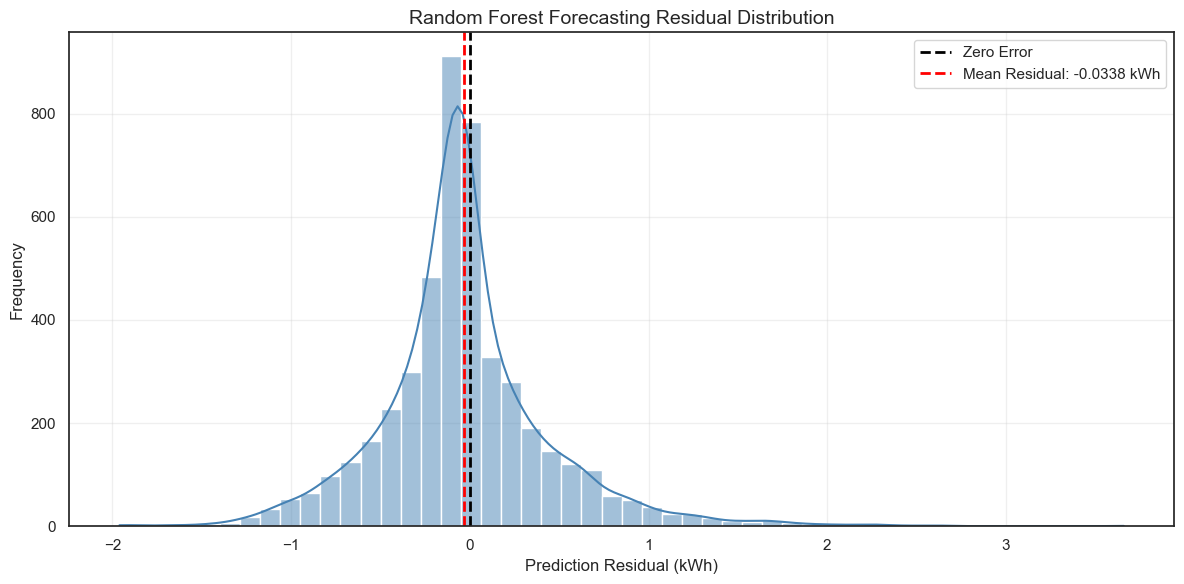

Random Forest residual distribution visualization completed.
Observations analyzed: 4,721
Figure saved to: ../figure/random_forest_residual_distribution.png


In [77]:

# Section 6.8.3 - Forecasting Model Diagnostics - Residual Distribution Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Use previously calculated Random Forest residuals
residuals = rf_error_analysis["Residual_kWh"].dropna()

# Create residual distribution plot
plt.figure(figsize=(12, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True,
    color="steelblue",
    edgecolor="white"
)

# Reference line for perfect predictions
plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

# Reference line for mean residual
plt.axvline(
    residuals.mean(),
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean Residual: {residuals.mean():.4f} kWh"
)

plt.title(
    "Random Forest Forecasting Residual Distribution",
    fontsize=14
)
plt.xlabel("Prediction Residual (kWh)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save figure
figure_path = "../figure/random_forest_residual_distribution.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Random Forest residual distribution visualization completed.")
print(f"Observations analyzed: {len(residuals):,}")
print(f"Figure saved to: {figure_path}")


### Interpretation of Random Forest Residual Distribution

The residual distribution of the Random Forest forecasting model was examined using 4,721 observations from the independent testing dataset.

The histogram reveals a pronounced concentration of residuals around zero, suggesting that the model produces relatively small forecasting errors for many observations. The mean residual of −0.0338 kWh indicates a slight overall tendency to overpredict household electricity consumption.

The distribution is positively skewed, with a skewness coefficient of 0.8172, indicating the presence of occasional large positive residuals. These correspond to periods when actual electricity consumption substantially exceeds predicted consumption.

Furthermore, 62.89% of predictions represent overestimations, while 37.11% represent underestimations. This suggests that although overprediction occurs more frequently, some underprediction errors are comparatively large.

Overall, the residual analysis indicates that the Random Forest model captures typical household electricity consumption patterns reasonably well but remains less accurate during certain periods of unusually high electricity demand. These findings highlight the importance of examining forecasting errors beyond aggregate performance metrics such as MAE, RMSE, and R².

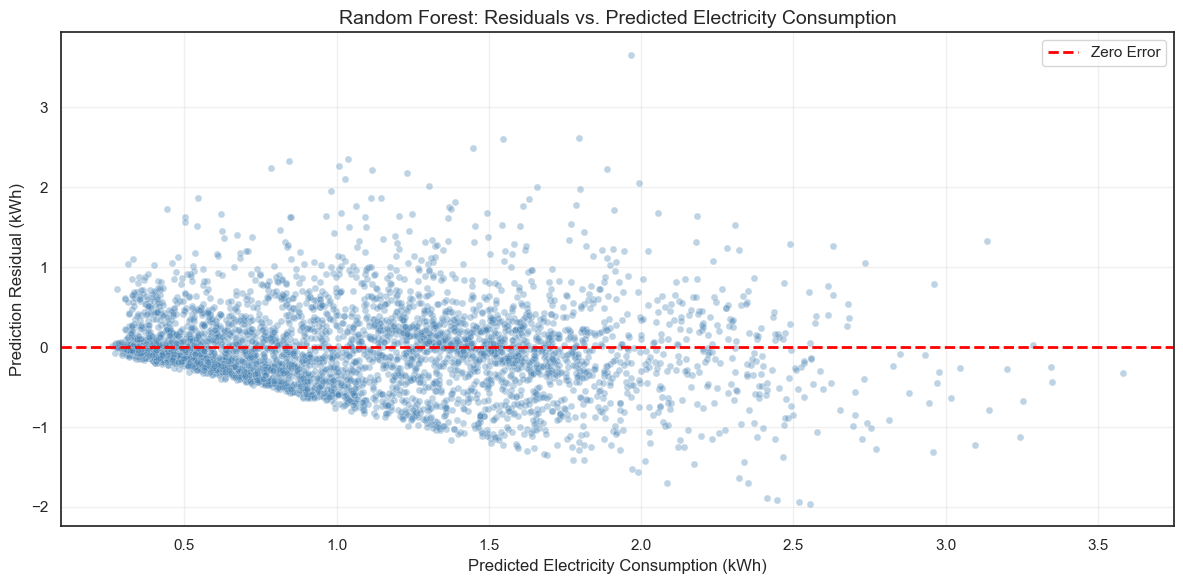

Residuals vs. predicted consumption analysis completed.
Observations analyzed: 4,721
Figure saved to: ../figure/random_forest_residuals_vs_predicted.png


In [78]:

# Section 6.8.4 - Random Forest - Residuals vs. Predicted Consumption

import matplotlib.pyplot as plt
import seaborn as sns

# Use the existing final testing results
residual_plot_data = rf_test_results.copy()

# Calculate residuals: Actual - Predicted
residual_plot_data["Residual_kWh"] = (
    residual_plot_data["Actual_kWh"]
    - residual_plot_data["Predicted_kWh"]
)

# Create residual scatter plot
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=residual_plot_data,
    x="Predicted_kWh",
    y="Residual_kWh",
    alpha=0.35,
    s=25,
    color="steelblue"
)

# Reference line representing zero prediction error
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero Error"
)

plt.title(
    "Random Forest: Residuals vs. Predicted Electricity Consumption",
    fontsize=14
)
plt.xlabel("Predicted Electricity Consumption (kWh)")
plt.ylabel("Prediction Residual (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the visualization
figure_path = "../figure/random_forest_residuals_vs_predicted.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Residuals vs. predicted consumption analysis completed.")
print(f"Observations analyzed: {len(residual_plot_data):,}")
print(f"Figure saved to: {figure_path}")


### Interpretation of Random Forest Residuals vs. Predicted Electricity Consumption

The residuals-versus-predicted consumption plot provides additional insight into the forecasting performance of the Random Forest Regression model on the unseen testing dataset.

The residuals are distributed on both sides of the zero-error reference line, indicating that the model produces both underpredictions and overpredictions.

However, the residuals exhibit a noticeable triangular or fan-shaped distribution, suggesting that prediction error variability changes across predicted electricity consumption levels. This indicates potential heteroscedasticity rather than constant residual variance.

Several large positive residuals are observed, indicating that the model occasionally underestimates actual electricity consumption, particularly during unexpected high-demand events. Negative residuals are also present across the prediction range, reflecting periods of overestimation.

These findings suggest that although Random Forest Regression provides useful forecasting performance, it does not fully capture all variations in household electricity demand. In particular, unusual consumption peaks remain challenging to predict accurately.

Consequently, future model improvements could investigate additional forecasting features, alternative machine learning algorithms, and methods designed to better capture rapid changes in electricity consumption.

### 6.8.2 Random Forest Forecasting Residuals Over Time

This analysis examines how the Random Forest model's prediction errors vary throughout the testing period. The objective is to identify possible temporal patterns, periods of unusually large forecasting errors, and evidence of systematic prediction bias.

Residuals are calculated as the difference between actual and predicted hourly electricity consumption. Positive residuals indicate underprediction, while negative residuals indicate overprediction.

Examining residuals over time helps assess whether the model's forecasting errors are randomly distributed or exhibit persistent patterns that may indicate unmodeled temporal relationships.

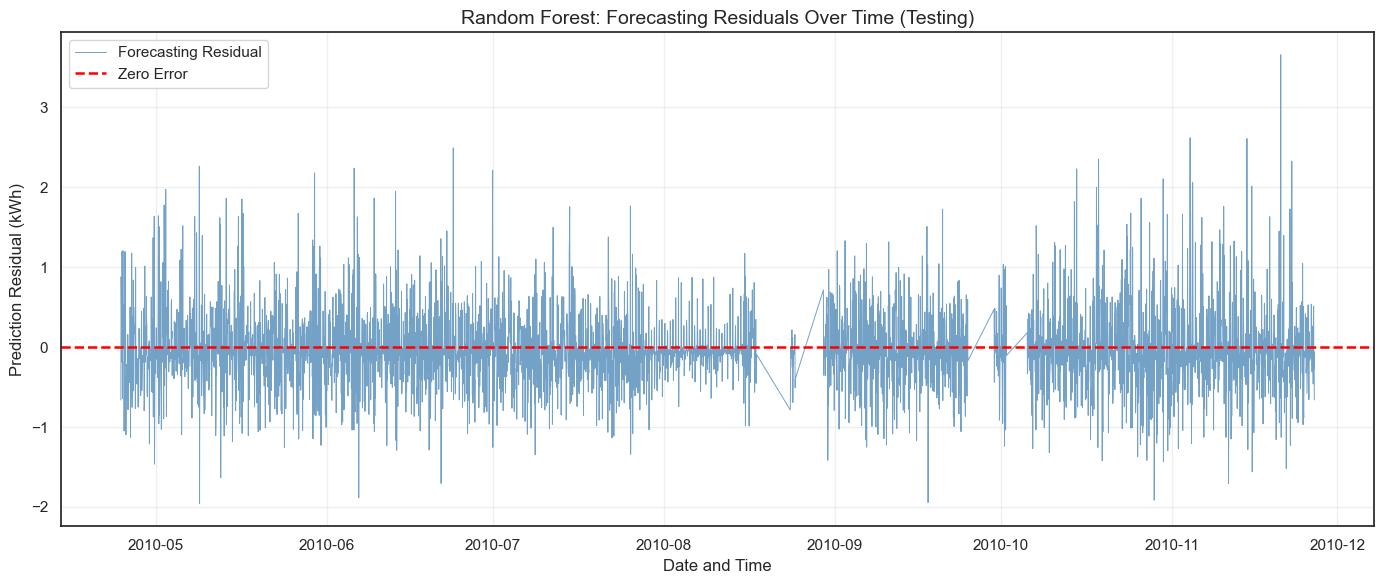

Random Forest residual time-series analysis completed.
Testing observations analyzed: 4,721
Testing period: 2010-04-24 16:00:00 to 2010-11-26 20:00:00
Figure saved to: ../figure/random_forest_residuals_over_time.png


In [79]:

# Section 6.8.5 - Random Forest - Forecasting Residuals Over Time

import matplotlib.pyplot as plt

# Use the existing Random Forest testing results
residual_time_data = rf_test_results.copy()

# Calculate residuals: Actual - Predicted
residual_time_data["Residual_kWh"] = (
    residual_time_data["Actual_kWh"]
    - residual_time_data["Predicted_kWh"]
)

# Sort observations chronologically
residual_time_data = residual_time_data.sort_index()

# Create the residual time-series visualization
plt.figure(figsize=(14, 6))

plt.plot(
    residual_time_data.index,
    residual_time_data["Residual_kWh"],
    color="steelblue",
    linewidth=0.7,
    alpha=0.75,
    label="Forecasting Residual"
)

# Zero-error reference line
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.8,
    label="Zero Error"
)

plt.title(
    "Random Forest: Forecasting Residuals Over Time (Testing)",
    fontsize=14
)
plt.xlabel("Date and Time")
plt.ylabel("Prediction Residual (kWh)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save the figure
figure_path = "../figure/random_forest_residuals_over_time.png"
plt.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Random Forest residual time-series analysis completed.")
print(f"Testing observations analyzed: {len(residual_time_data):,}")
print(f"Testing period: {residual_time_data.index.min()} to {residual_time_data.index.max()}")
print(f"Figure saved to: {figure_path}")


### Interpretation of Random Forest Forecasting Residuals Over Time

The time-series visualization examines the forecasting residuals of the Random Forest Regression model across 4,721 observations in the unseen testing dataset, covering April 24 to November 26, 2010.

The residuals fluctuate around the zero-error reference line, indicating that the model produces both underpredictions and overpredictions throughout the testing period.

However, the magnitude of forecasting errors varies over time. Several periods exhibit relatively small residuals, while others contain substantial positive and negative deviations. This suggests that forecasting accuracy is not uniform throughout the testing period.

Large positive residuals are particularly noticeable toward the end of the testing period, indicating occasional underprediction of elevated household electricity consumption.

The visualization also contains gaps and connecting segments that may reflect missing or excluded observations in the hourly dataset. These features should be interpreted cautiously because the plotted observations may not represent an uninterrupted hourly sequence.

Overall, the results indicate that Random Forest Regression captures important temporal consumption patterns but remains susceptible to forecasting errors during unusual demand events.

Further improvements could investigate additional temporal features and alternative forecasting methods. A formal residual autocorrelation analysis would be required to determine whether systematic temporal dependence remains in the prediction errors.

## 7.0 Final Conclusions and Recommendations

This section summarizes the major findings of the Household Electricity Consumption Analysis and Forecasting project, including the observed electricity consumption patterns, forecasting model performance, and limitations identified during model evaluation.

The analysis was conducted using historical household electricity consumption data covering December 2006 to November 2010. Three forecasting approaches were evaluated: Persistence Baseline, Linear Regression, and Random Forest Regression.

The section presents the main conclusions drawn from the exploratory data analysis, model validation, final testing, and forecasting residual diagnostics. It also outlines recommendations for improving future household electricity demand forecasting.


### 7.1 Key Findings from Electricity Consumption Analysis

The exploratory data analysis revealed several important characteristics of household electricity consumption between December 2006 and November 2010.

**1. Variability in Electricity Consumption**

Hourly electricity consumption exhibited substantial variability, with an average of approximately 1.091 kWh and a median of 0.803 kWh across 34,139 complete hourly observations.

The difference between the mean and median indicates a positively skewed consumption distribution, suggesting that relatively high-consumption periods influence the overall average.

**2. Daily and Hourly Consumption Patterns**

The hourly consumption analysis identified variations in electricity demand throughout the day, reflecting changes in household electricity usage across different hours.

These temporal patterns demonstrate the importance of incorporating hour-of-day information into electricity demand forecasting.

**3. Weekday and Weekend Consumption Patterns**

The analysis examined differences between weekday and weekend electricity consumption profiles, highlighting the relevance of calendar-based features when forecasting household electricity demand.

**4. Seasonal Electricity Consumption Patterns**

Electricity consumption was also analyzed across different seasons to investigate variations in household demand over the year.

These findings support the inclusion of historical consumption measurements and seasonal or calendar-related information in forecasting models.

**5. High-Consumption Events**

The hourly consumption distribution revealed occasional periods of unusually high electricity demand. These observations may represent genuine household consumption events rather than measurement errors.

Such periods are particularly important for forecasting because sudden increases in demand can produce larger prediction errors.

**Overall Finding**

Household electricity consumption exhibits temporal variability, a positively skewed distribution, and occasional high-demand events. These characteristics provide the foundation for developing forecasting models that incorporate historical electricity consumption and calendar-based predictors.



### 7.2 Key Findings from Forecasting Model Development and Evaluation

**1. Forecasting Models Developed**

Three forecasting approaches were implemented and evaluated:

- **Persistence Baseline:** Uses the previous hour's electricity consumption as the forecast.
- **Linear Regression:** Estimates electricity consumption using historical consumption and calendar-based predictors.
- **Random Forest Regression:** Uses an ensemble of decision trees to capture nonlinear relationships between historical electricity consumption and temporal features.

All three models were evaluated using the same validation dataset to ensure a consistent performance comparison.

**2. Validation Performance Comparison**

The forecasting models produced the following validation results:

| Model | MAE (kWh) | RMSE (kWh) | R² |
|---|---:|---:|---:|
| Persistence Baseline | 0.4619 | 0.6884 | 0.3965 |
| Linear Regression | 0.4176 | 0.5896 | 0.5573 |
| Random Forest Regression | **0.3768** | **0.5479** | **0.6178** |

Random Forest Regression achieved the lowest Mean Absolute Error (MAE), lowest Root Mean Squared Error (RMSE), and highest coefficient of determination (R²).

Compared with Linear Regression, Random Forest reduced validation MAE by approximately 9.77% and RMSE by approximately 7.08%.

These results established Random Forest Regression as the best-performing model on the validation dataset.

**3. Final Evaluation on Unseen Testing Data**

After model selection, Random Forest Regression was evaluated on 4,721 unseen hourly observations covering April 24 to November 26, 2010.

The final testing results were:

- **MAE:** 0.3275 kWh
- **RMSE:** 0.4750 kWh
- **R²:** 0.5499

The testing R² indicates that the model explained approximately 55% of the variation in hourly household electricity consumption during the testing period.

The results demonstrate useful predictive capability on unseen data, although forecasting errors remain.

**4. Forecasting Residual Analysis**

Residual diagnostics revealed that the Random Forest model produced both overpredictions and underpredictions.

The residual distribution exhibited positive skewness, indicating occasional relatively large underprediction errors.

The residual-versus-predicted visualization also showed variations in error magnitude across predicted consumption levels.

Additionally, the residual time-series visualization revealed that forecasting errors varied throughout the testing period, with occasional substantial deviations.

These findings indicate that Random Forest captures important electricity consumption patterns but remains less accurate during unusual demand events.

**5. Overall Model Evaluation Conclusion**

Random Forest Regression was the strongest of the three evaluated forecasting approaches based on validation performance.

Its final testing results demonstrate that historical electricity consumption and calendar-based features can provide useful information for predicting hourly household electricity demand.

However, the model does not explain all observed consumption variability, highlighting opportunities for further improvement.



### Project Limitations and Recommendations for Future Improvements

#### 1. Project Limitations

Although the analysis produced useful insights and forecasting results, several limitations should be acknowledged.

**Limited Dataset Scope**

The analysis was based on electricity consumption measurements from a single household between December 2006 and November 2010.

Consequently, the findings may not generalize directly to households with different electricity usage patterns, geographical locations, or appliance characteristics.

**Missing and Excluded Observations**

The original dataset contained missing measurements, requiring data cleaning and completeness checks.

Some observations were excluded during preprocessing and hourly aggregation. These exclusions may affect the continuity and representativeness of the resulting time series.

**Limited Explanatory Features**

The forecasting models primarily relied on historical electricity consumption and calendar-based variables, including hour, day of the week, month, and weekend indicators.

Potentially relevant external factors, such as weather conditions, household occupancy, appliance operation, and electricity tariffs, were not incorporated.

**Difficulty Forecasting Unusual Consumption Events**

Residual diagnostics identified occasional substantial prediction errors, particularly during periods of elevated electricity consumption.

This indicates that the selected Random Forest model does not consistently capture sudden or unusual changes in household electricity demand.

**Remaining Unexplained Variability**

The final Random Forest testing R² of 0.5499 indicates that approximately 45% of the variation in electricity consumption remained unexplained by the model during the testing period.

This highlights the complexity of household electricity demand and the limitations of the available predictors.

#### 2. Recommendations for Future Improvements

**Incorporate Additional Explanatory Variables**

Future studies could investigate the inclusion of temperature, weather conditions, household occupancy, and appliance-level electricity consumption where such data are available.

**Explore Additional Forecasting Approaches**

Alternative forecasting methods, including gradient boosting algorithms and sequence-based neural networks, could be evaluated against the existing baseline, Linear Regression, and Random Forest models.

**Improve Forecasting of High-Demand Events**

Future model development could focus on improving prediction accuracy during unusually high electricity consumption periods.

**Investigate Residual Autocorrelation**

A formal autocorrelation analysis of forecasting residuals could help determine whether additional temporal relationships remain unexplained.

**Evaluate Model Generalization Across Households**

Applying the forecasting framework to additional households and different observation periods would provide a stronger assessment of model generalizability.

#### 3. Final Project Conclusion

This project demonstrated how historical household electricity consumption data can be transformed into meaningful insights and used to develop hourly electricity demand forecasting models.

Three forecasting approaches were evaluated, with Random Forest Regression achieving the strongest validation performance.

The selected model also demonstrated useful predictive capability on unseen testing data, achieving an MAE of 0.3275 kWh, RMSE of 0.4750 kWh, and R² of 0.5499.

Although the model remains susceptible to errors during unusual consumption events, the findings establish a practical foundation for further development of household electricity demand forecasting systems.


In [89]:
import os

print("Jupyter working directory:")
print(os.getcwd())

Jupyter working directory:
C:\Users\USER\Desktop\ECE M2\M2 Sem 1\BIG DATA & ENERGY DATA ANALYSIS\Personal Projects\Household Electricity Consumption Analysis and Forecasting\notebook
